In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0002
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 232,833
Discriminator parameters: 138,689
Generator learning rate: 0.0002
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(16, 1, 1))
    (1): ConvTranspose2d(16, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.452319	G_loss: 0.971077
Epoch: 1 [6400/60000 (11%)]	D_loss: 0.255939	G_loss: 2.629178
Epoch: 1 [12800/60000 (21%)]	D_loss: 0.586714	G_loss: 2.272442
Epoch: 1 [19200/60000 (32%)]	D_loss: 0.478303	G_loss: 1.545775
Epoch: 1 [25600/60000 (43%)]	D_loss: 0.715725	G_loss: 2.753926
Epoch: 1 [32000/60000 (53%)]	D_loss: 0.677193	G_loss: 1.989037
Epoch: 1 [38400/60000 (64%)]	D_loss: 0.747309	G_loss: 1.359442
Epoch: 1 [44800/60000 (75%)]	D_loss: 0.728058	G_loss: 1.465733
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.744146	G_loss: 1.006934
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.778074	G_loss: 1.435118
====> Epoch: 1 Train D_loss: 0.6539, Train G_loss: 1.7177
====> Epoch: 1 Val D_loss: 1.0997, Val G_loss: 1.2508
📈 Epoch 1 Summary:
   Train D Loss: 0.6539, Val D Loss: 1.0997
   Train G Loss: 1.7177, Val G Loss: 1.2508

📊 Epoch 2/100
------------------------

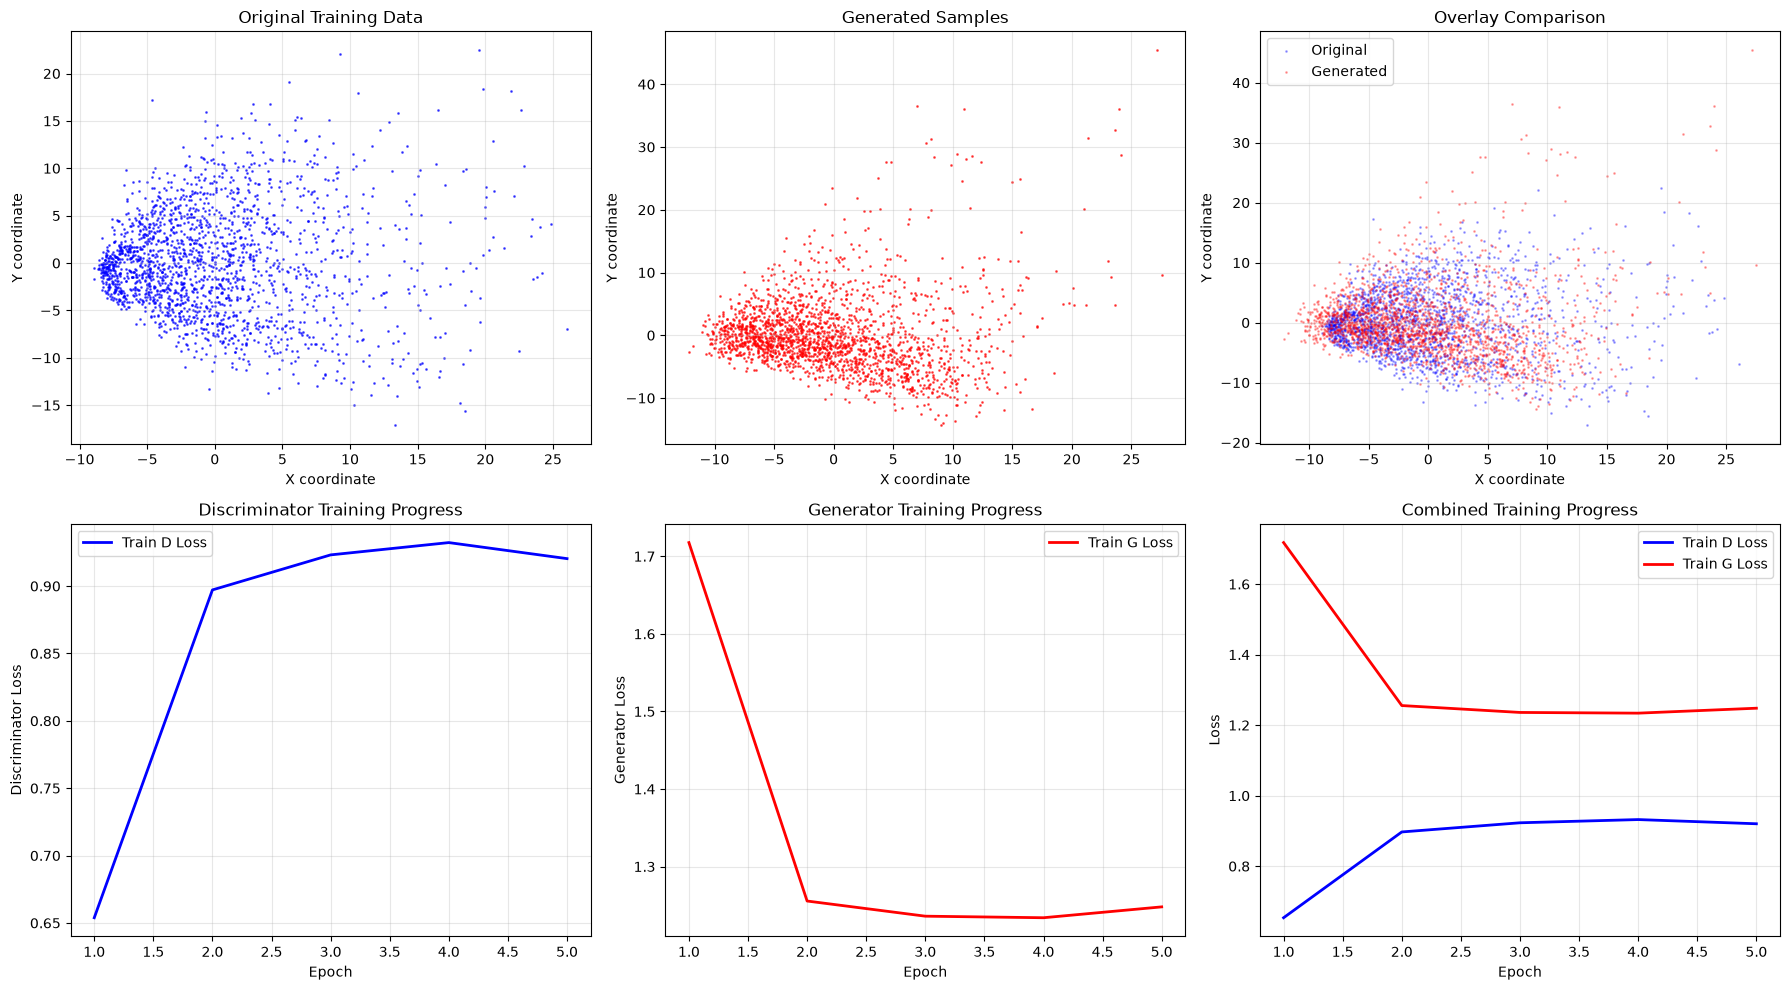

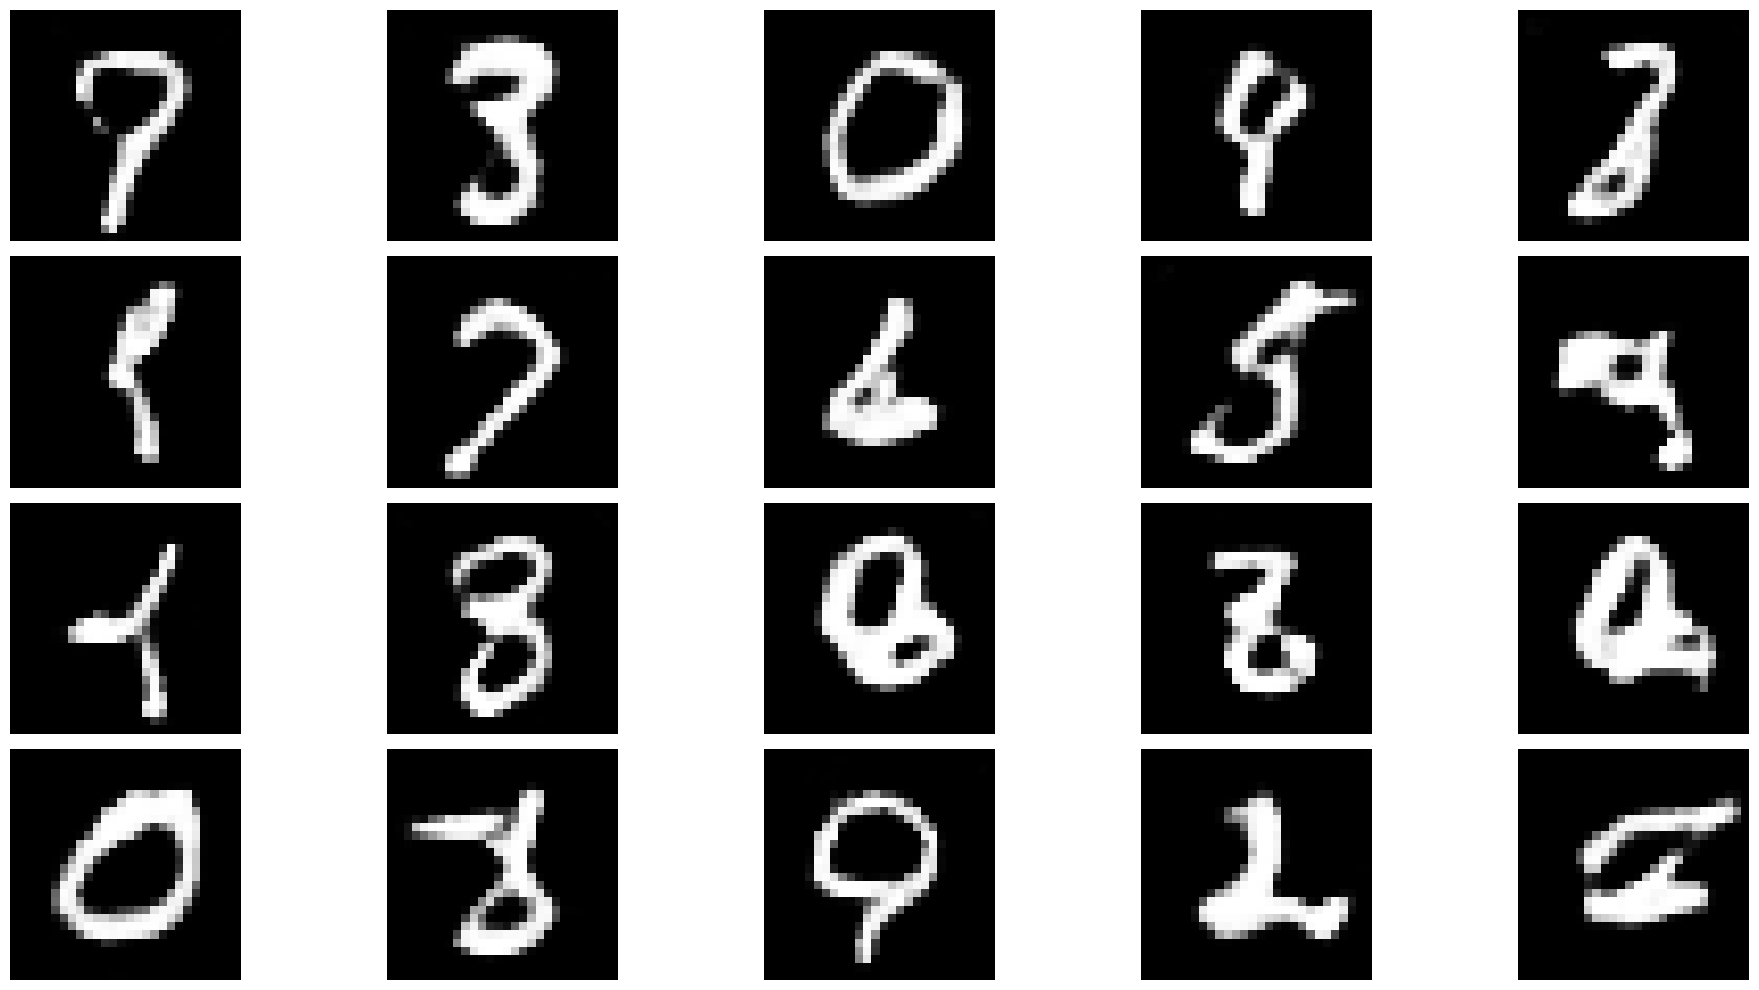

📈 Epoch 5 Summary:
   Train D Loss: 0.9204, Val D Loss: 1.0869
   Train G Loss: 1.2480, Val G Loss: 1.1562

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.821986	G_loss: 1.056924
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.083361	G_loss: 0.350781
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.858379	G_loss: 0.685315
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.988108	G_loss: 1.166894
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.939580	G_loss: 1.748113
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.811118	G_loss: 1.602338
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.909690	G_loss: 1.190906
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.884662	G_loss: 0.938443
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.933767	G_loss: 1.552585
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.807667	G_loss: 1.109560
====> Epoch: 6 Train D_loss: 0.8928, Train G_loss: 1.2776
====> Epoch: 6 Val D_loss: 1.0658, Val G_loss: 1.0461
📈 Epoch 6 Summary:
   Train D Loss: 0.8928, Val D Loss: 1.0658
   Train G Loss: 1.2776, Val G Loss: 1

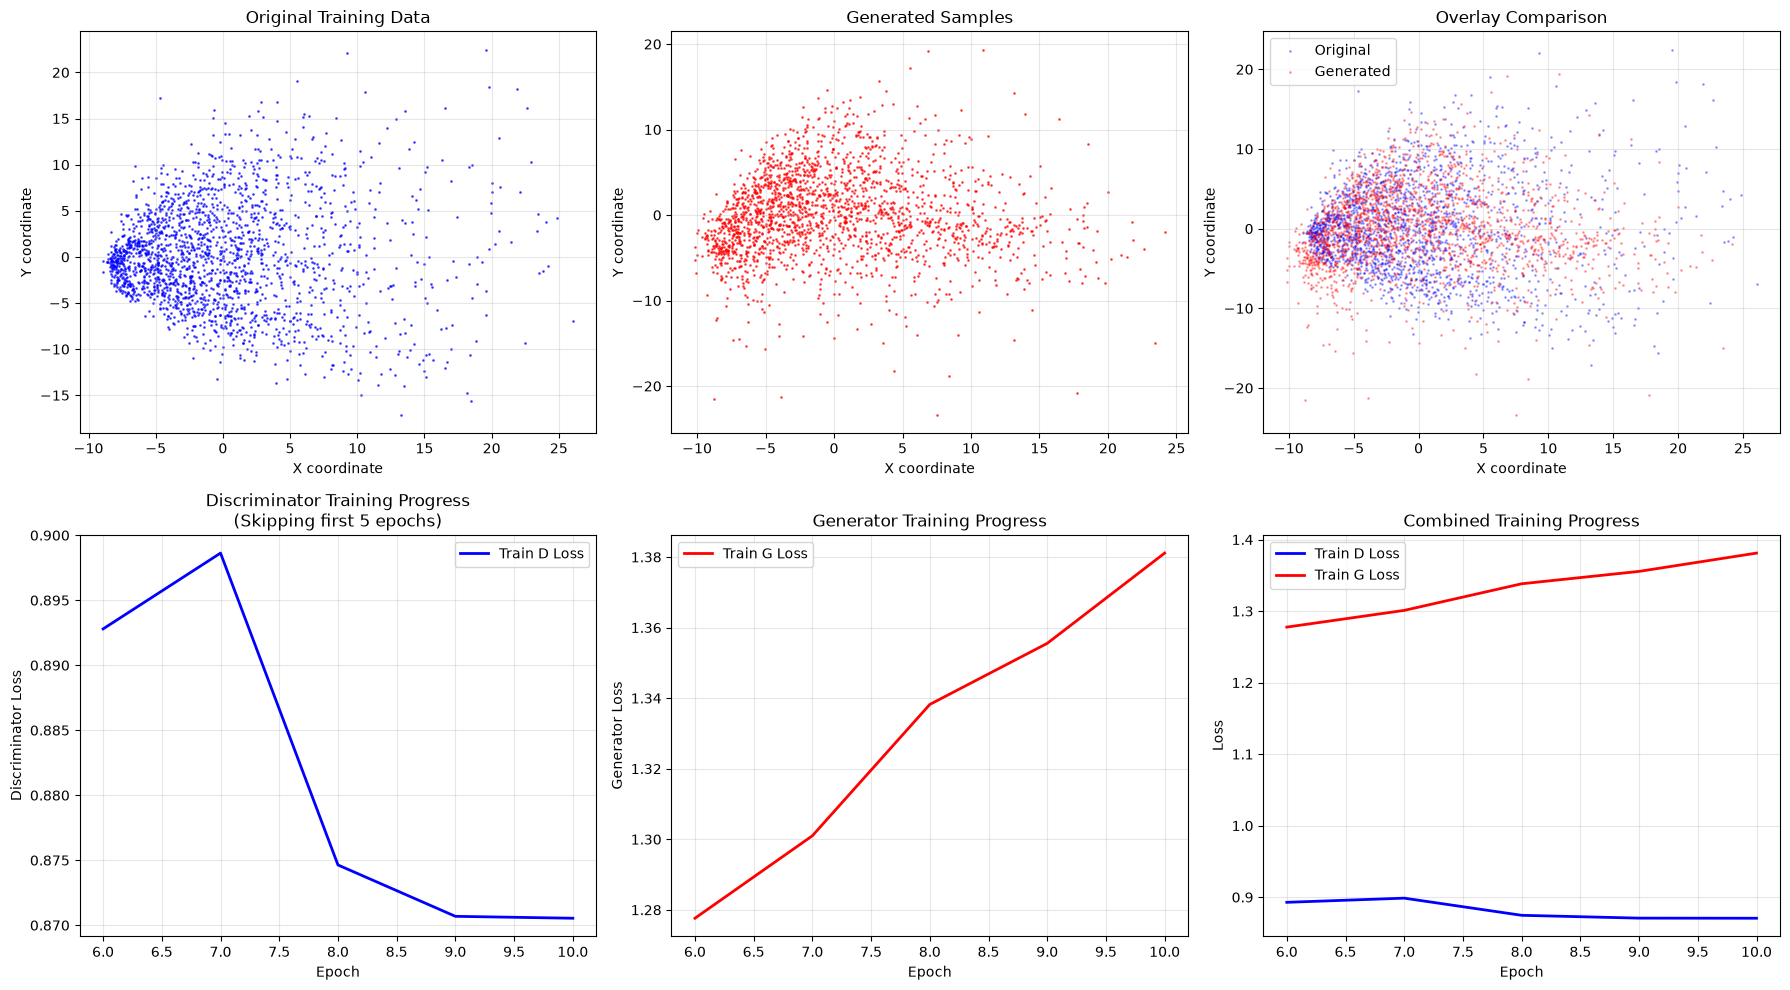

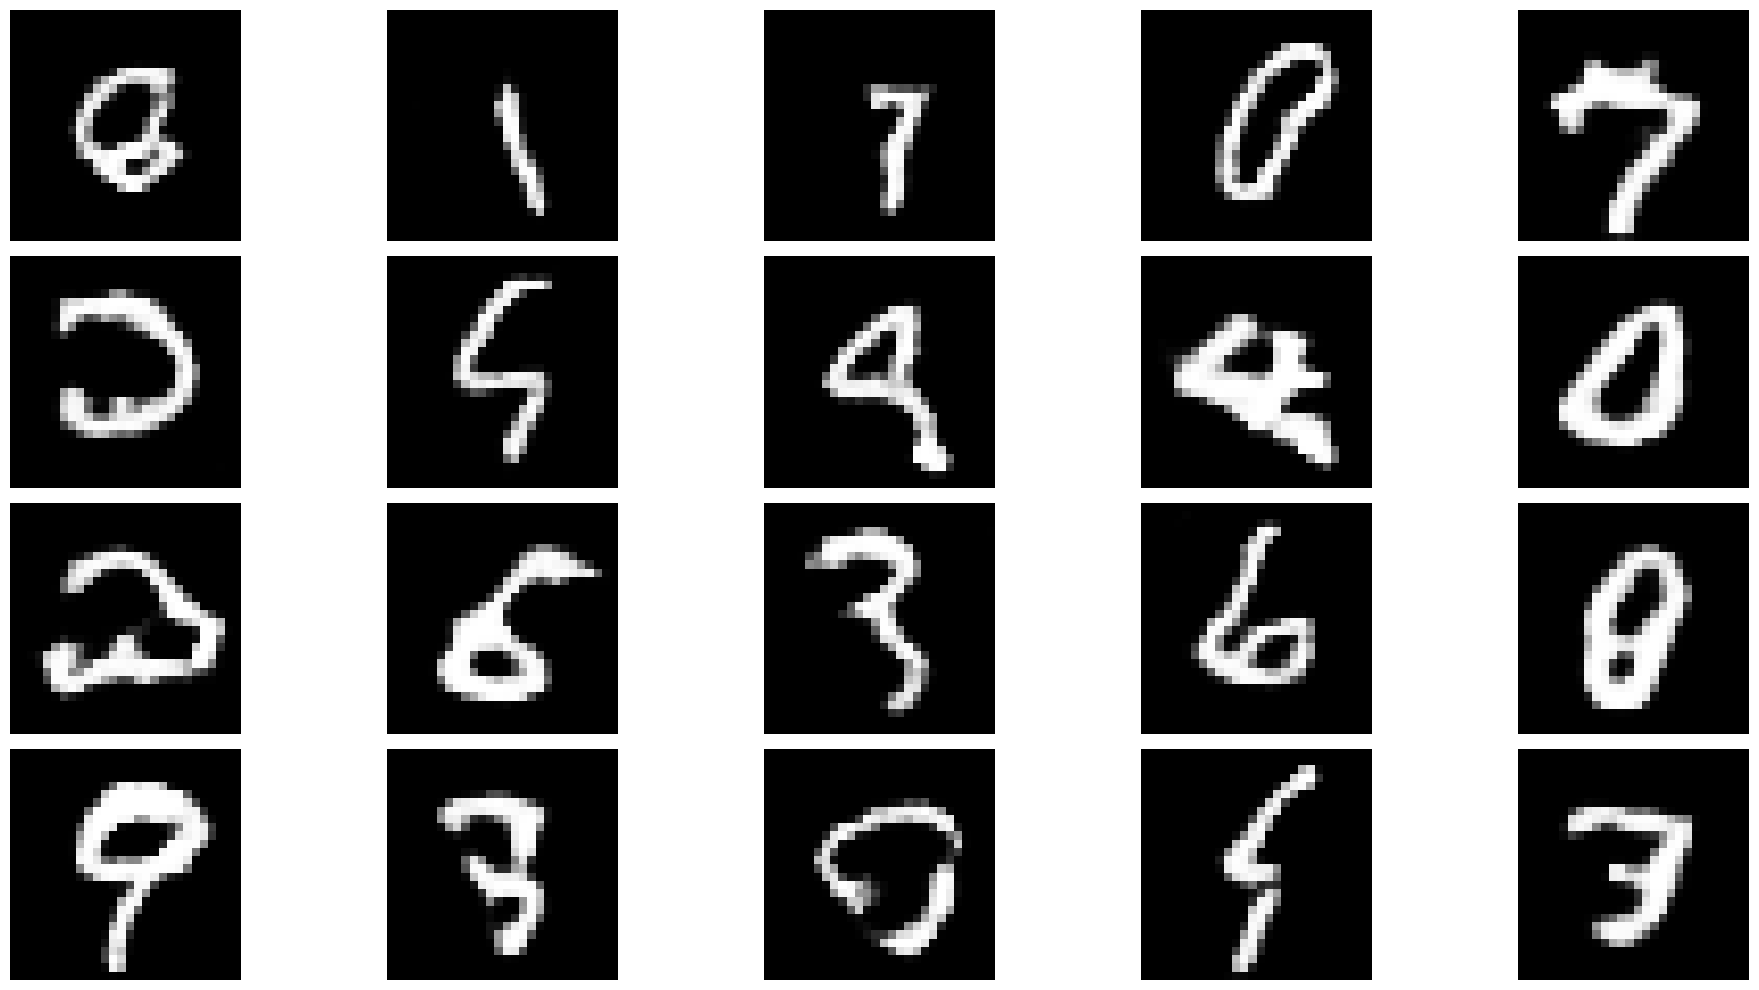

📈 Epoch 10 Summary:
   Train D Loss: 0.8705, Val D Loss: 1.1278
   Train G Loss: 1.3811, Val G Loss: 0.7196

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.834457	G_loss: 1.508139
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.974256	G_loss: 1.951531
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.794909	G_loss: 1.164940
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.886478	G_loss: 0.965412
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.924511	G_loss: 1.263381
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.749386	G_loss: 1.072040
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.820297	G_loss: 1.329039
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.941157	G_loss: 1.375121
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.821309	G_loss: 1.919135
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.963659	G_loss: 0.599655
====> Epoch: 11 Train D_loss: 0.8469, Train G_loss: 1.3938
====> Epoch: 11 Val D_loss: 1.1459, Val G_loss: 0.6649
📈 Epoch 11 Summary:
   Train D Loss: 0.8469, Val D Loss: 1.1459
   Train G Loss: 1.3938

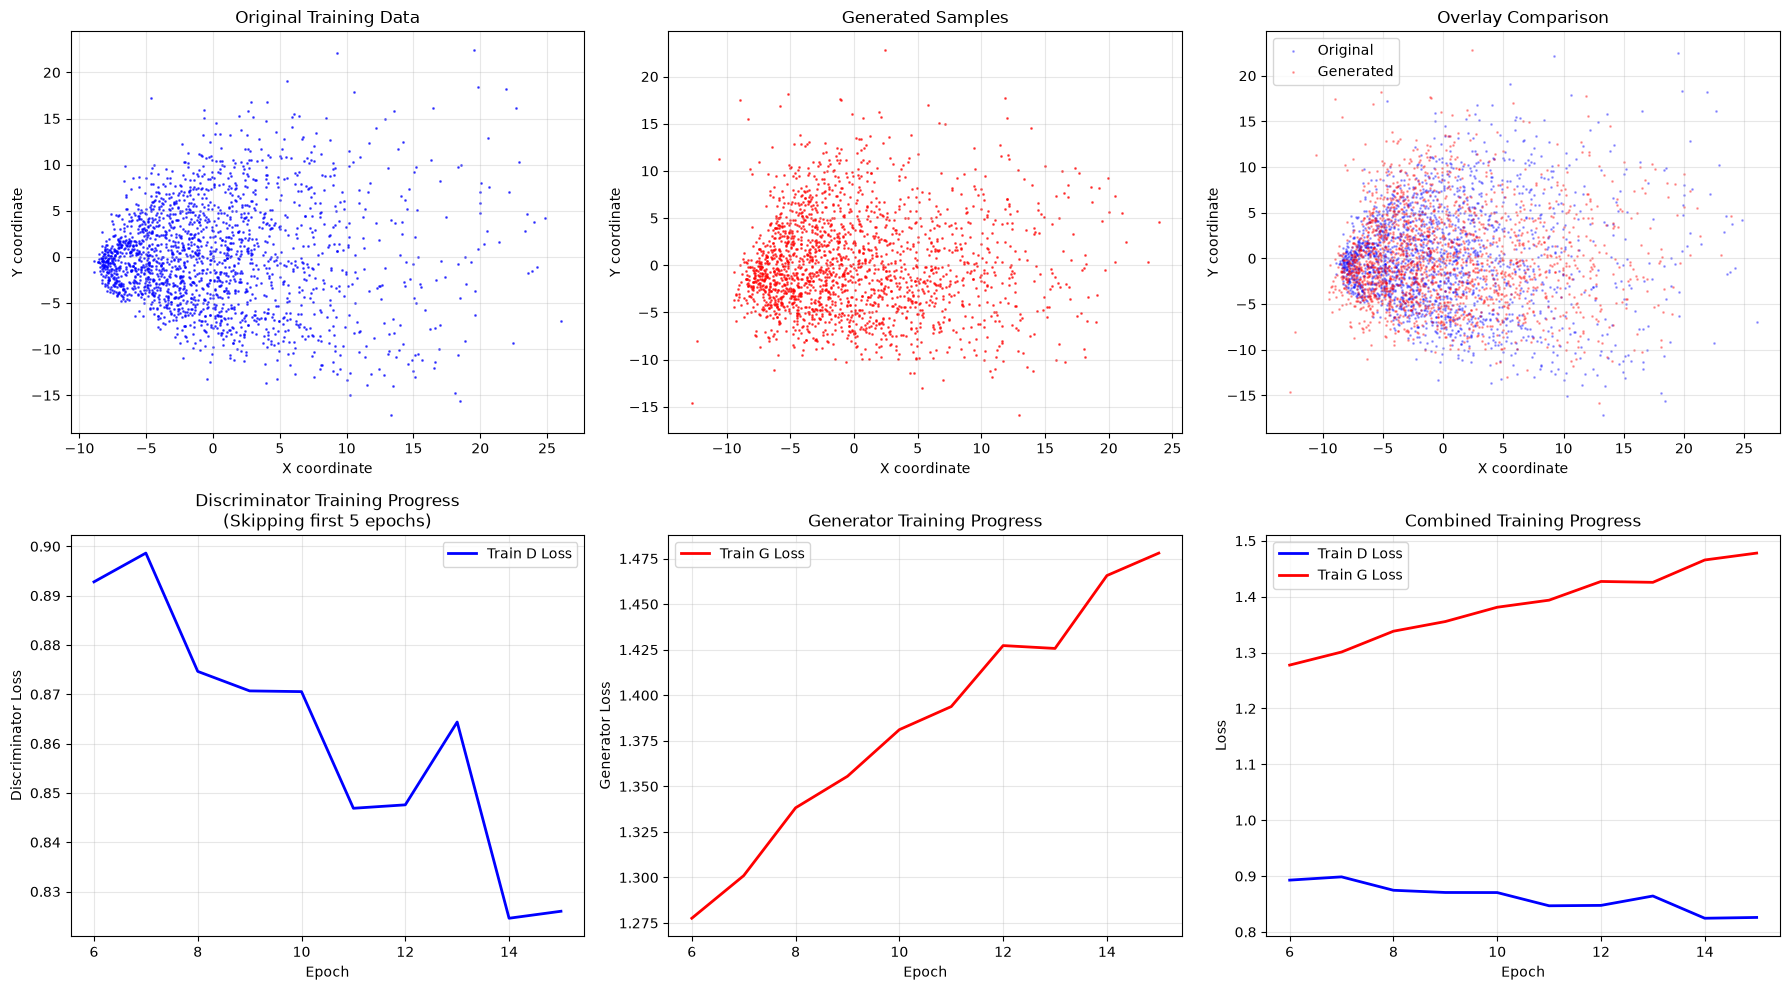

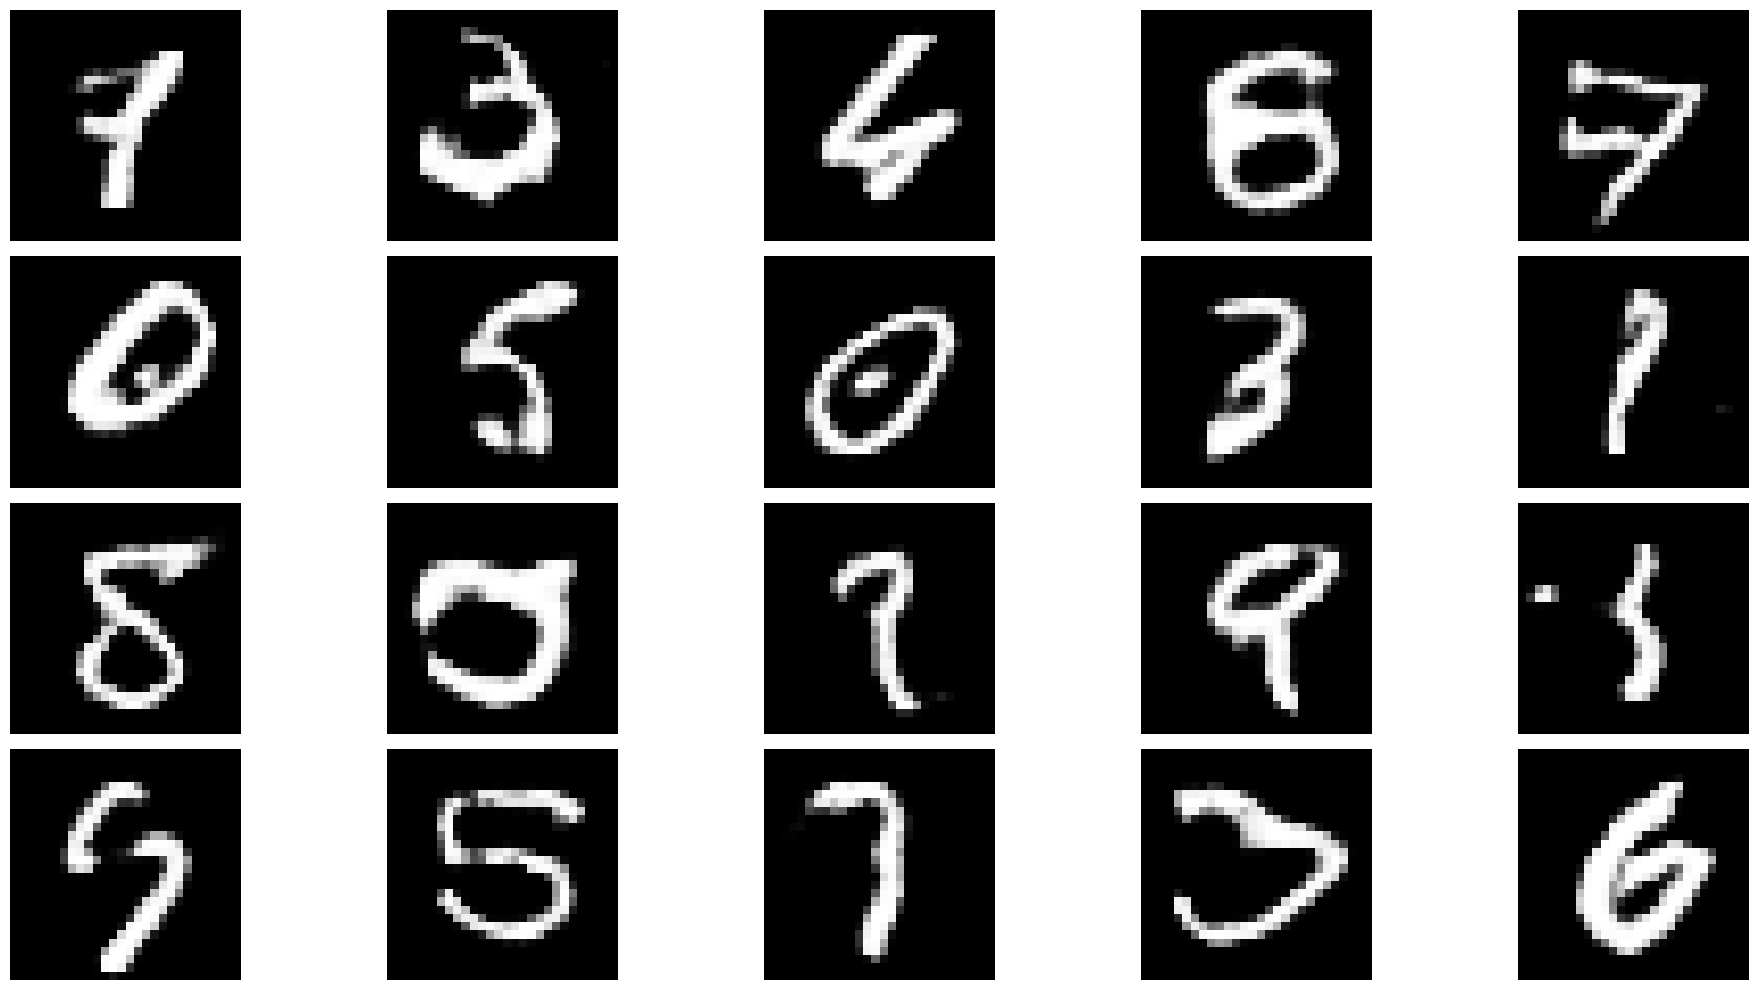

📈 Epoch 15 Summary:
   Train D Loss: 0.8260, Val D Loss: 1.0226
   Train G Loss: 1.4780, Val G Loss: 1.3371

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.785742	G_loss: 0.899055
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.770143	G_loss: 1.700344
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.821538	G_loss: 0.942432
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.943073	G_loss: 1.513522
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.849903	G_loss: 1.154167
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.789765	G_loss: 1.546805
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.782925	G_loss: 1.148972
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.049226	G_loss: 0.735520
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.889255	G_loss: 1.825183
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.840789	G_loss: 1.544064
====> Epoch: 16 Train D_loss: 0.8145, Train G_loss: 1.5046
====> Epoch: 16 Val D_loss: 1.0134, Val G_loss: 1.2489
📈 Epoch 16 Summary:
   Train D Loss: 0.8145, Val D Loss: 1.0134
   Train G Loss: 1.5046

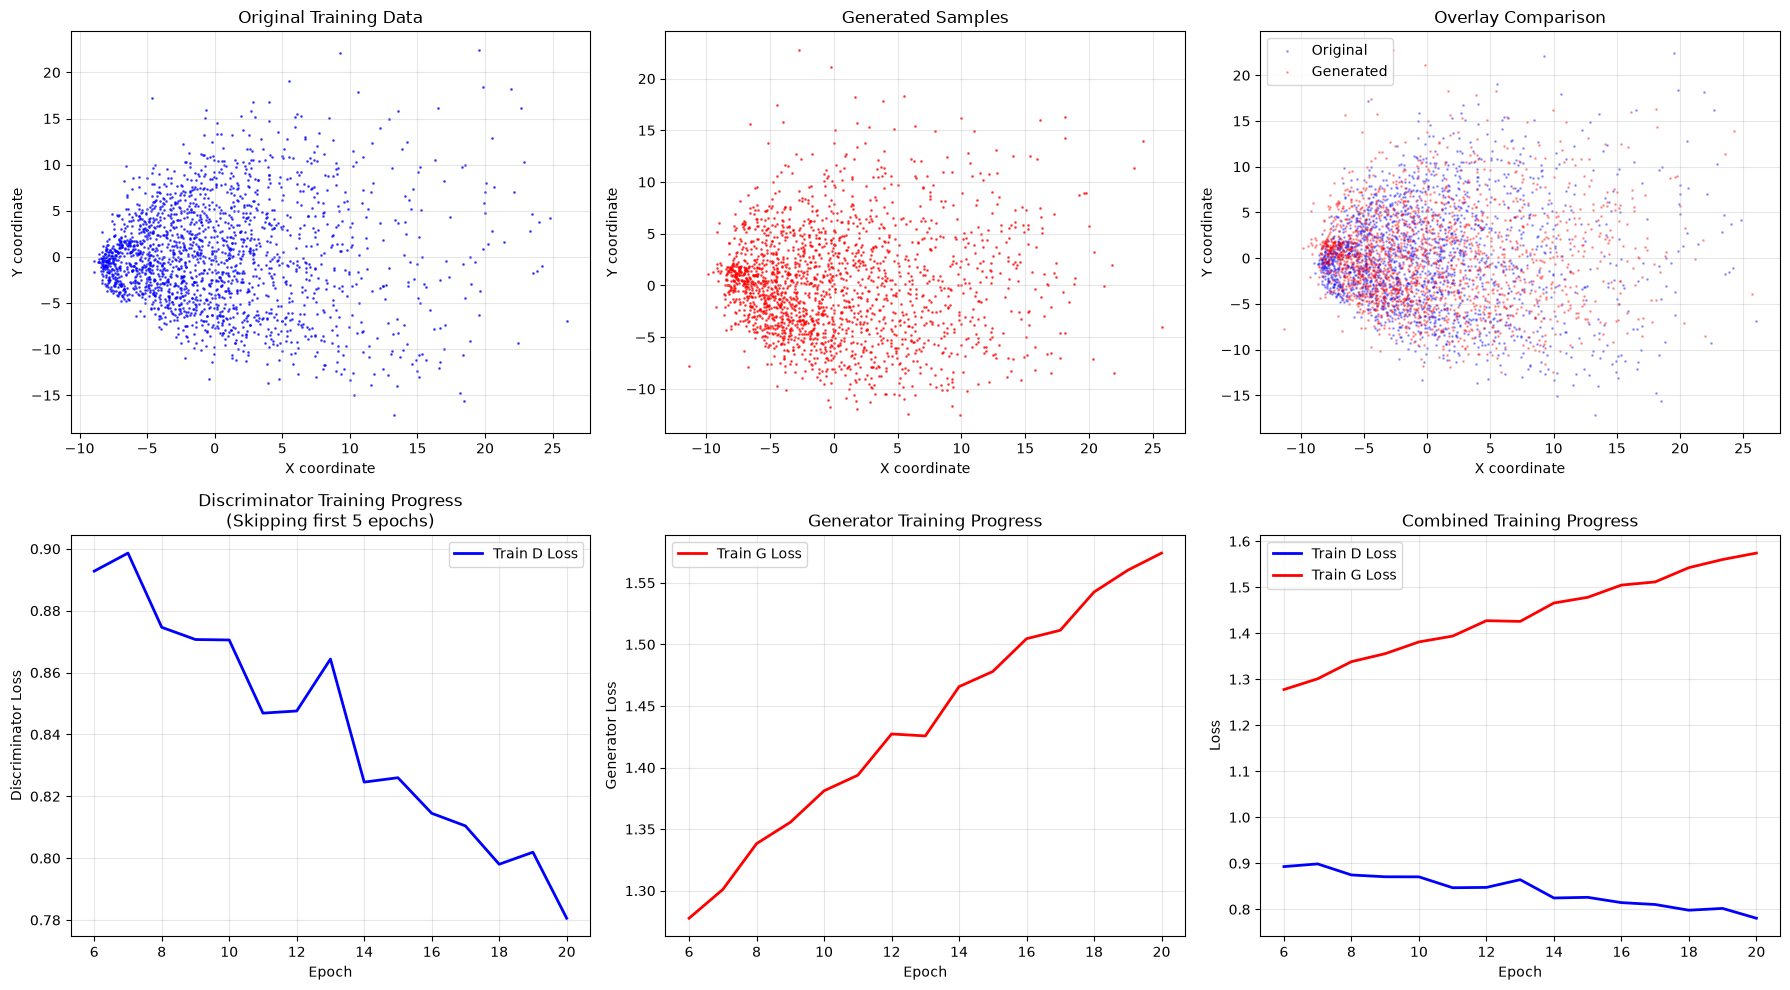

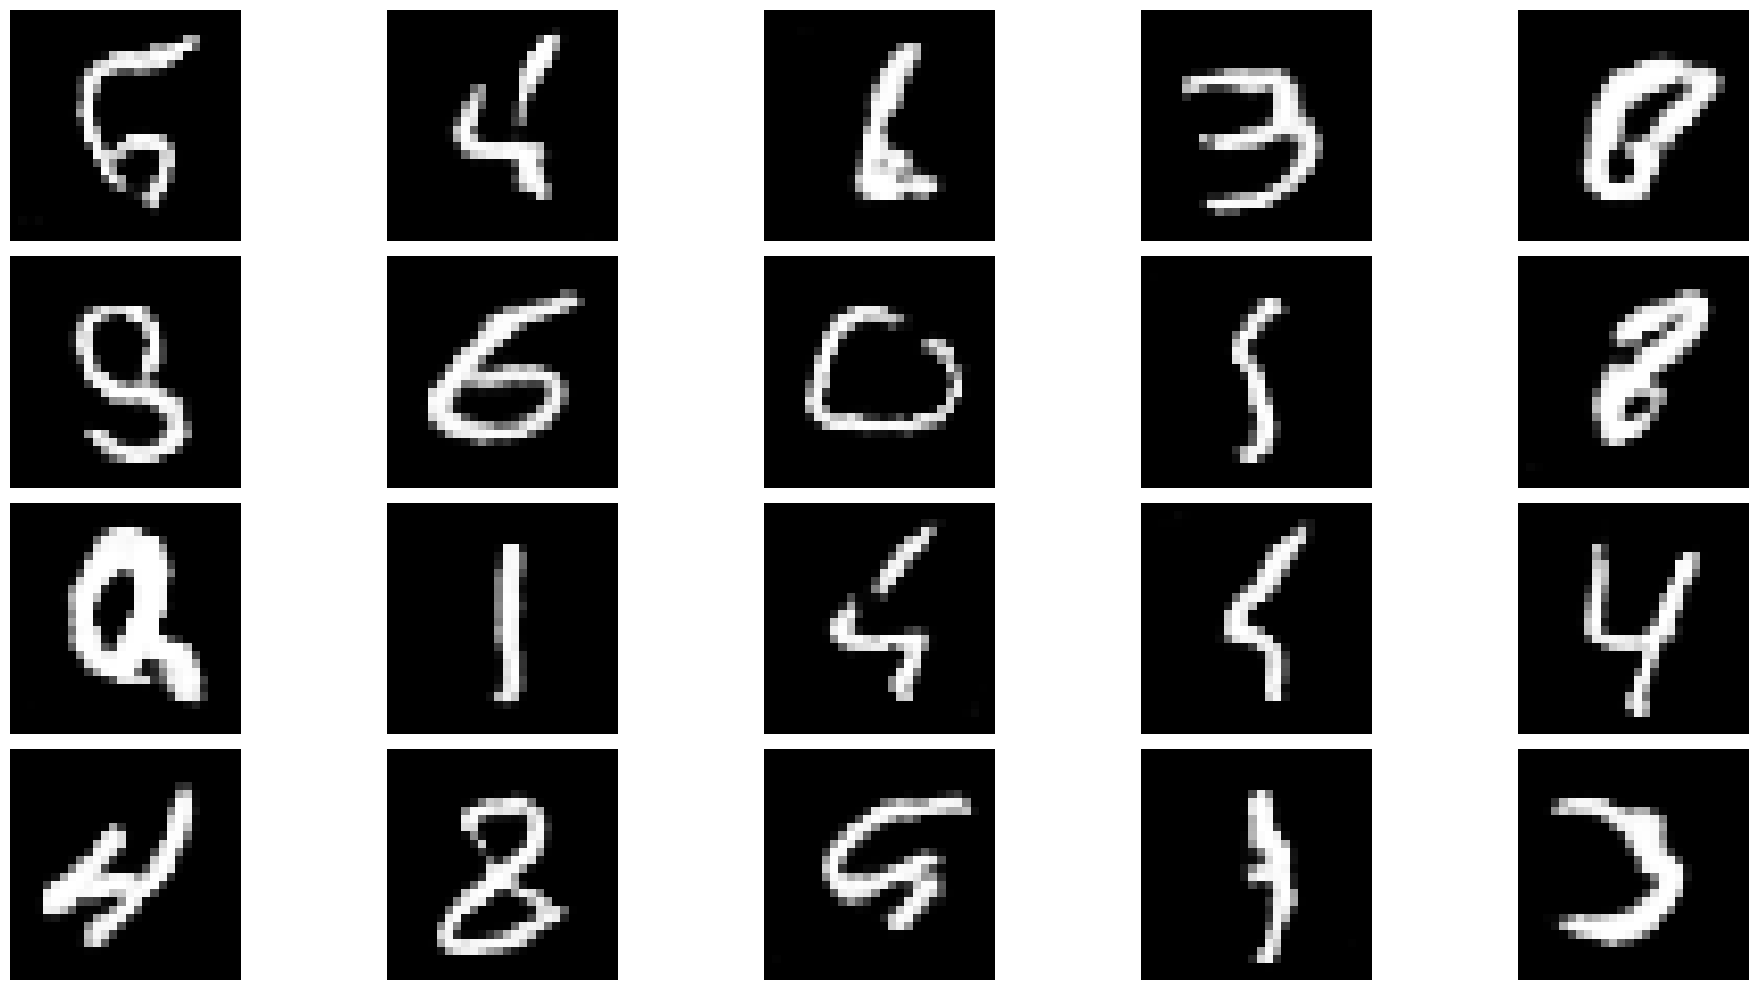

📈 Epoch 20 Summary:
   Train D Loss: 0.7806, Val D Loss: 1.2191
   Train G Loss: 1.5742, Val G Loss: 2.1062

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.754071	G_loss: 1.364809
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.688654	G_loss: 1.622430
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.678514	G_loss: 1.187986
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.763185	G_loss: 1.618590
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.908290	G_loss: 0.950954
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.732547	G_loss: 1.708546
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.853160	G_loss: 2.563363
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.761608	G_loss: 1.099015
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.767561	G_loss: 2.603678
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.831034	G_loss: 2.171016
====> Epoch: 21 Train D_loss: 0.7784, Train G_loss: 1.5937
====> Epoch: 21 Val D_loss: 1.0819, Val G_loss: 1.6359
📈 Epoch 21 Summary:
   Train D Loss: 0.7784, Val D Loss: 1.0819
   Train G Loss: 1.5937

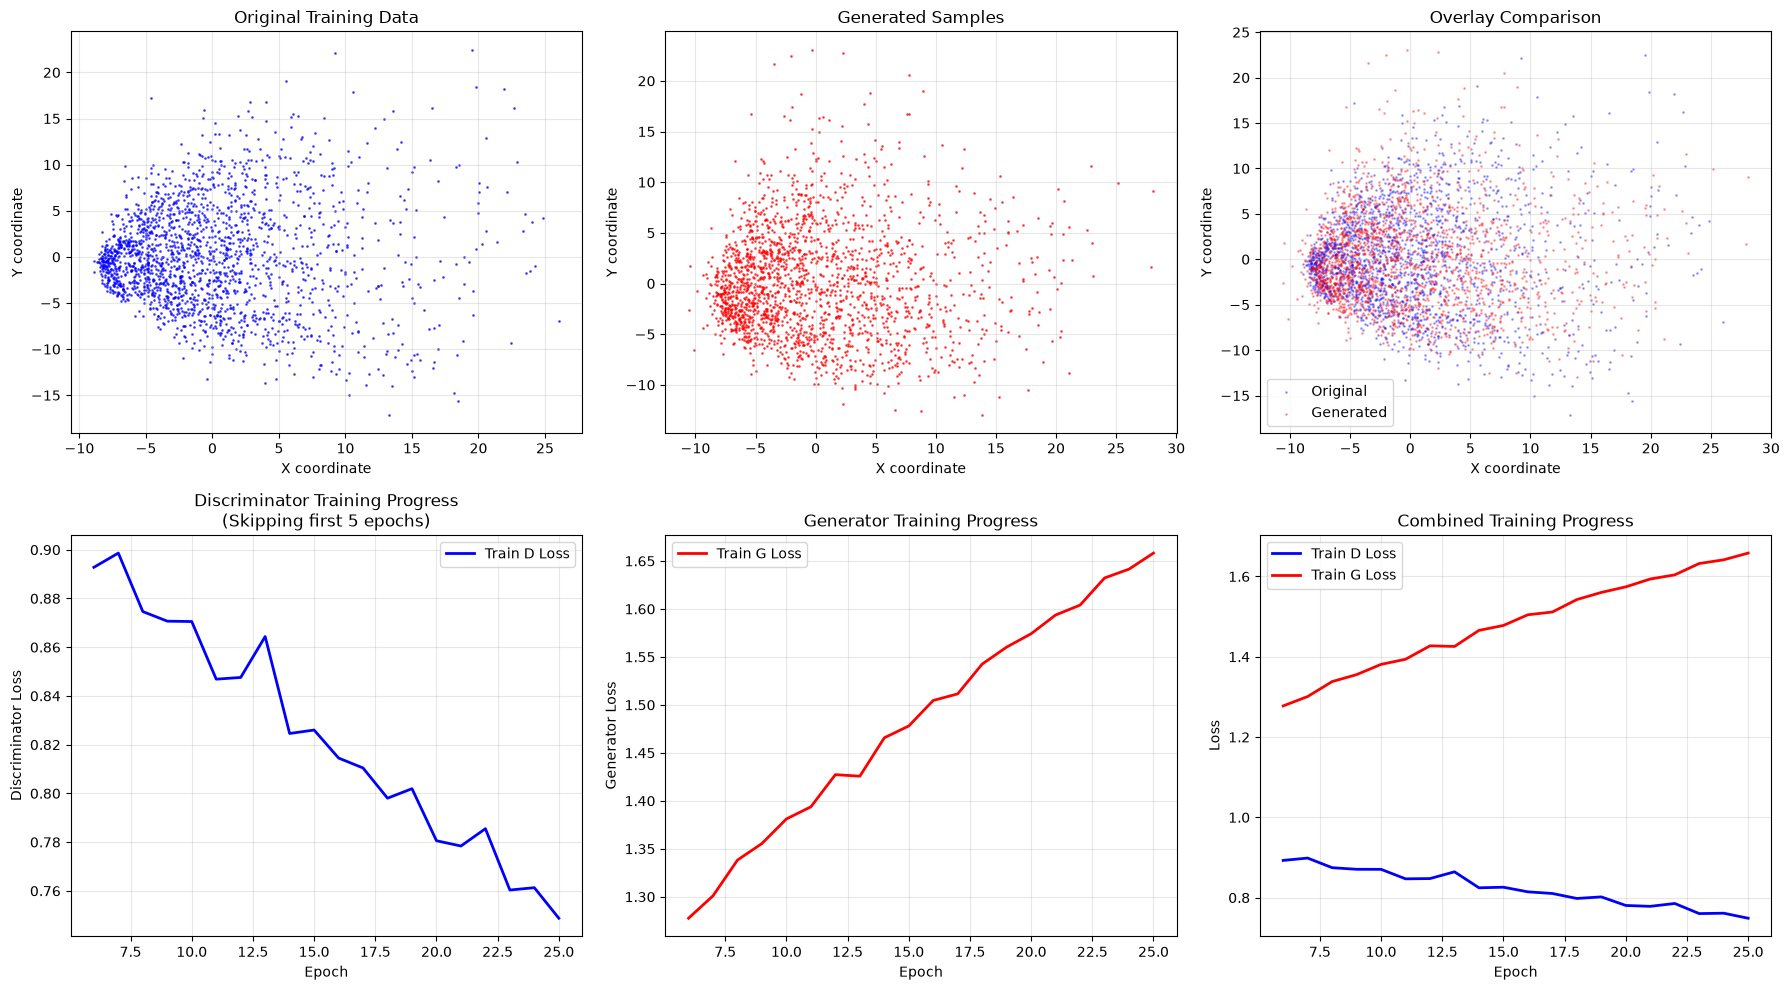

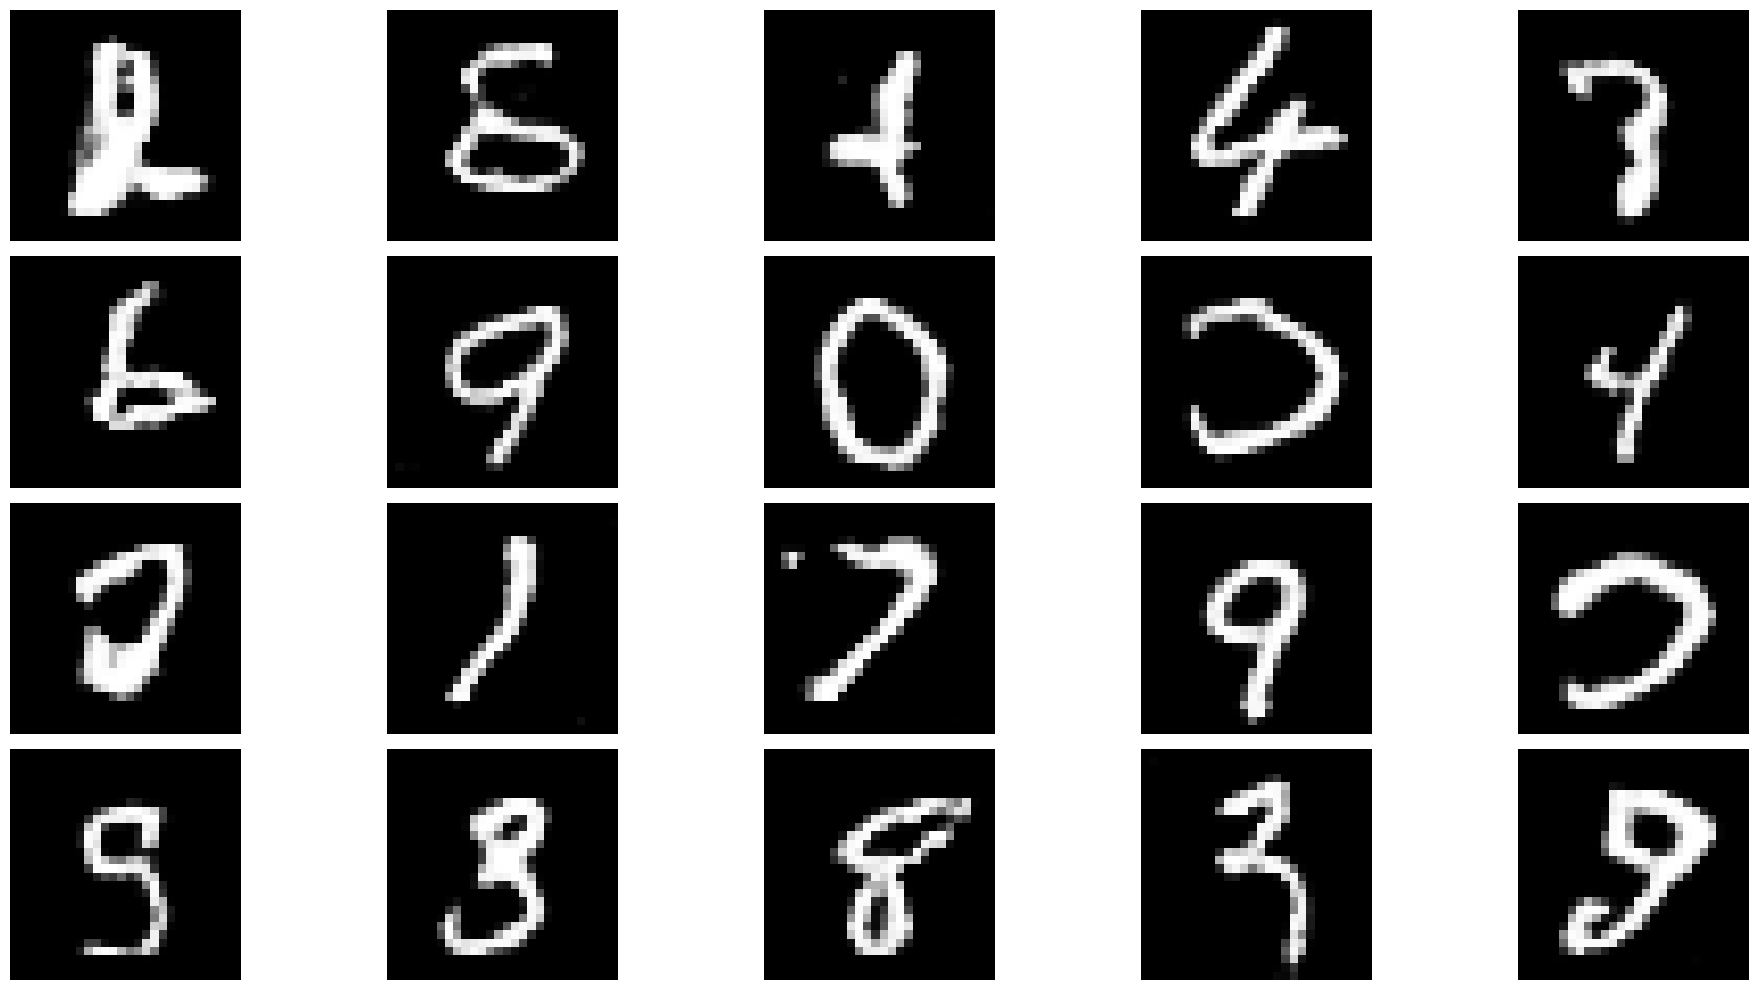

📈 Epoch 25 Summary:
   Train D Loss: 0.7487, Val D Loss: 1.1477
   Train G Loss: 1.6582, Val G Loss: 0.7968

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.859697	G_loss: 3.059566
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.709874	G_loss: 1.869924
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.607014	G_loss: 2.000217
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.107115	G_loss: 2.792871
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.925459	G_loss: 2.471687
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.588334	G_loss: 1.892959
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.674374	G_loss: 1.233889
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.727546	G_loss: 2.164463
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.895604	G_loss: 0.764137
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.644550	G_loss: 1.827084
====> Epoch: 26 Train D_loss: 0.7538, Train G_loss: 1.6932
====> Epoch: 26 Val D_loss: 0.9929, Val G_loss: 1.0859
📈 Epoch 26 Summary:
   Train D Loss: 0.7538, Val D Loss: 0.9929
   Train G Loss: 1.6932

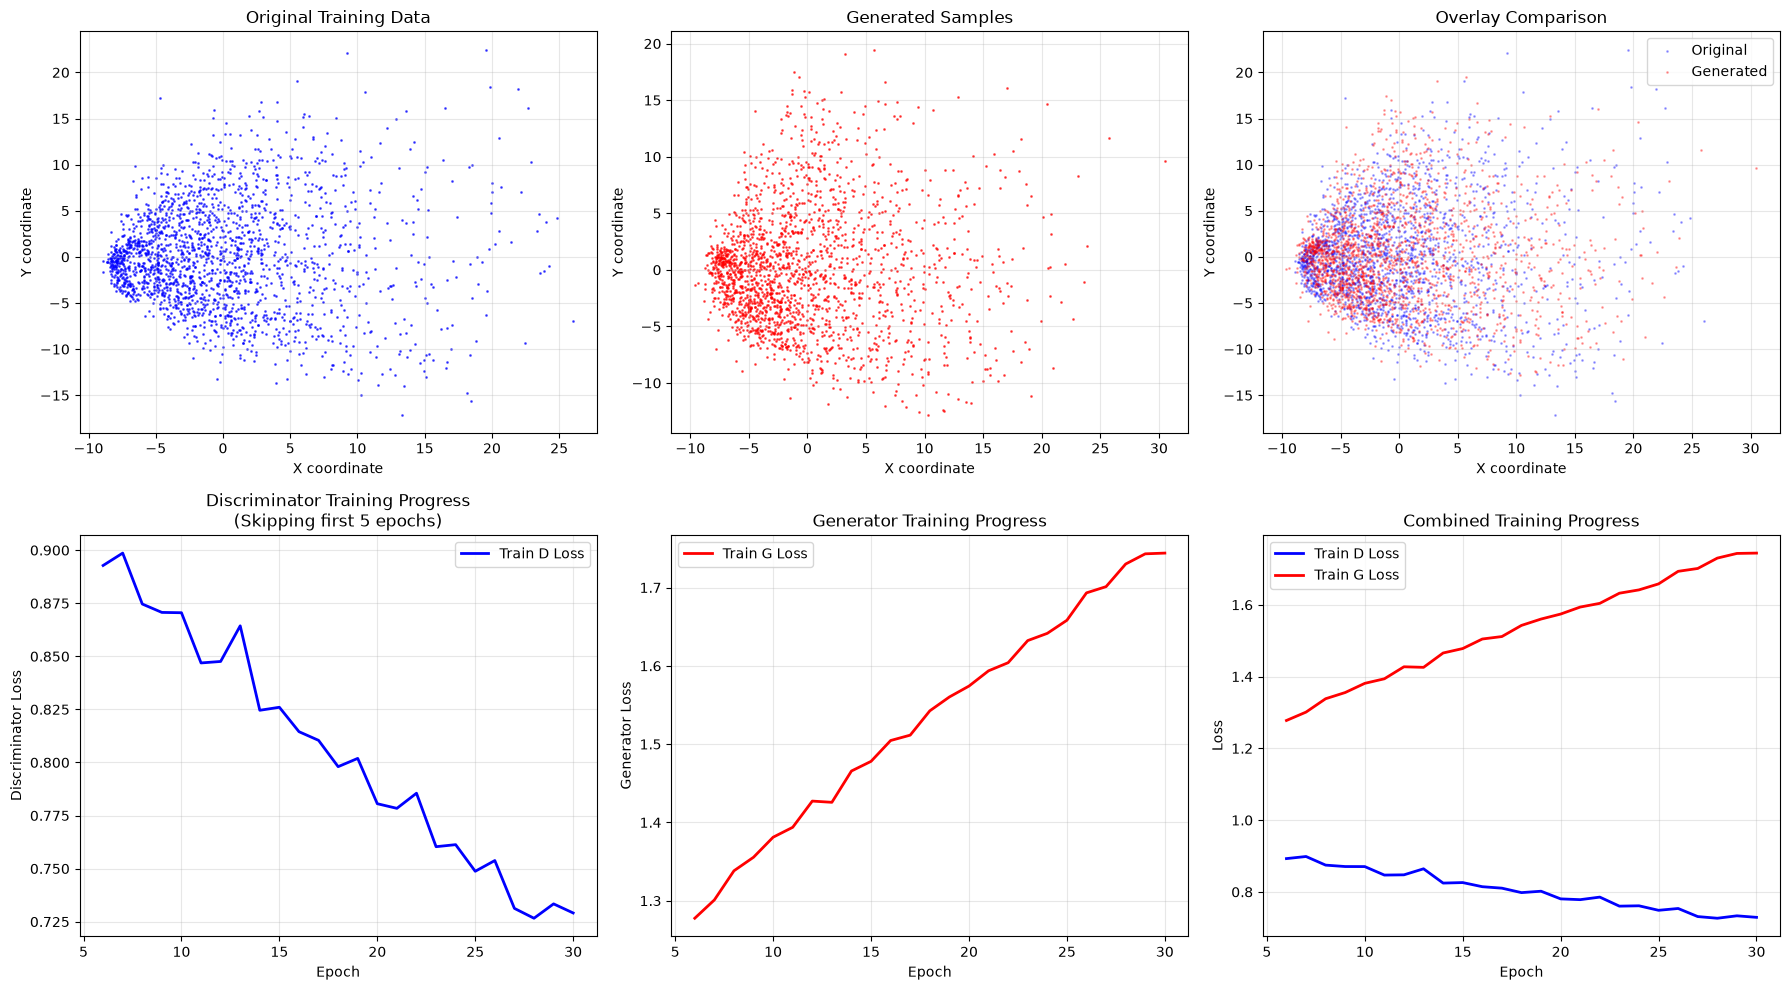

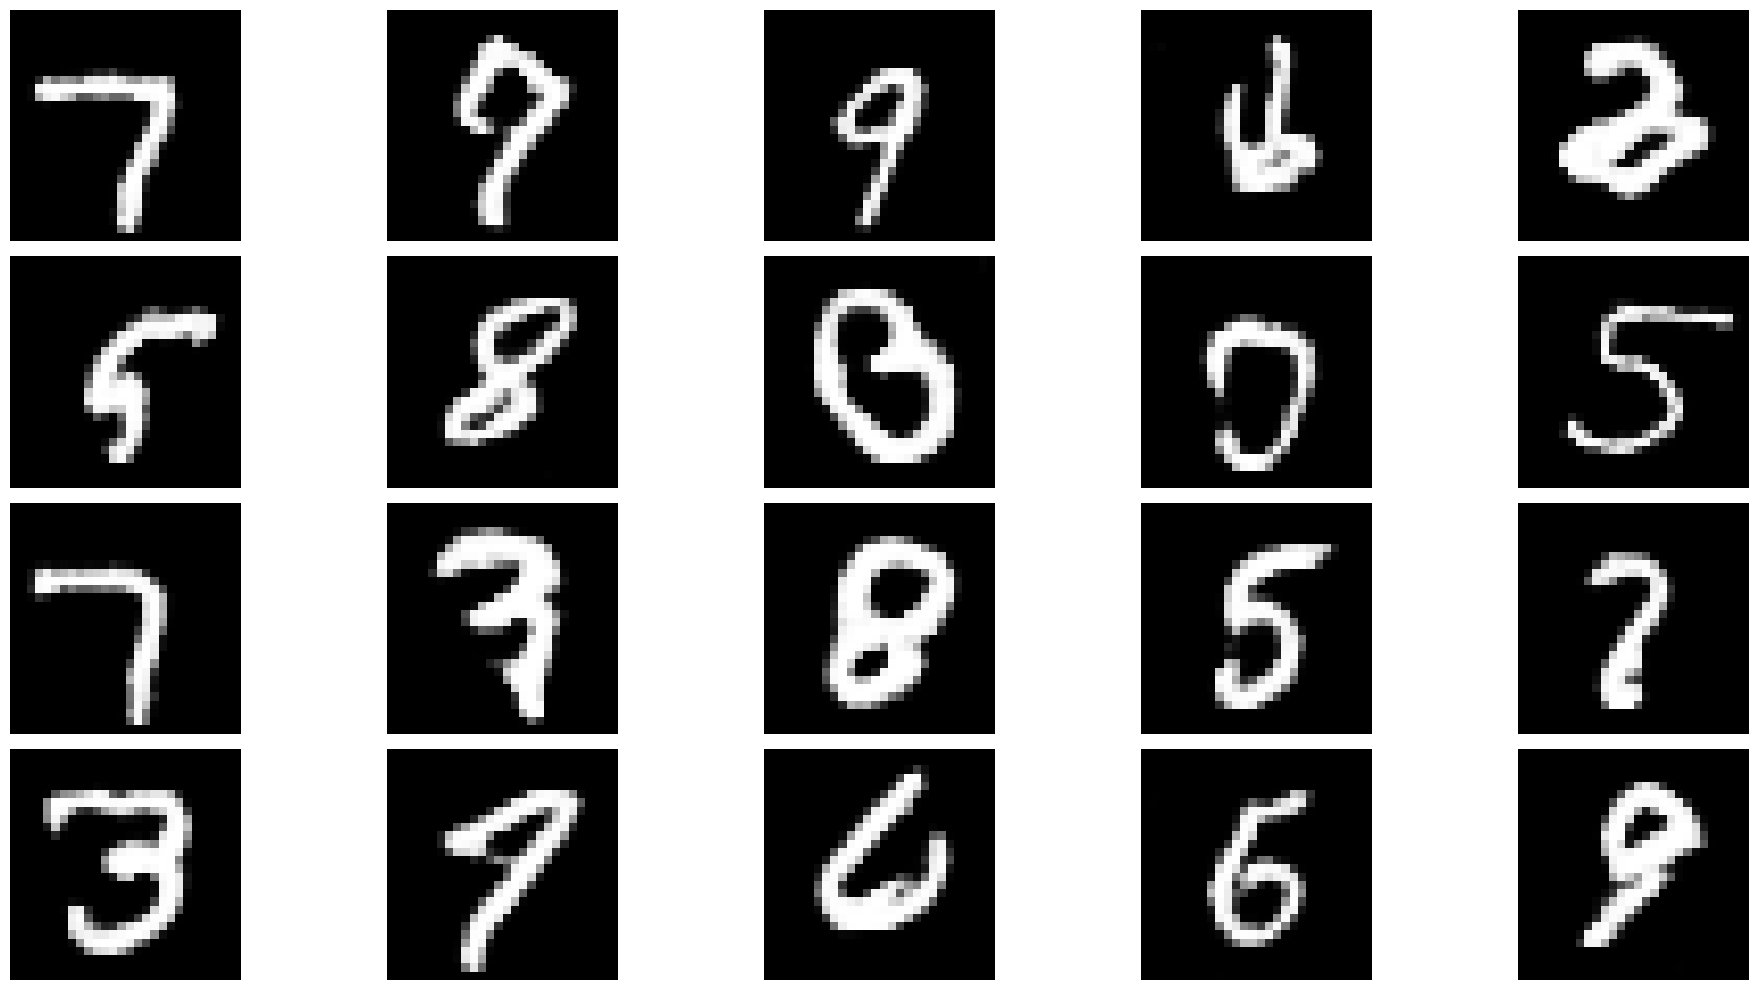

📈 Epoch 30 Summary:
   Train D Loss: 0.7291, Val D Loss: 0.9938
   Train G Loss: 1.7440, Val G Loss: 1.5933

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.657980	G_loss: 1.156451
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.676570	G_loss: 1.463793
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.673610	G_loss: 1.896137
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.843224	G_loss: 0.911778
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.678093	G_loss: 1.649193
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.791391	G_loss: 1.623211
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.649701	G_loss: 2.203824
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.684112	G_loss: 1.348148
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.689482	G_loss: 2.822366
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.697011	G_loss: 1.345743
====> Epoch: 31 Train D_loss: 0.7212, Train G_loss: 1.7646
====> Epoch: 31 Val D_loss: 1.0261, Val G_loss: 1.0009
📈 Epoch 31 Summary:
   Train D Loss: 0.7212, Val D Loss: 1.0261
   Train G Loss: 1.7646

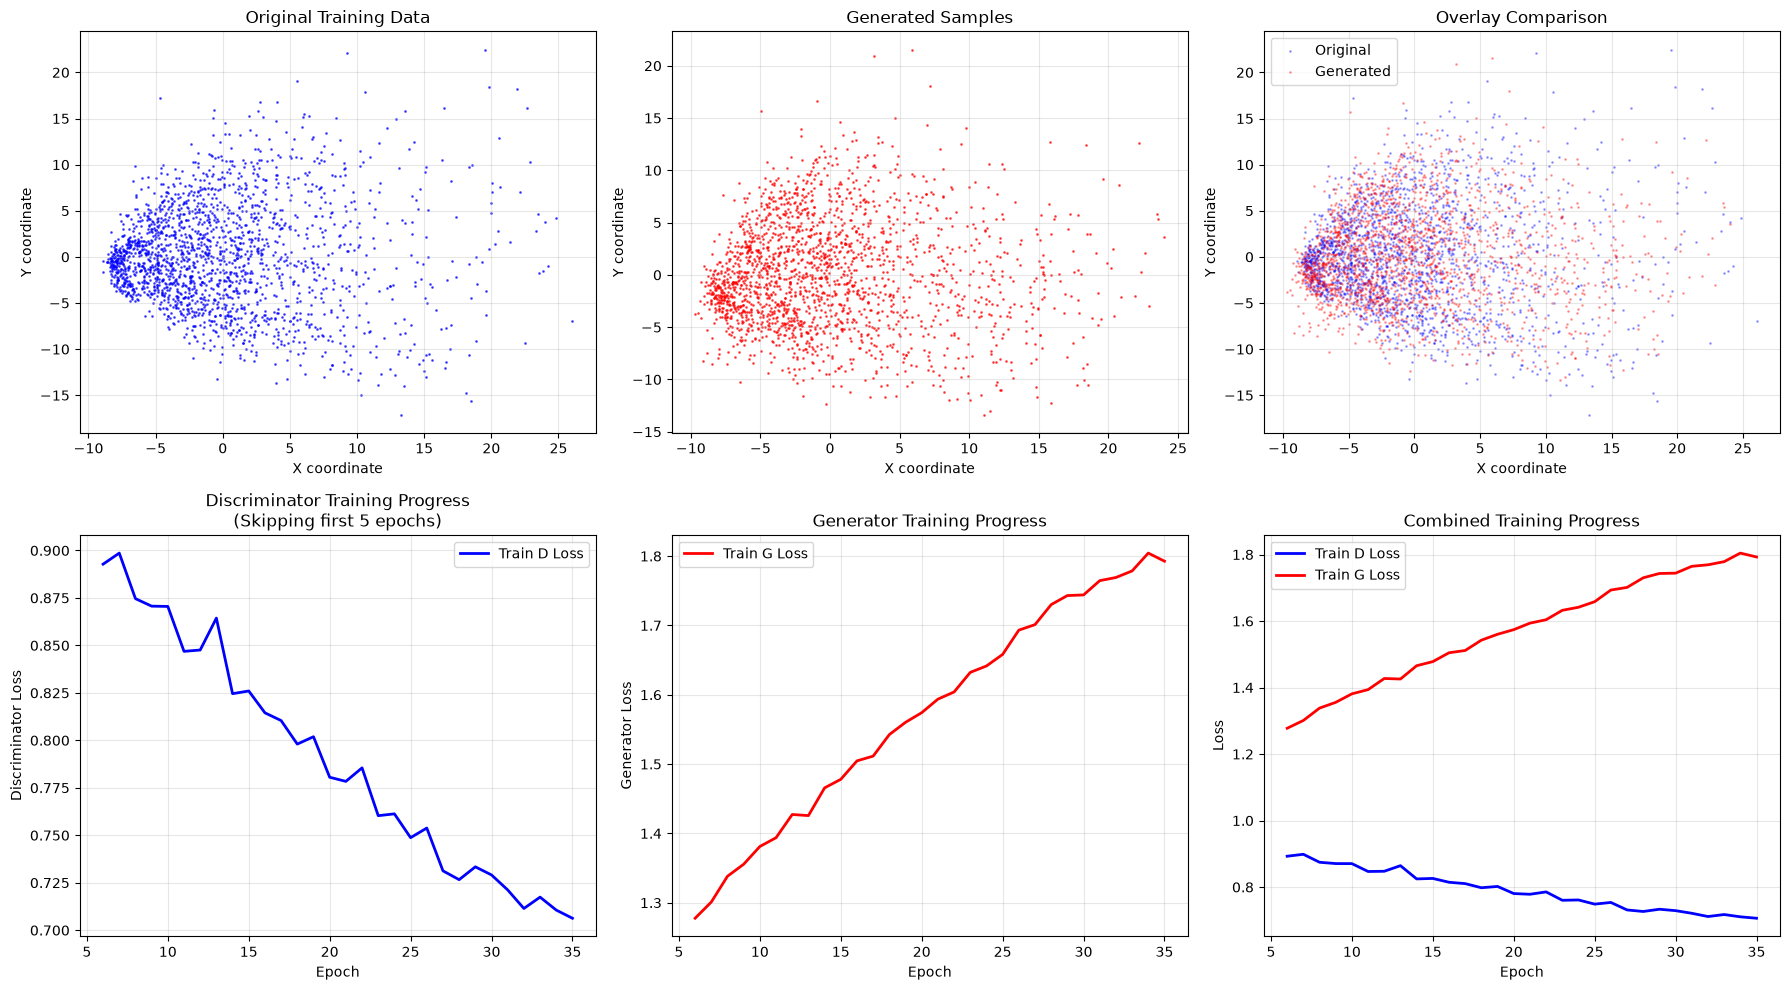

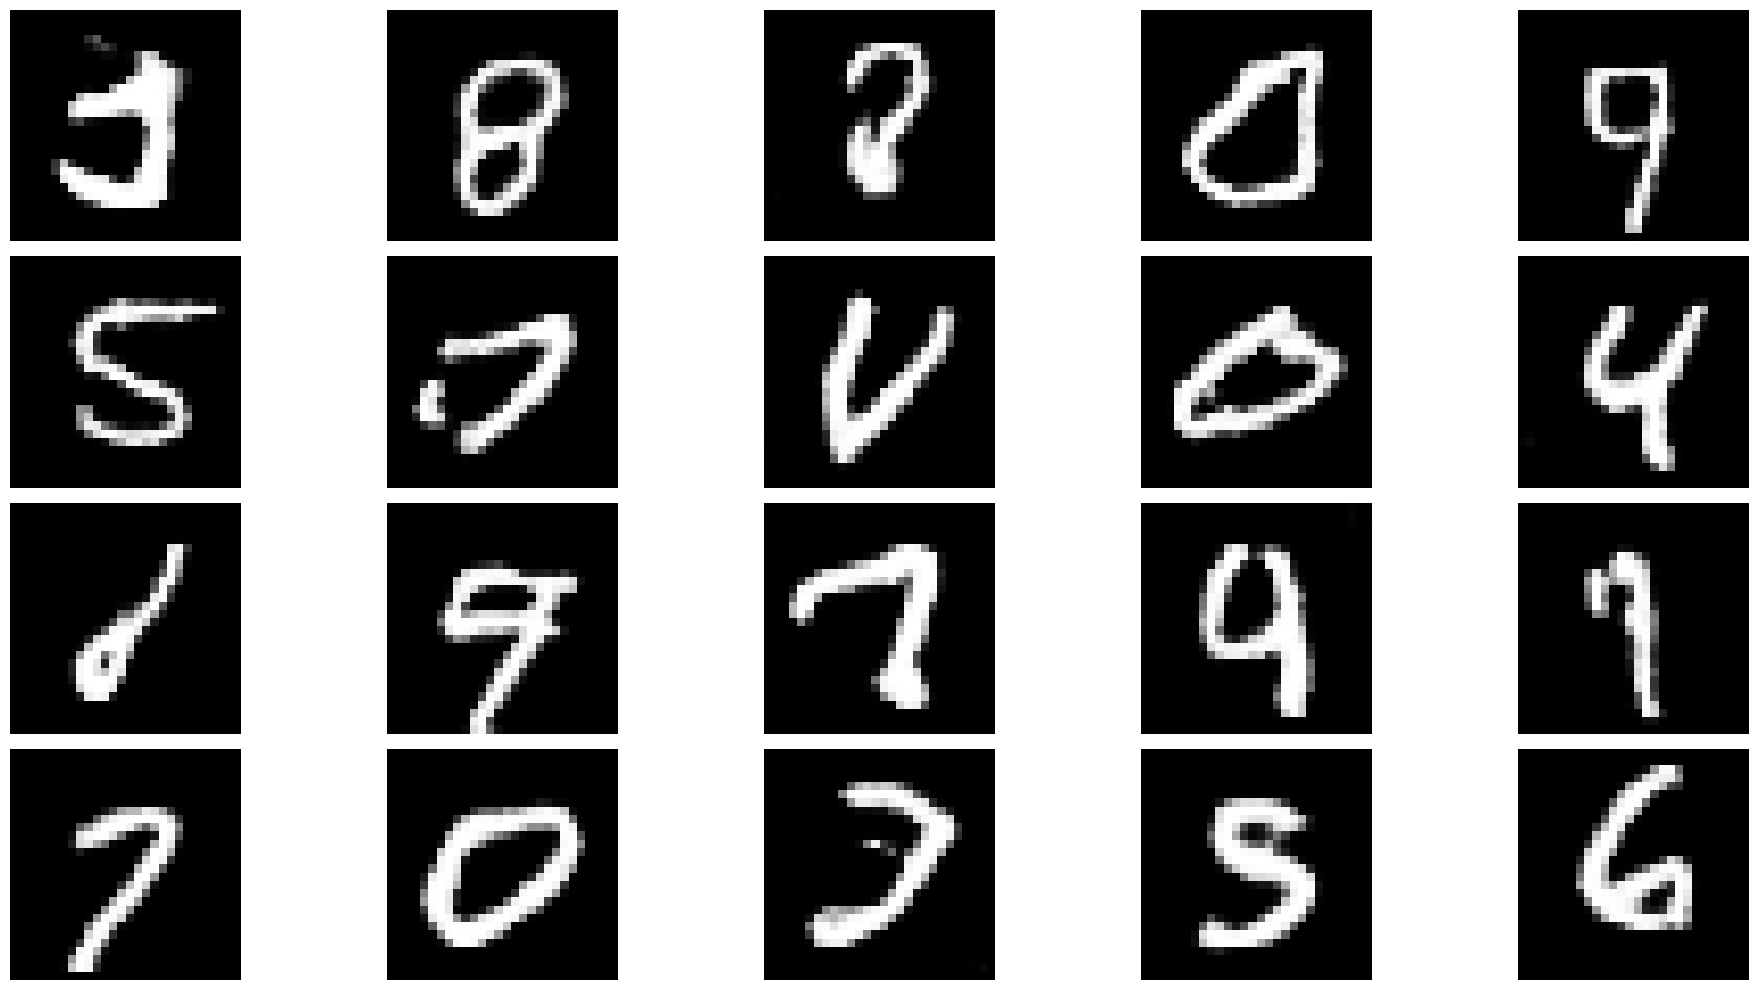

📈 Epoch 35 Summary:
   Train D Loss: 0.7063, Val D Loss: 0.9578
   Train G Loss: 1.7927, Val G Loss: 1.4427

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.533962	G_loss: 1.881160
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.633307	G_loss: 1.737285
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.648669	G_loss: 1.623489
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.639519	G_loss: 1.541741
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.814613	G_loss: 2.036590
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.649485	G_loss: 1.966621
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.658332	G_loss: 1.946473
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.710515	G_loss: 2.295612
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.622714	G_loss: 1.582858
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.690371	G_loss: 1.515491
====> Epoch: 36 Train D_loss: 0.7036, Train G_loss: 1.8157
====> Epoch: 36 Val D_loss: 1.0711, Val G_loss: 1.9001
📈 Epoch 36 Summary:
   Train D Loss: 0.7036, Val D Loss: 1.0711
   Train G Loss: 1.8157

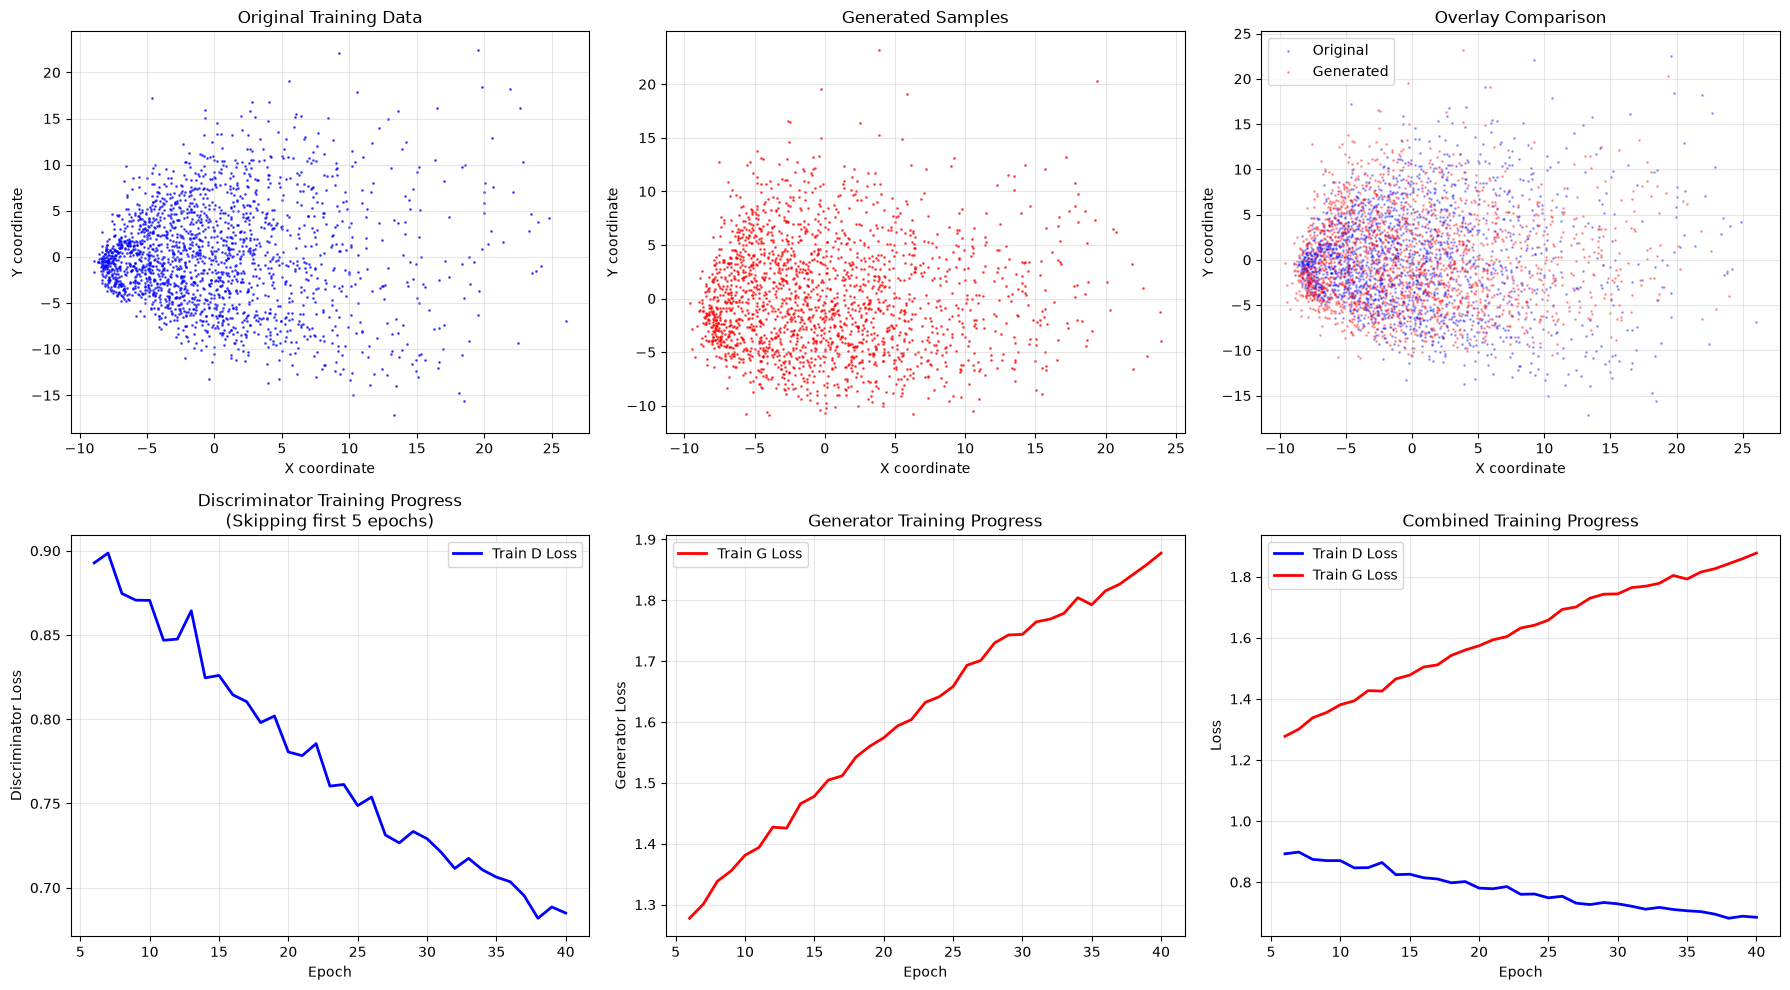

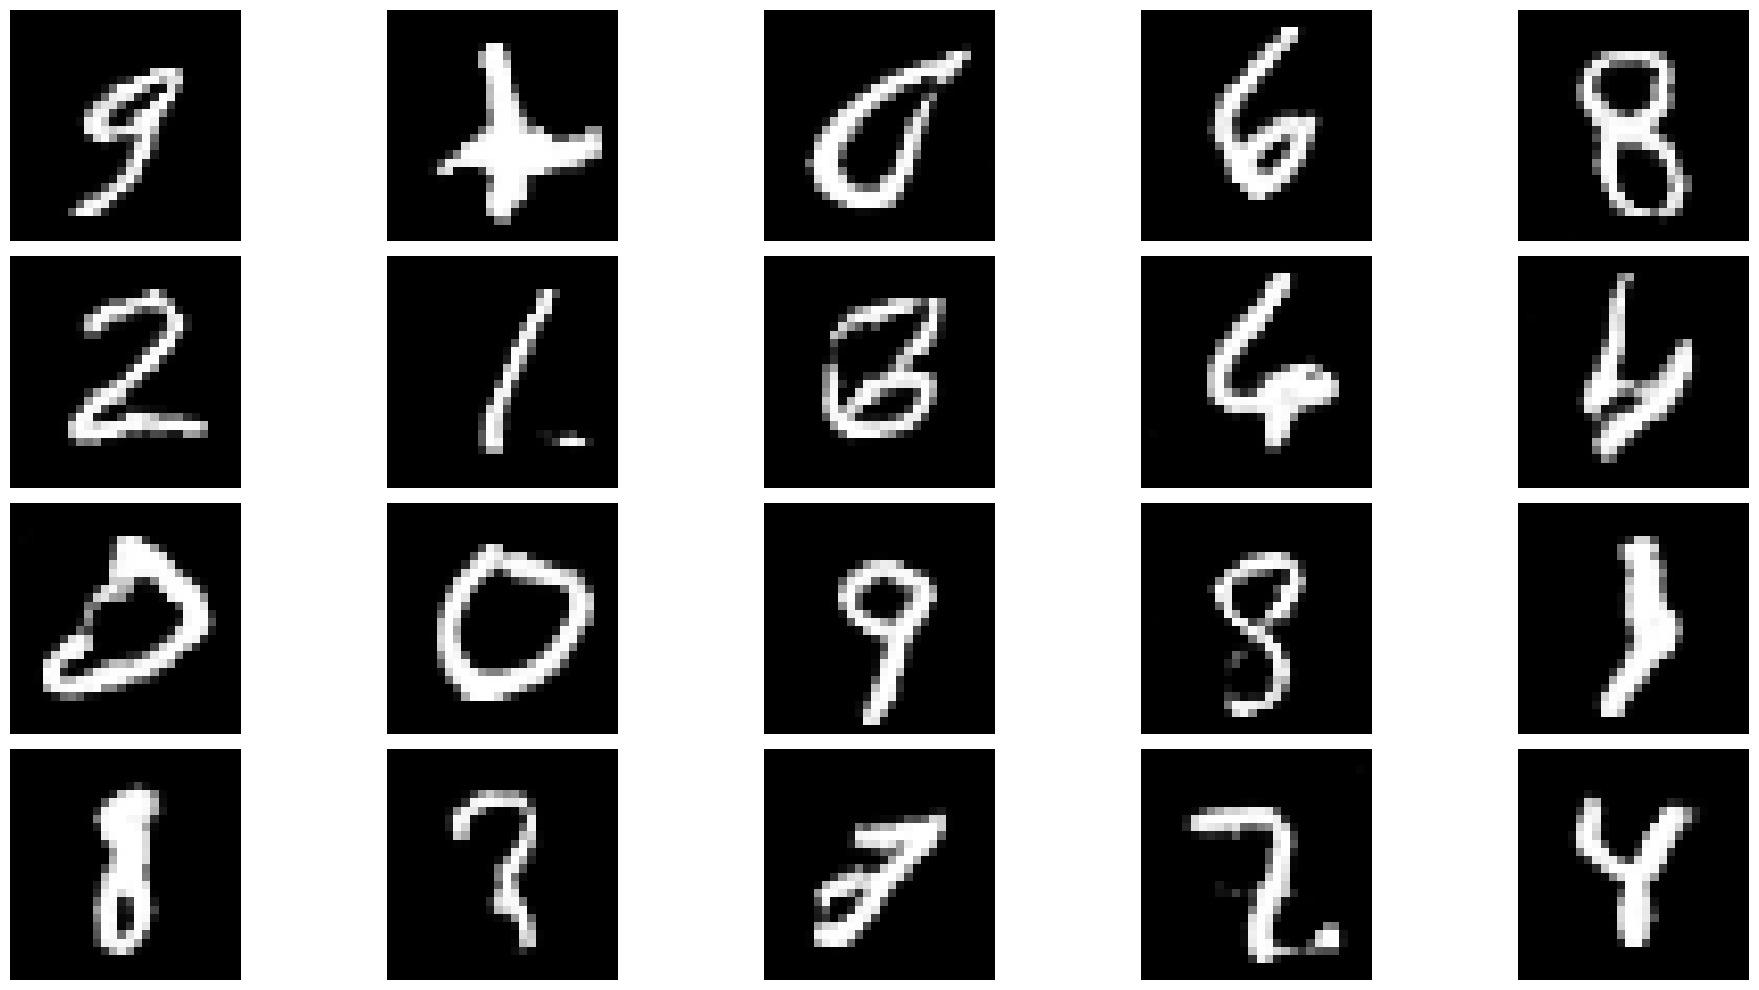

📈 Epoch 40 Summary:
   Train D Loss: 0.6850, Val D Loss: 1.0583
   Train G Loss: 1.8776, Val G Loss: 1.9006

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.615136	G_loss: 1.855341
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.949812	G_loss: 2.265925
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.680113	G_loss: 2.416756
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.723872	G_loss: 2.567663
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.743961	G_loss: 1.731788
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.538833	G_loss: 2.153616
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.743009	G_loss: 2.543875
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.573344	G_loss: 1.888369
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.618272	G_loss: 1.455327
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.652194	G_loss: 0.860036
====> Epoch: 41 Train D_loss: 0.6850, Train G_loss: 1.8871
====> Epoch: 41 Val D_loss: 0.9892, Val G_loss: 1.7171
📈 Epoch 41 Summary:
   Train D Loss: 0.6850, Val D Loss: 0.9892
   Train G Loss: 1.8871

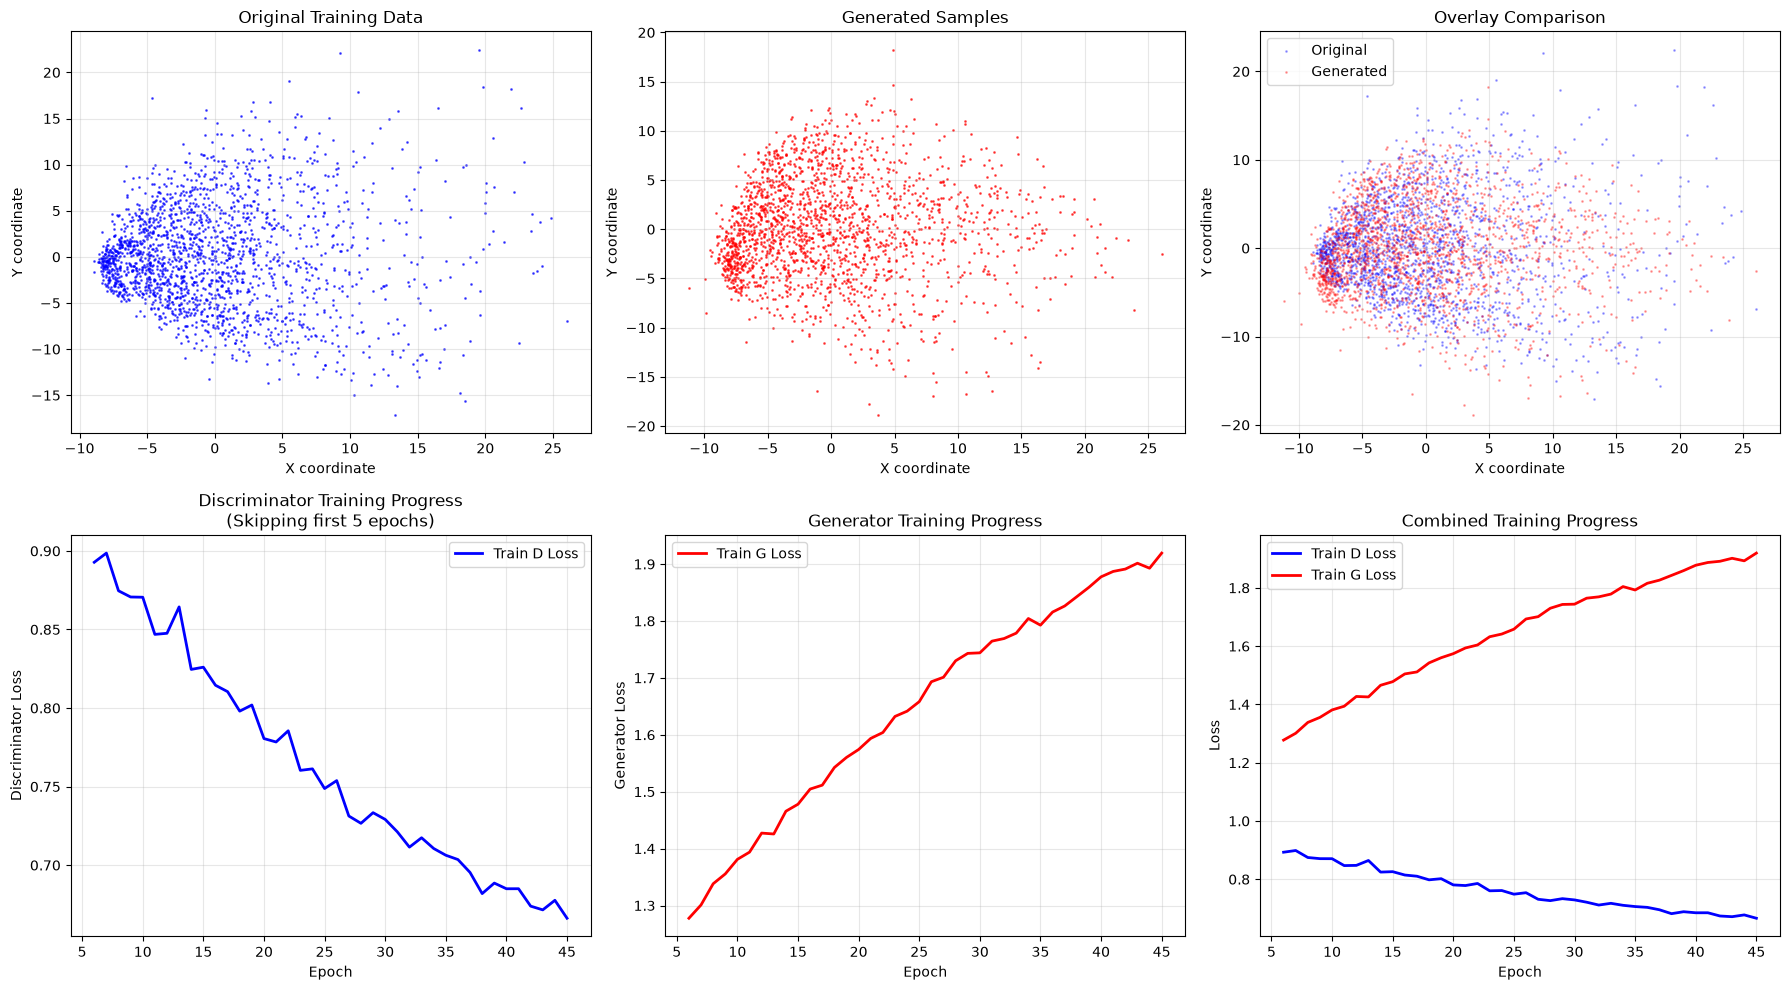

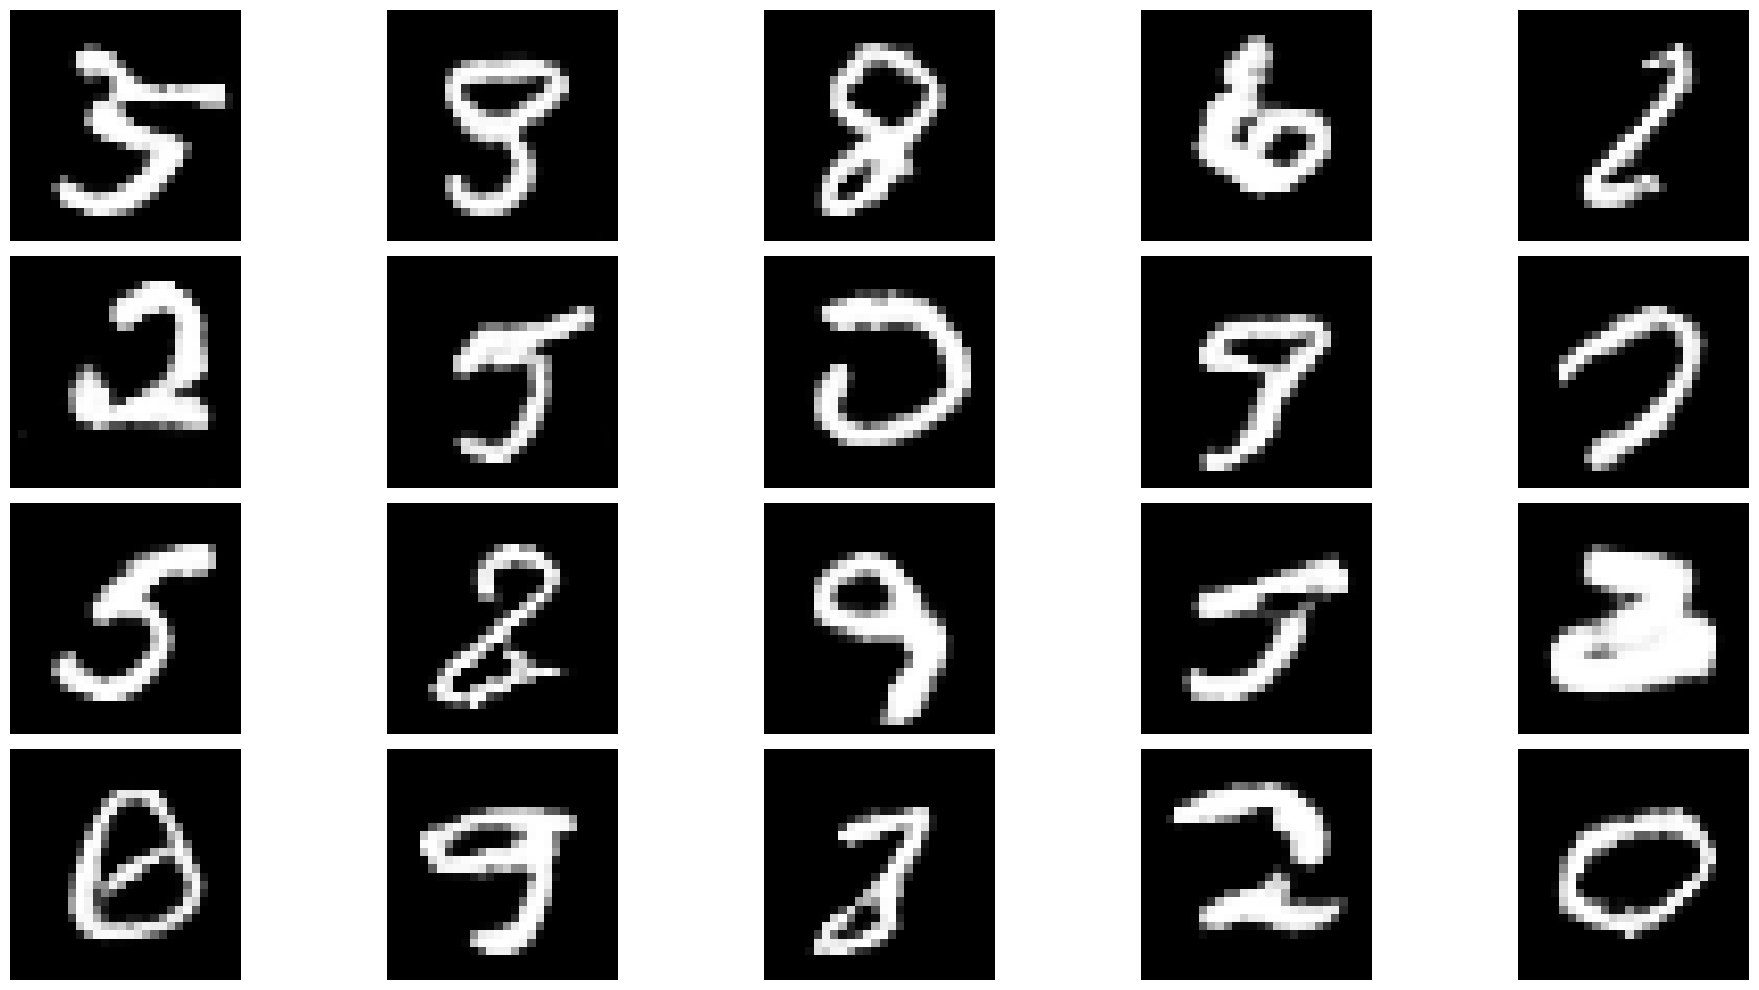

📈 Epoch 45 Summary:
   Train D Loss: 0.6662, Val D Loss: 0.9865
   Train G Loss: 1.9193, Val G Loss: 1.7549

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.521144	G_loss: 1.921504
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.572670	G_loss: 1.825393
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.782944	G_loss: 1.107517
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.635325	G_loss: 1.089429
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.758909	G_loss: 0.965966
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.553050	G_loss: 1.983679
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.752718	G_loss: 2.457153
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.690546	G_loss: 2.097744
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.704031	G_loss: 1.894314
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.571843	G_loss: 1.386113
====> Epoch: 46 Train D_loss: 0.6737, Train G_loss: 1.9311
====> Epoch: 46 Val D_loss: 1.4635, Val G_loss: 2.7928
📈 Epoch 46 Summary:
   Train D Loss: 0.6737, Val D Loss: 1.4635
   Train G Loss: 1.9311

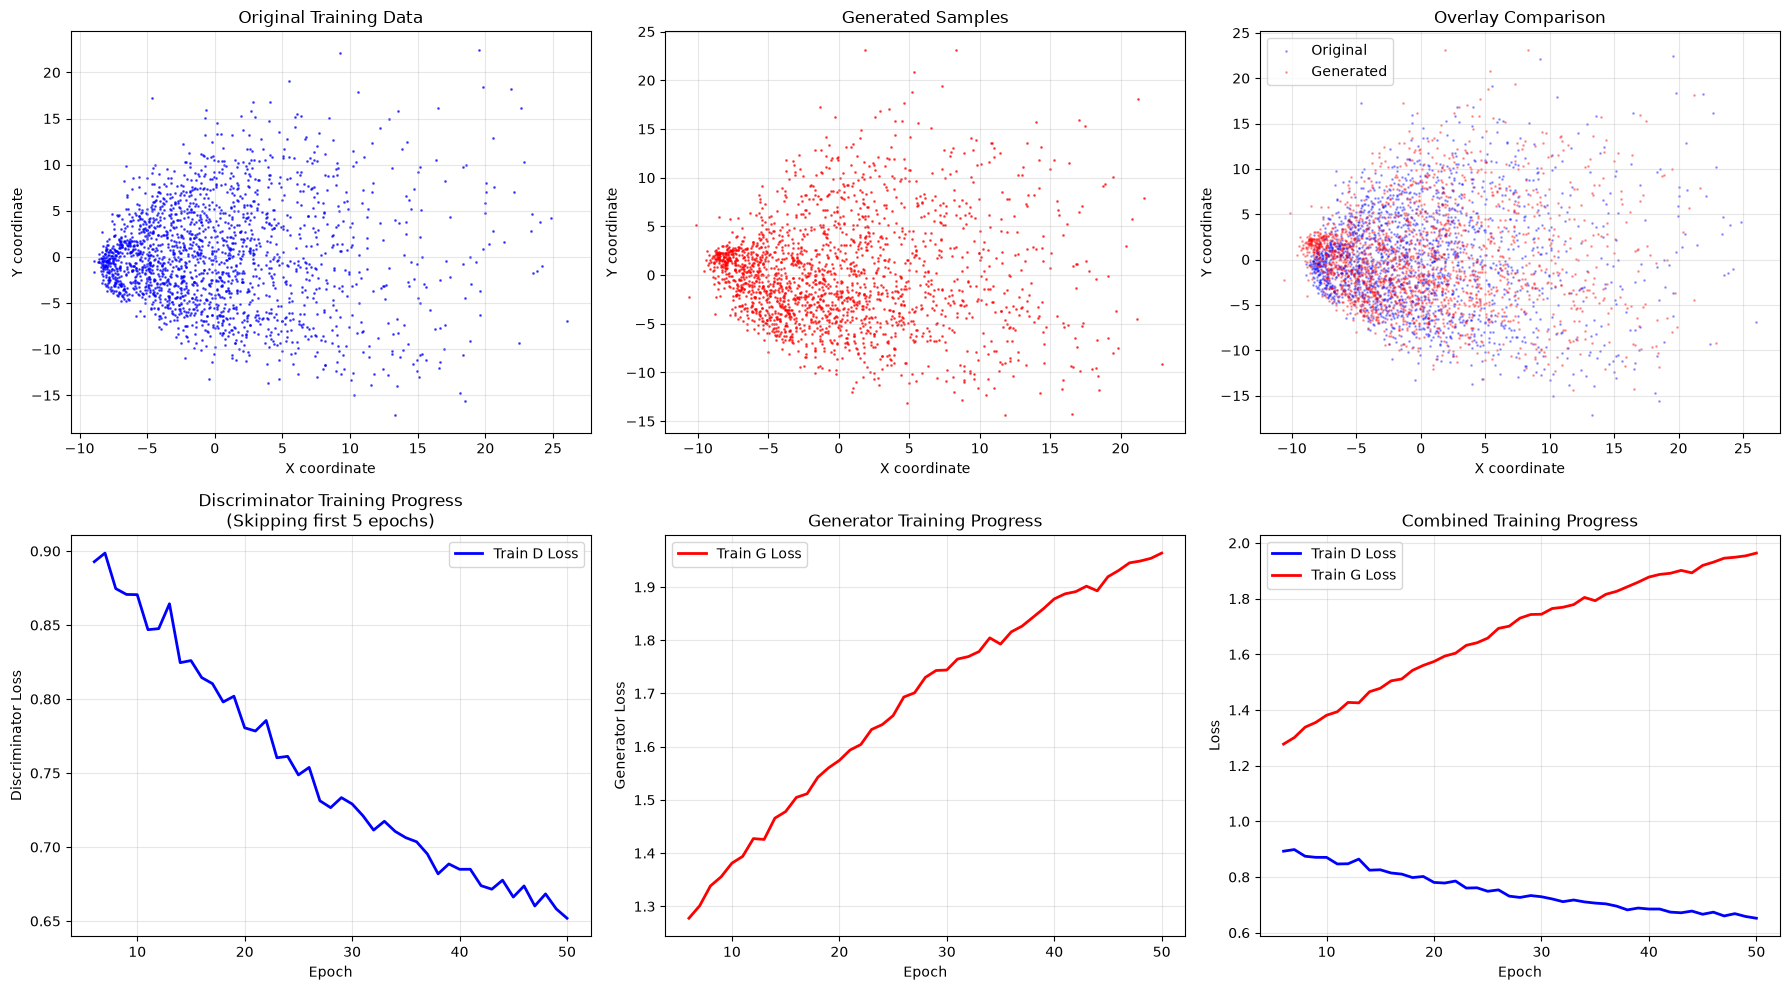

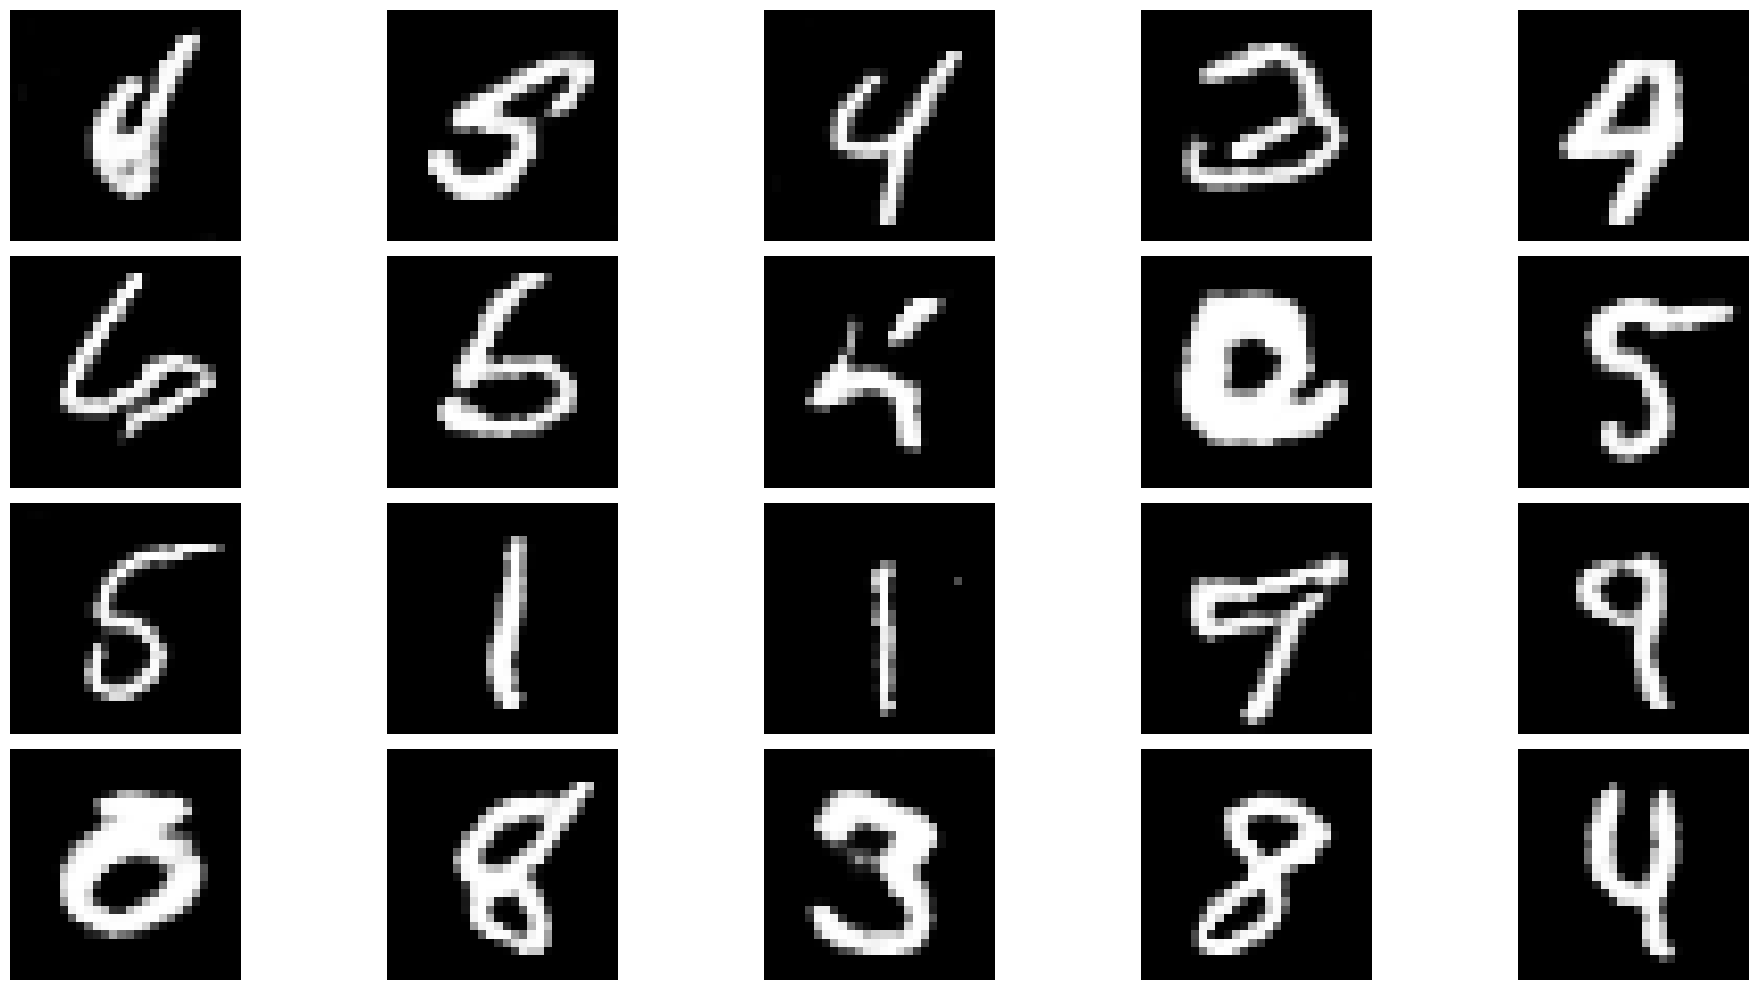

📈 Epoch 50 Summary:
   Train D Loss: 0.6519, Val D Loss: 1.0158
   Train G Loss: 1.9637, Val G Loss: 1.8613

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.581864	G_loss: 1.905072
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.618380	G_loss: 2.905966
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.677726	G_loss: 1.686975
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.686364	G_loss: 2.487910
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.501567	G_loss: 2.045198
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.792299	G_loss: 2.278225
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.678308	G_loss: 1.830772
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.578138	G_loss: 2.247885
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.597521	G_loss: 2.014147
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.636619	G_loss: 1.818099
====> Epoch: 51 Train D_loss: 0.6557, Train G_loss: 1.9632
====> Epoch: 51 Val D_loss: 1.0041, Val G_loss: 1.7586
📈 Epoch 51 Summary:
   Train D Loss: 0.6557, Val D Loss: 1.0041
   Train G Loss: 1.9632

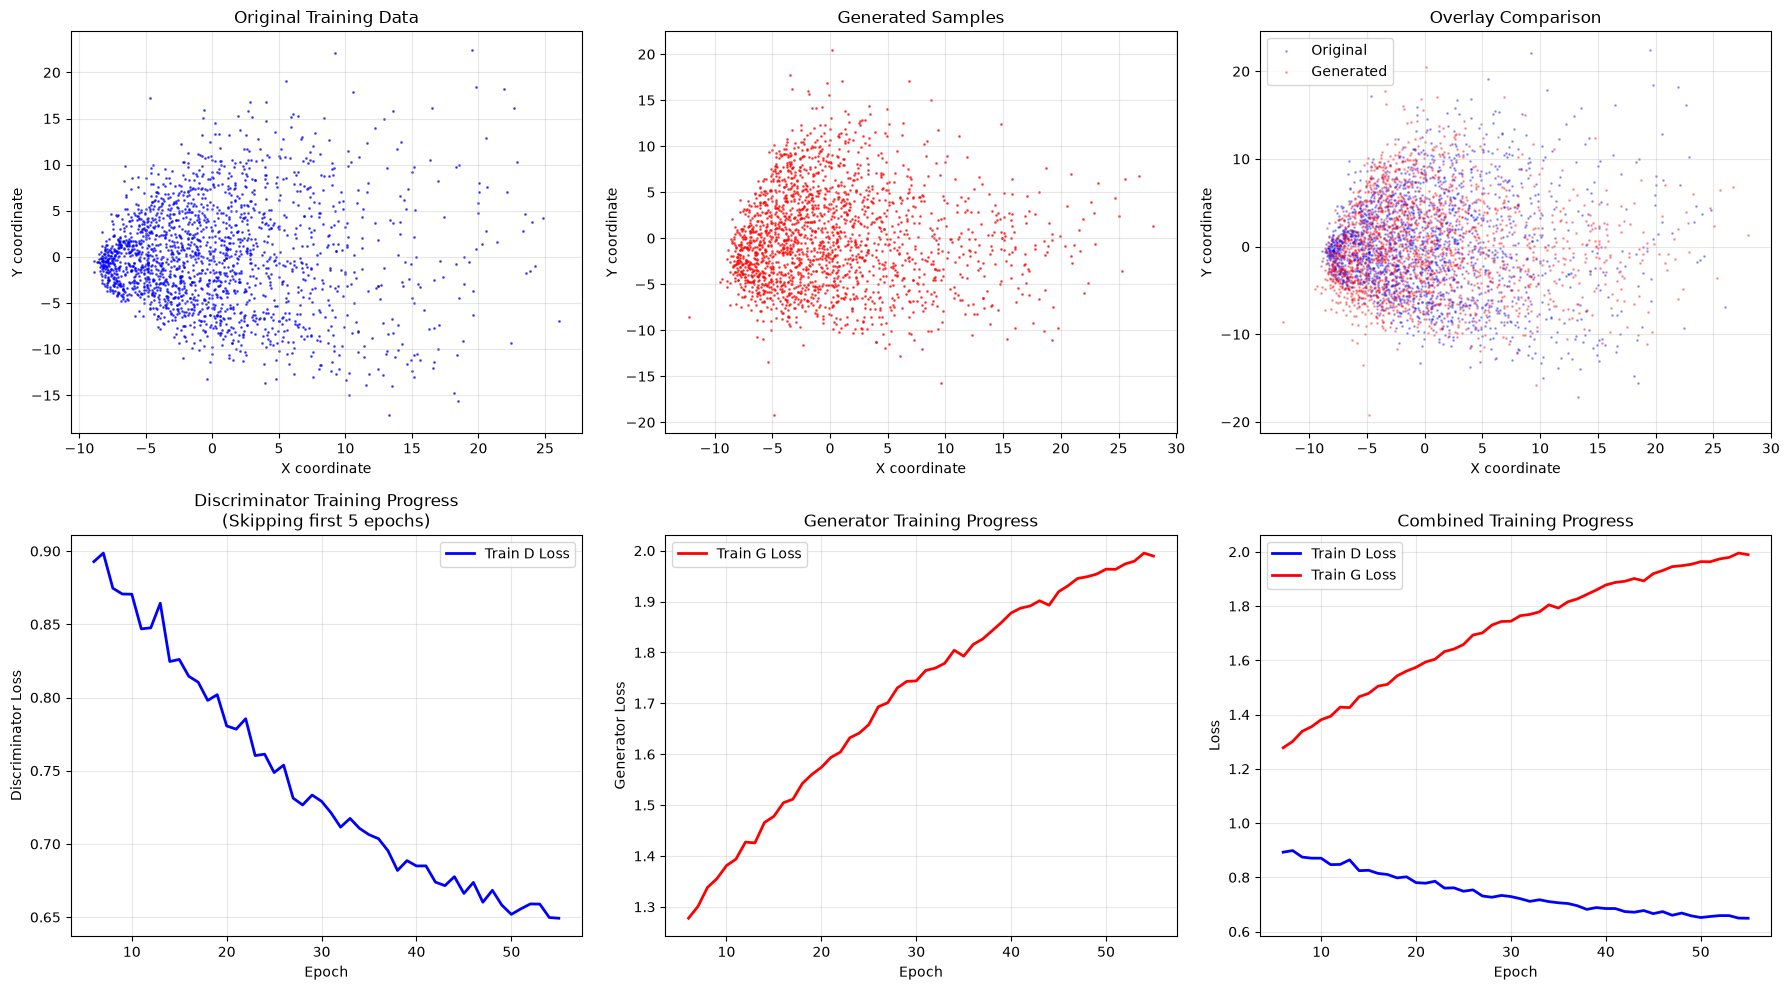

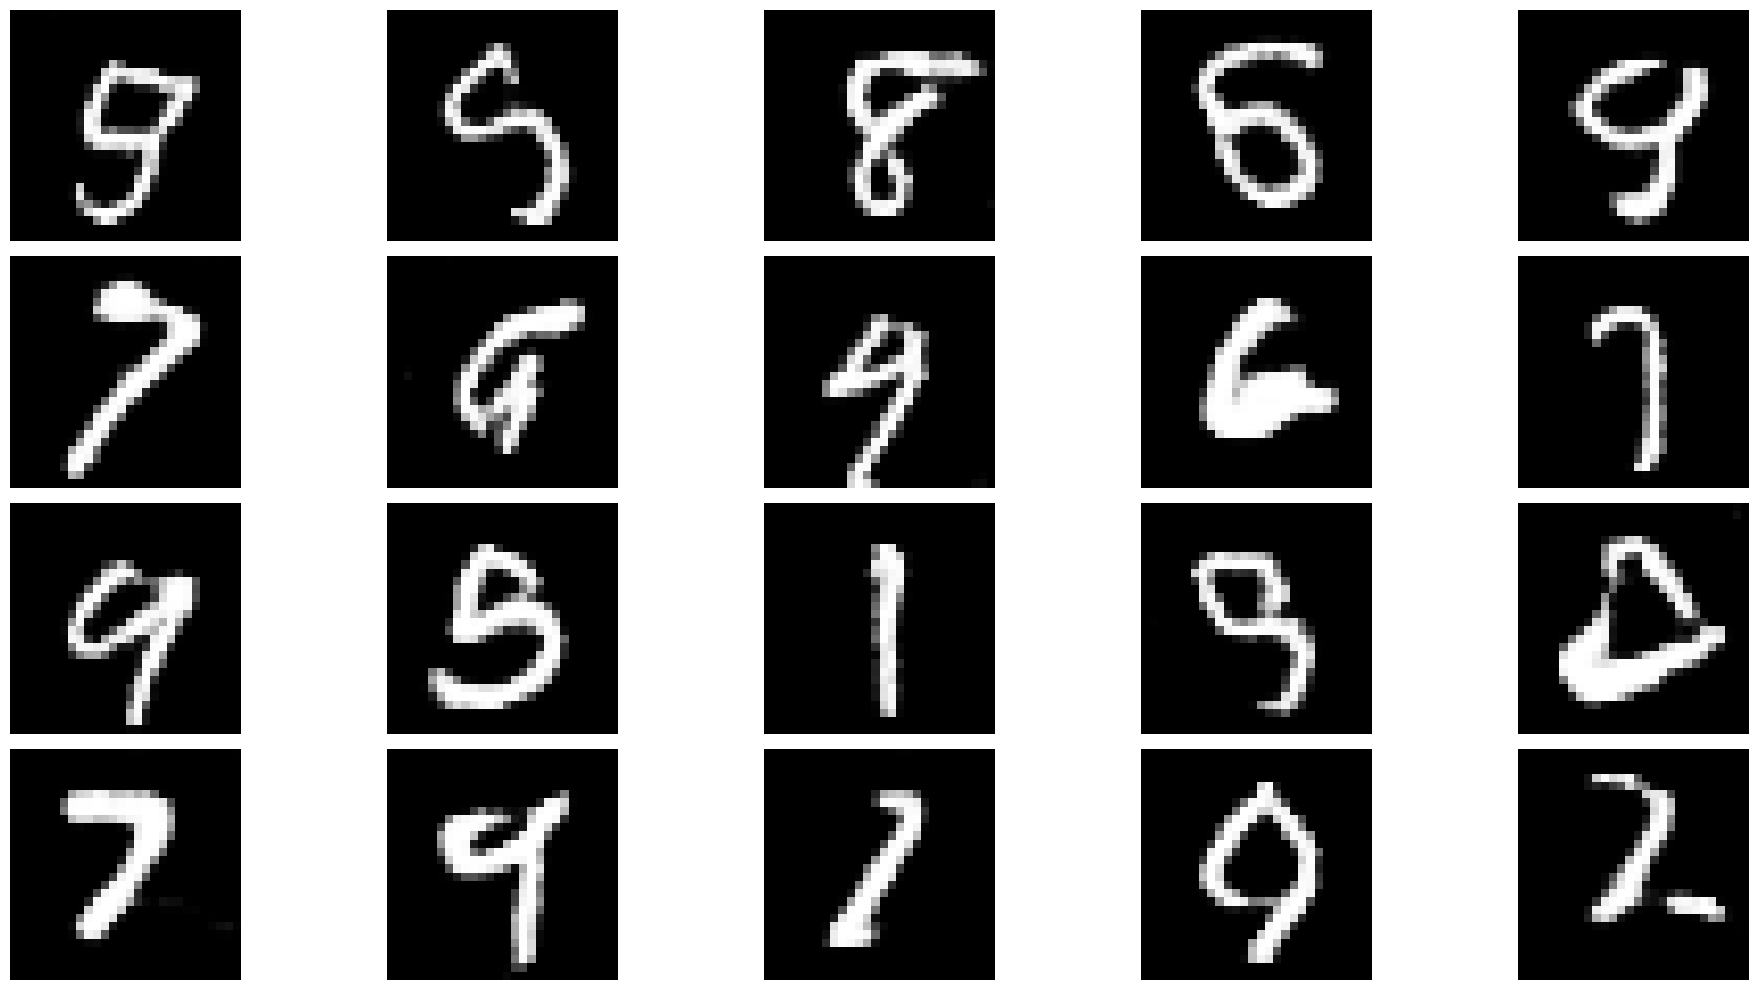

📈 Epoch 55 Summary:
   Train D Loss: 0.6492, Val D Loss: 1.2349
   Train G Loss: 1.9894, Val G Loss: 0.6918

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.739672	G_loss: 2.340789
Epoch: 56 [6400/60000 (11%)]	D_loss: 1.083045	G_loss: 0.646999
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.569238	G_loss: 1.315434
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.737735	G_loss: 2.678316
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.590179	G_loss: 2.155041
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.649844	G_loss: 3.107419
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.500156	G_loss: 2.091064
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.683776	G_loss: 1.365614
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.664989	G_loss: 1.492921
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.666763	G_loss: 1.457885
====> Epoch: 56 Train D_loss: 0.6472, Train G_loss: 2.0040
====> Epoch: 56 Val D_loss: 1.2168, Val G_loss: 0.7014
📈 Epoch 56 Summary:
   Train D Loss: 0.6472, Val D Loss: 1.2168
   Train G Loss: 2.0040

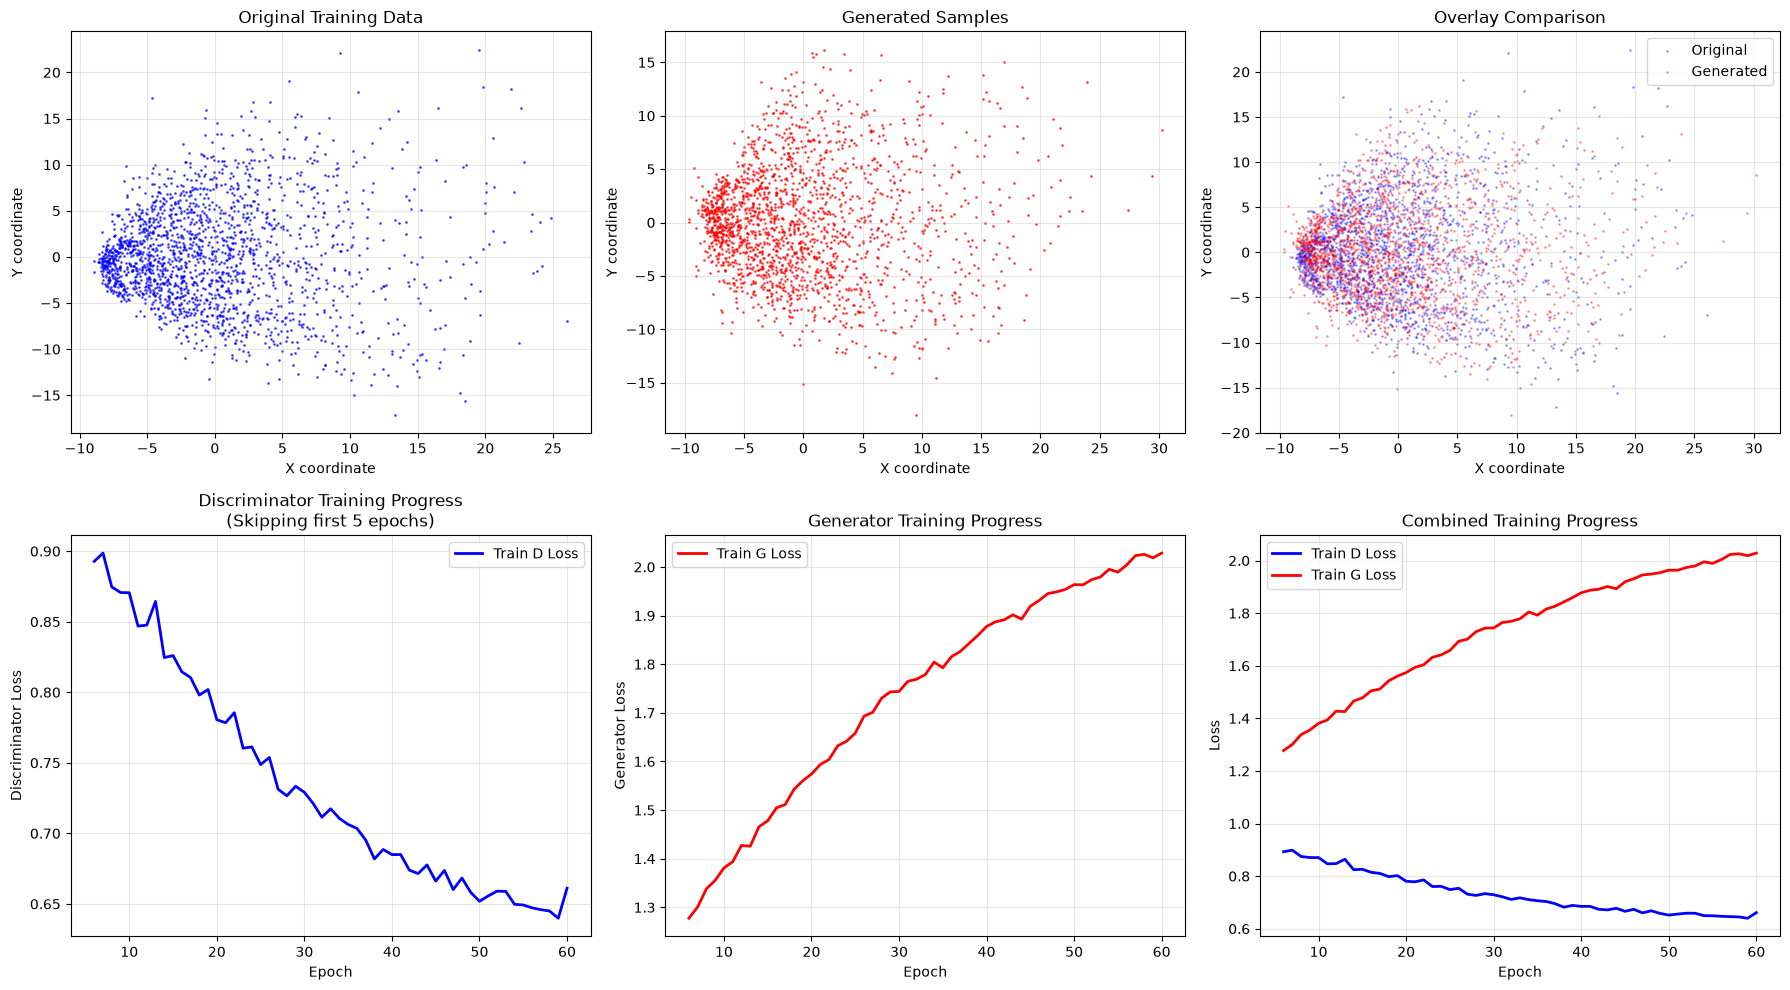

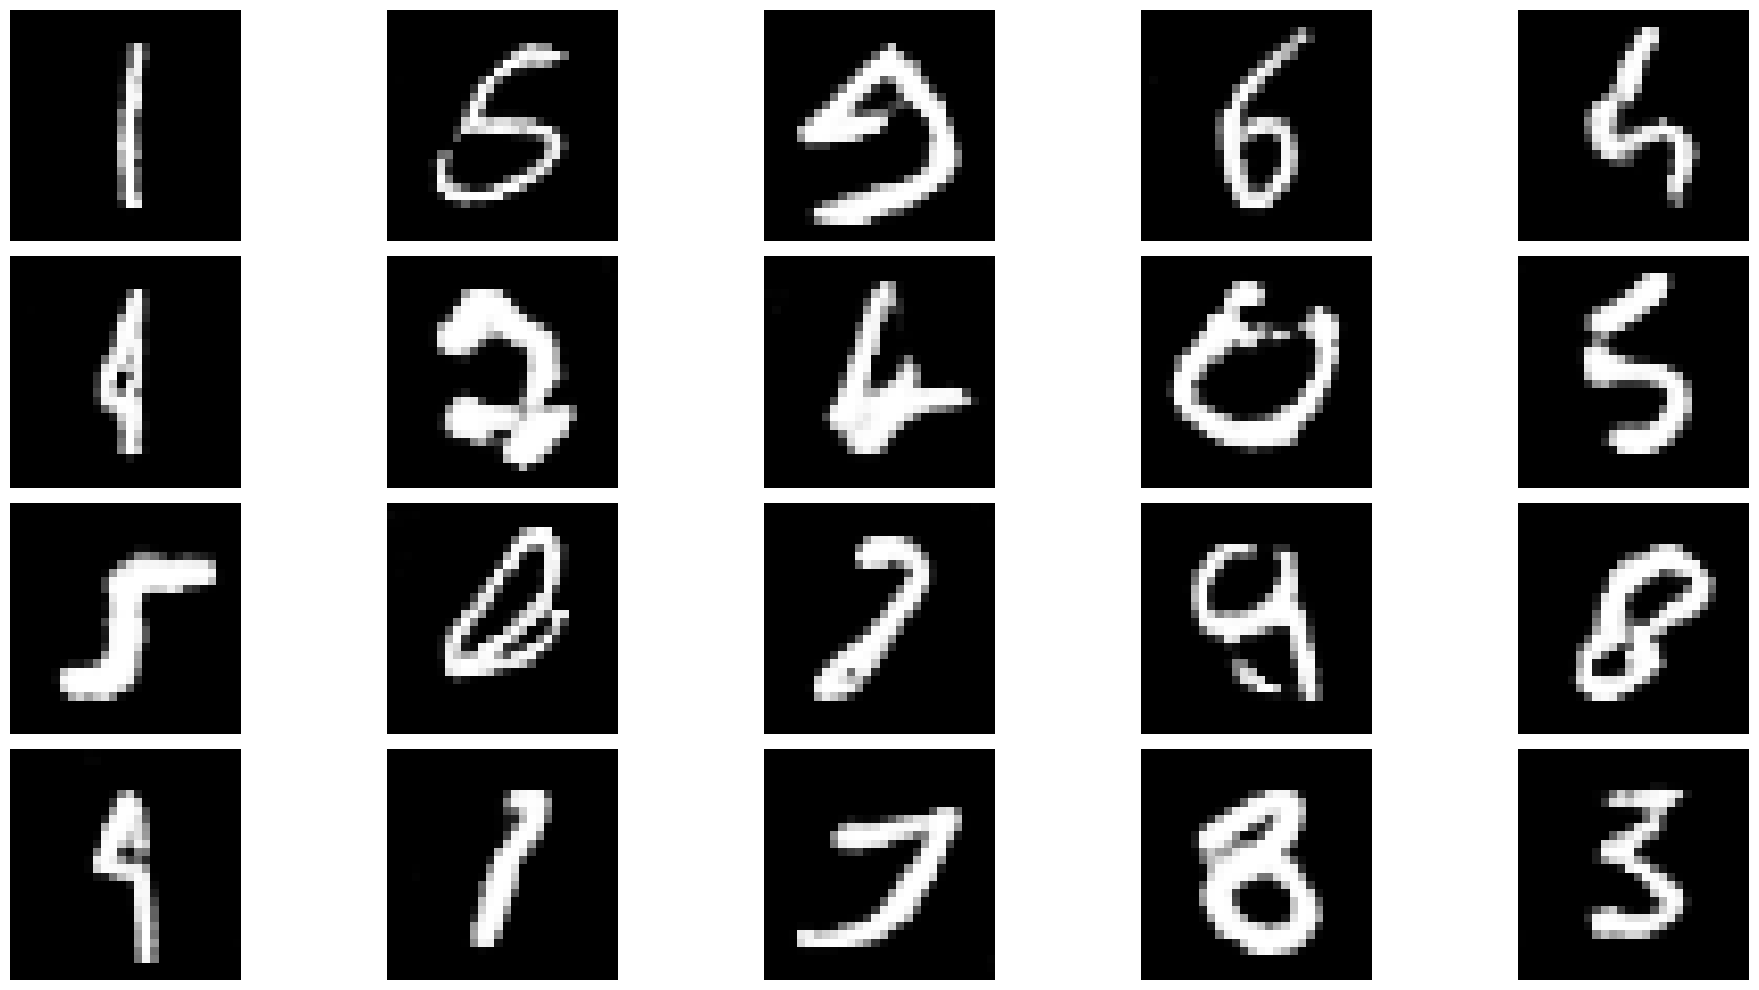

📈 Epoch 60 Summary:
   Train D Loss: 0.6611, Val D Loss: 1.0569
   Train G Loss: 2.0285, Val G Loss: 1.0377

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.742156	G_loss: 2.381310
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.713896	G_loss: 1.961848
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.642837	G_loss: 1.884477
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.594632	G_loss: 1.635231
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.629419	G_loss: 1.614003
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.782377	G_loss: 1.921585
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.575383	G_loss: 1.827321
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.588949	G_loss: 2.571273
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.604344	G_loss: 2.096554
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.572939	G_loss: 2.199173
====> Epoch: 61 Train D_loss: 0.6490, Train G_loss: 2.0494
====> Epoch: 61 Val D_loss: 0.9854, Val G_loss: 1.6080
📈 Epoch 61 Summary:
   Train D Loss: 0.6490, Val D Loss: 0.9854
   Train G Loss: 2.0494

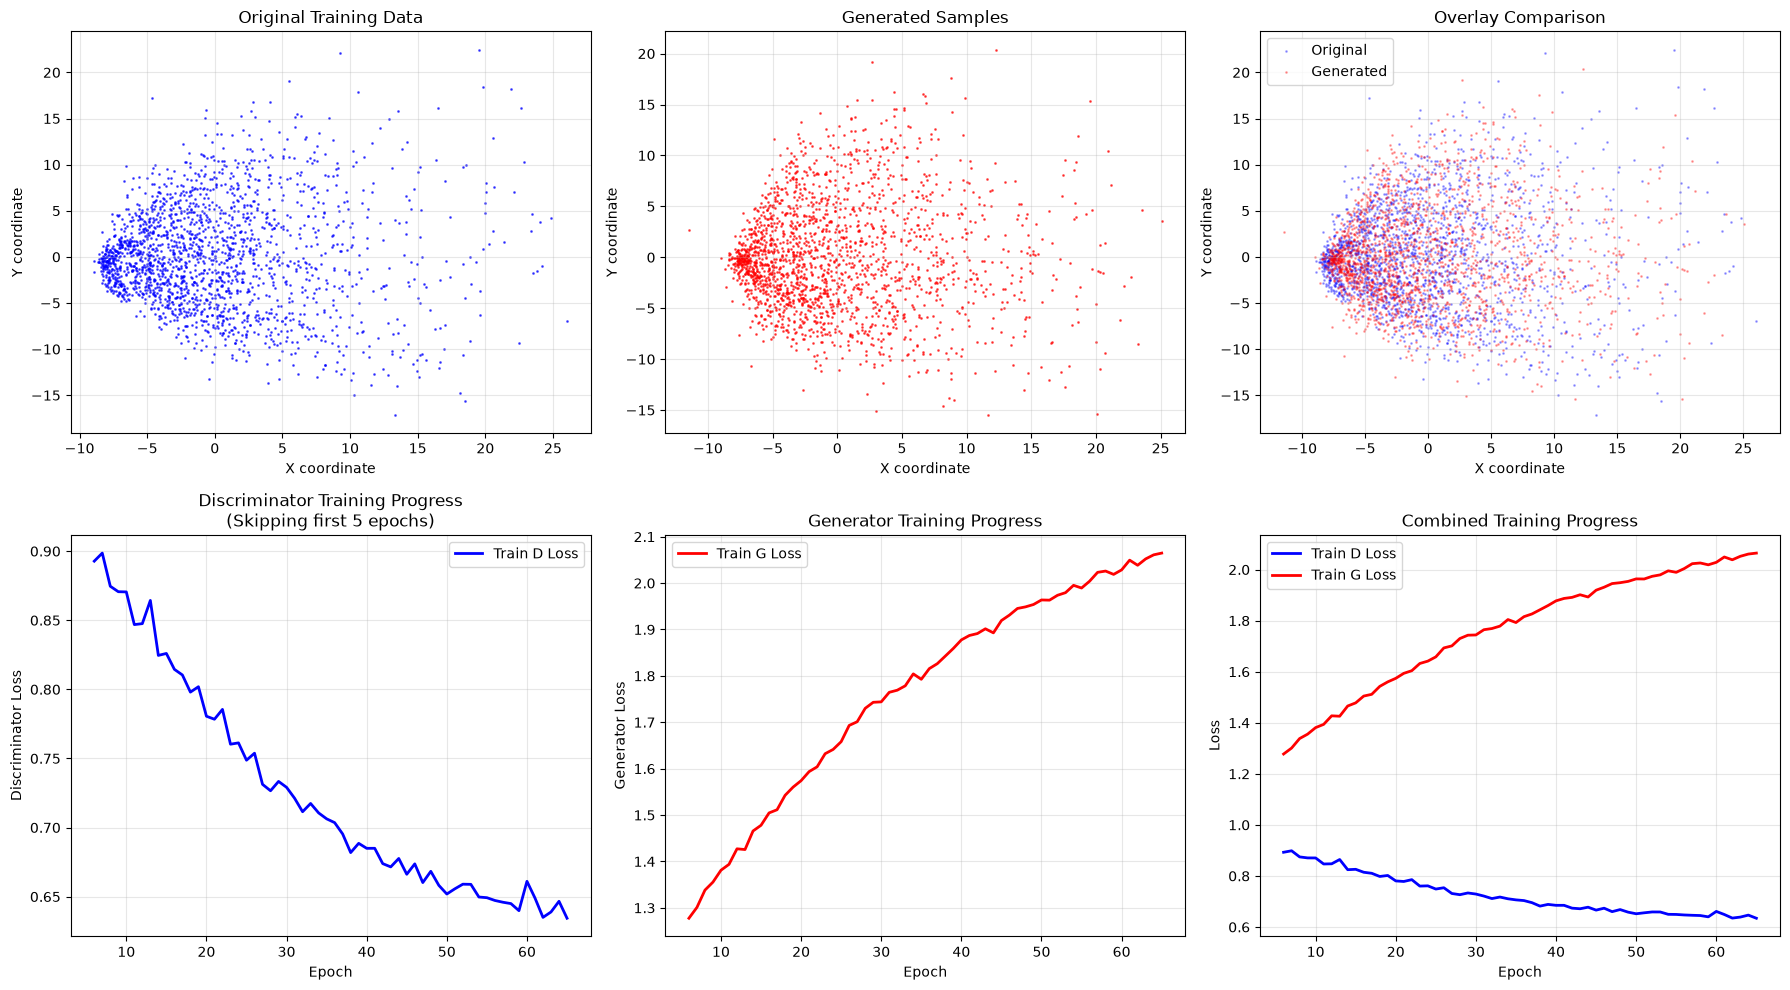

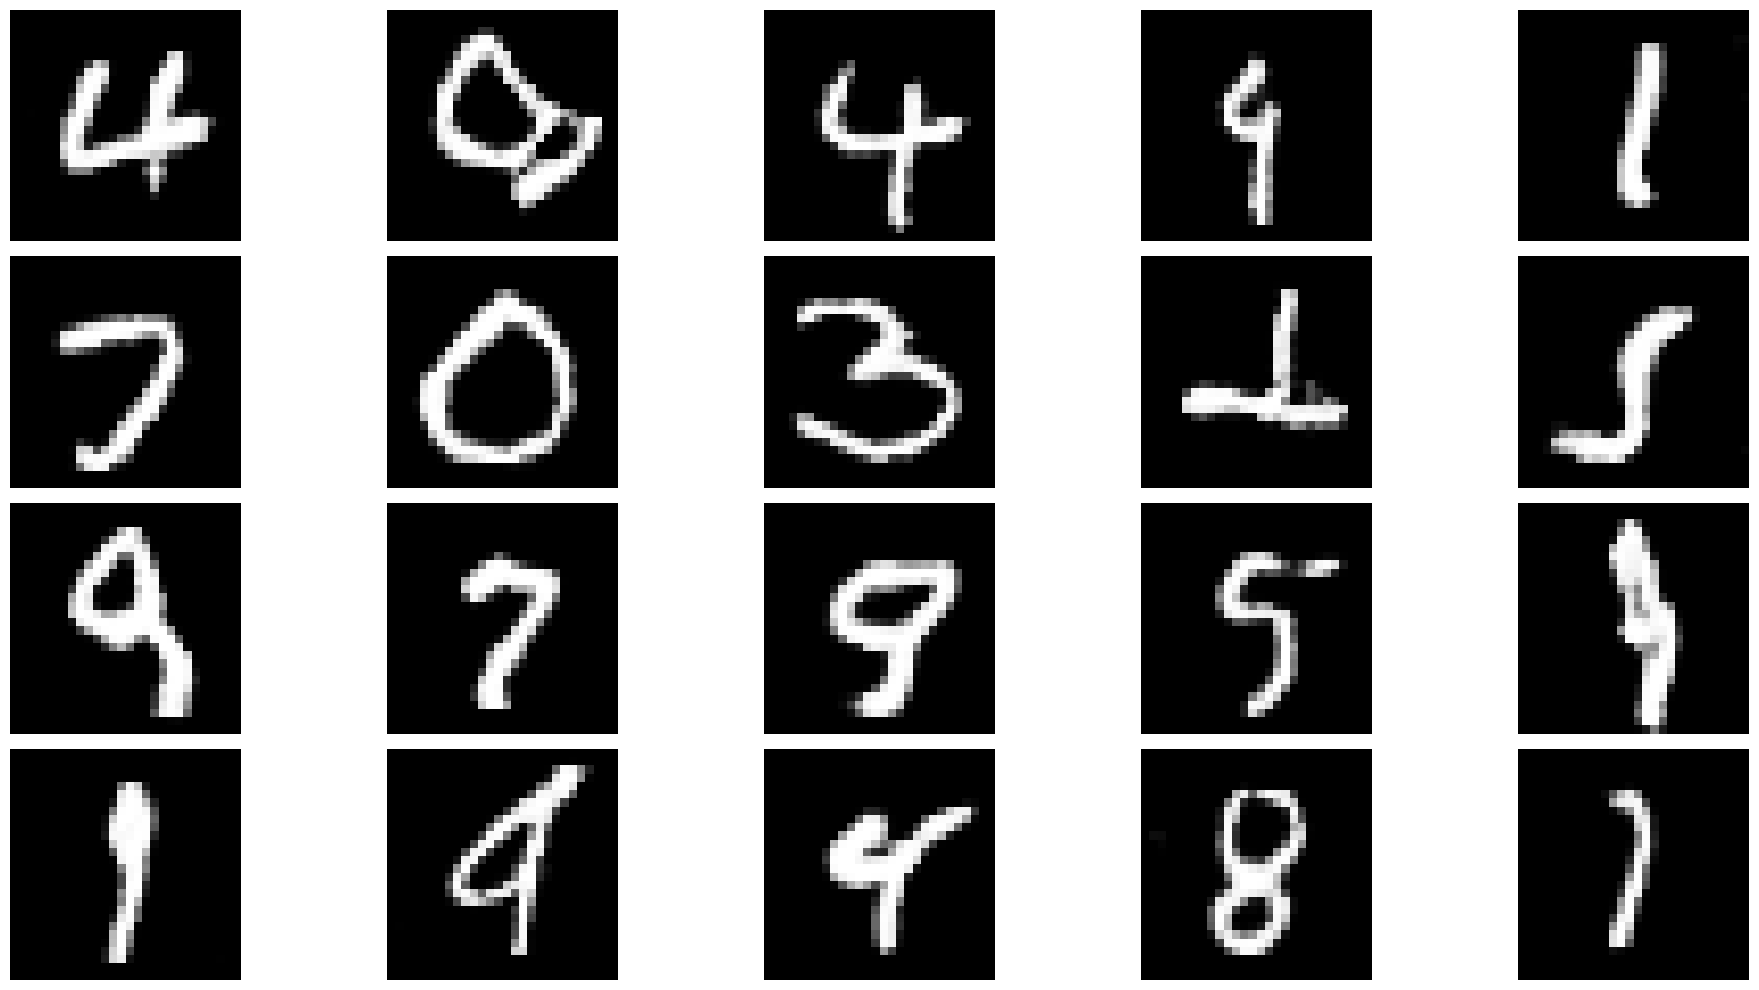

📈 Epoch 65 Summary:
   Train D Loss: 0.6344, Val D Loss: 1.1211
   Train G Loss: 2.0647, Val G Loss: 0.8882

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.735997	G_loss: 2.318436
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.628972	G_loss: 2.274137
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.465498	G_loss: 2.065655
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.552623	G_loss: 2.726592
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.496689	G_loss: 1.873188
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.645545	G_loss: 1.710074
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.589418	G_loss: 1.991849
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.651586	G_loss: 1.662106
Epoch: 66 [51200/60000 (85%)]	D_loss: 1.051597	G_loss: 1.284422
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.661723	G_loss: 1.894086
====> Epoch: 66 Train D_loss: 0.6226, Train G_loss: 2.0739
====> Epoch: 66 Val D_loss: 0.9455, Val G_loss: 1.4695
📈 Epoch 66 Summary:
   Train D Loss: 0.6226, Val D Loss: 0.9455
   Train G Loss: 2.0739

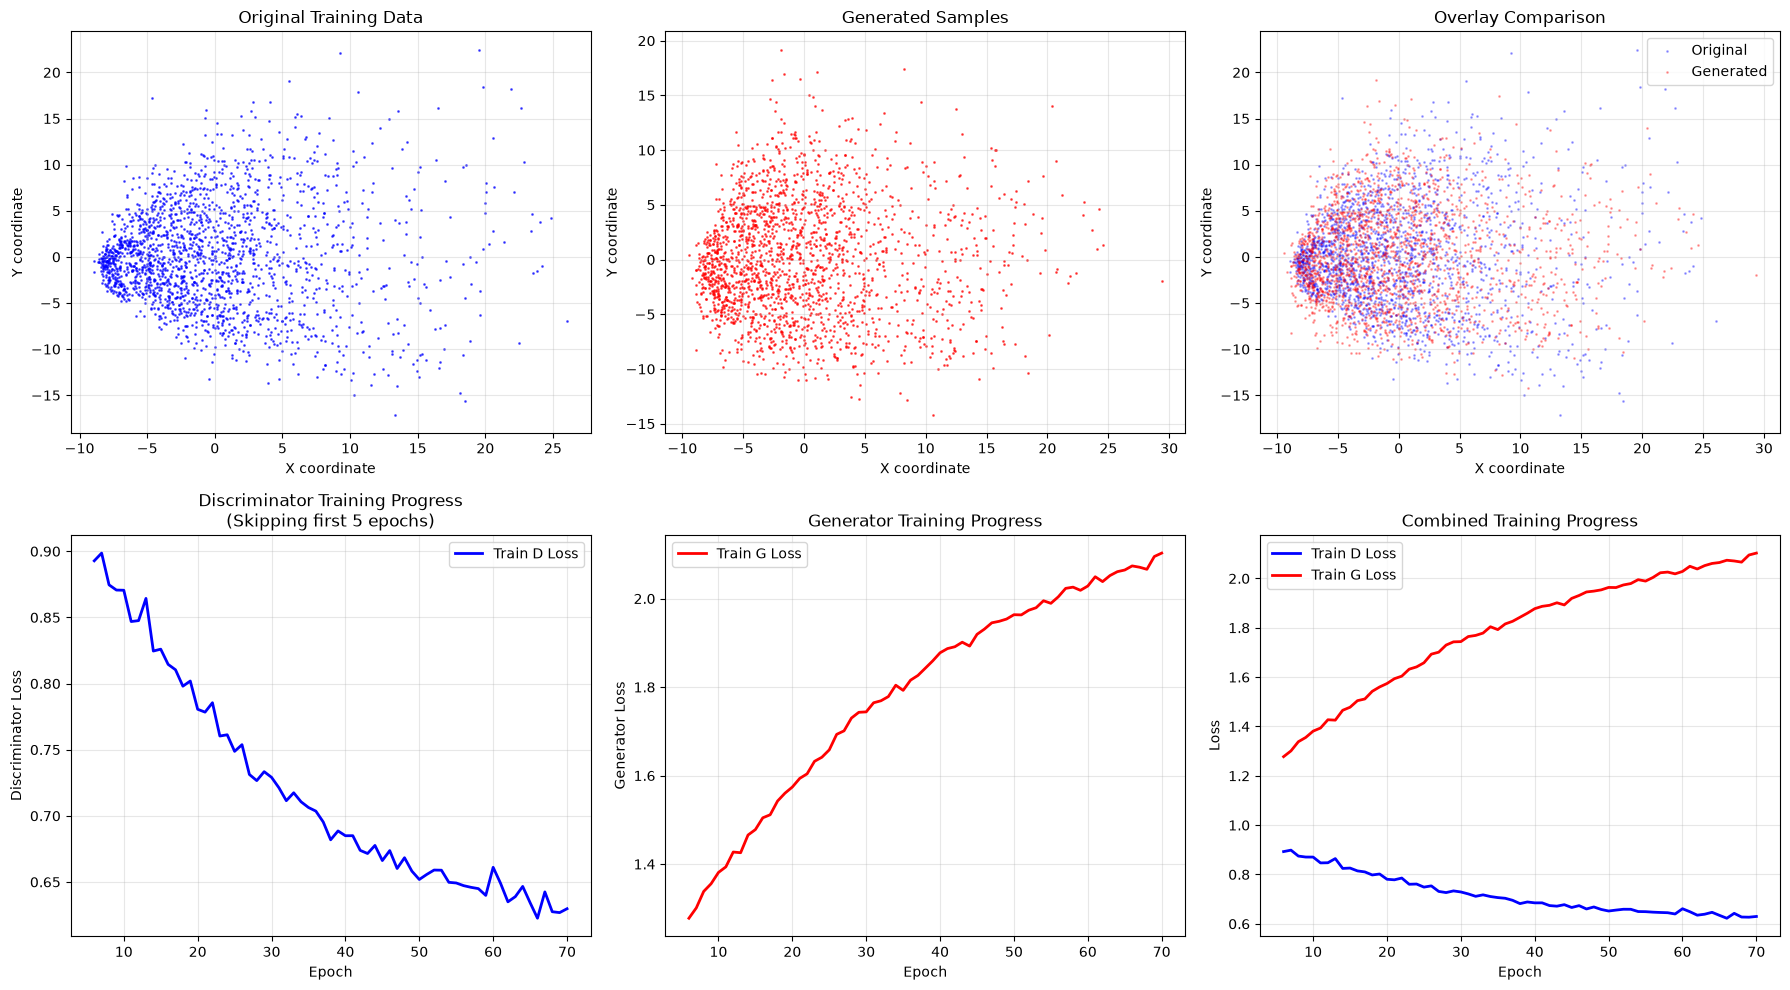

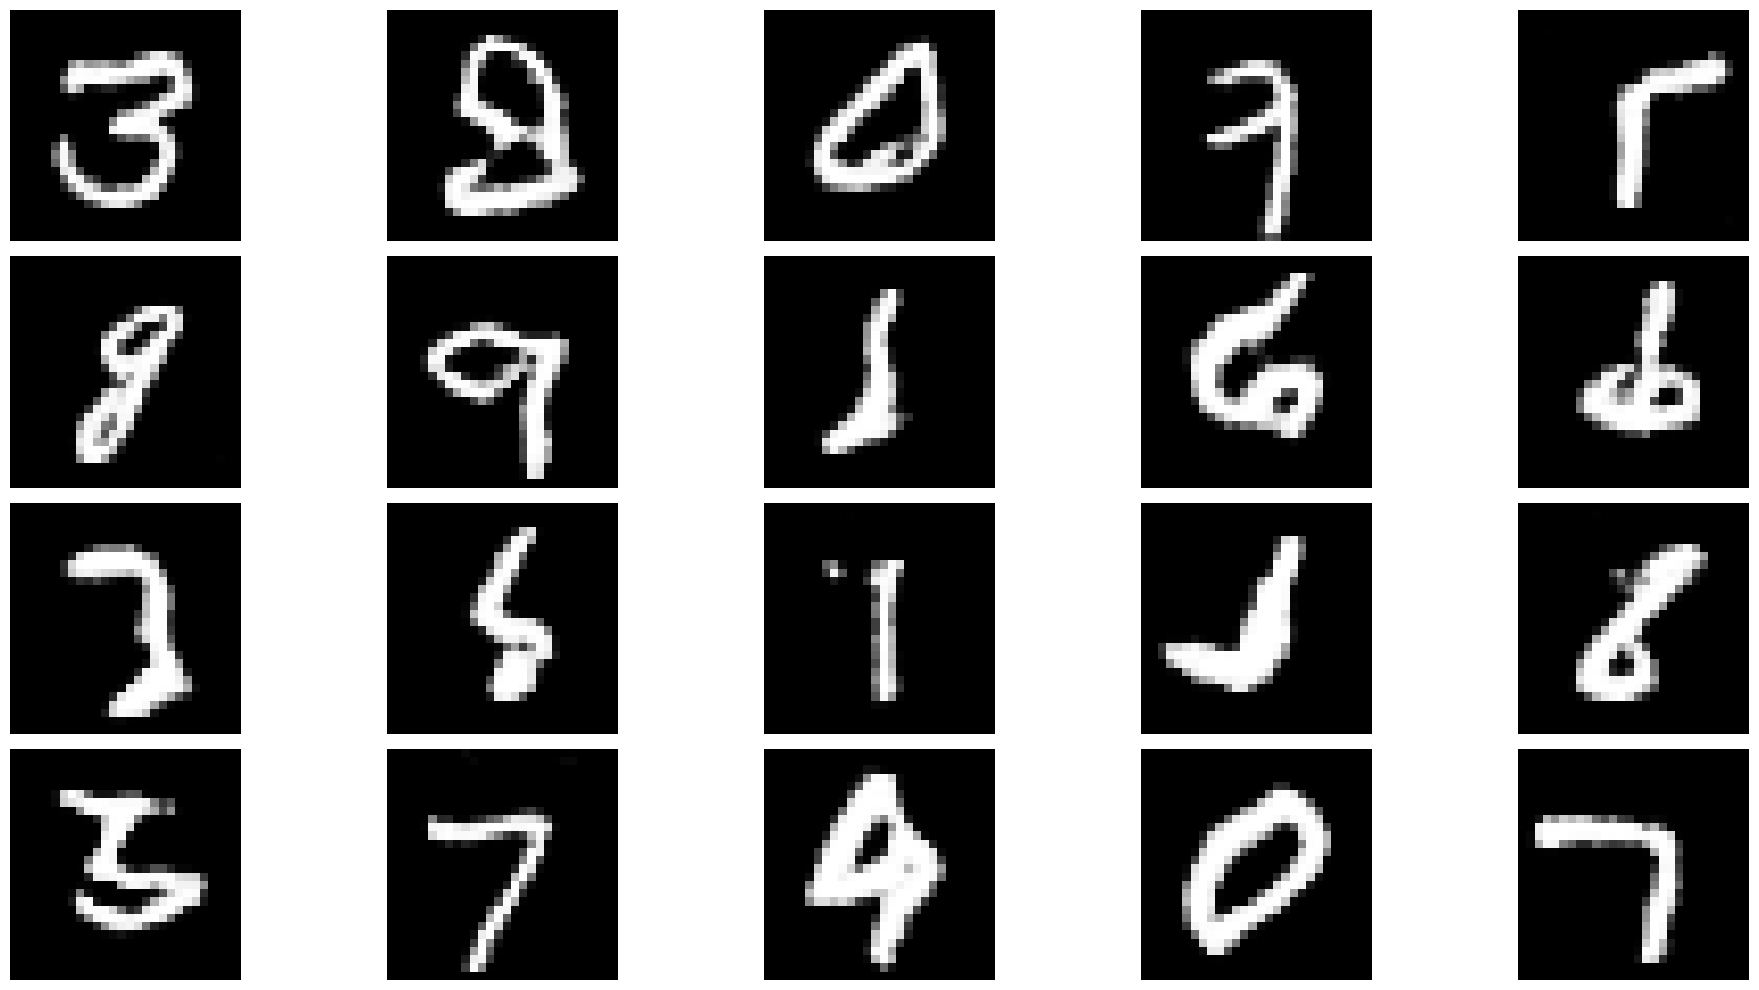

📈 Epoch 70 Summary:
   Train D Loss: 0.6298, Val D Loss: 1.0244
   Train G Loss: 2.1029, Val G Loss: 2.0413

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.560573	G_loss: 2.180120
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.644231	G_loss: 2.886874
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.466351	G_loss: 2.400374
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.503167	G_loss: 2.429522
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.611861	G_loss: 2.636505
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.569153	G_loss: 3.159296
Epoch: 71 [38400/60000 (64%)]	D_loss: 1.021608	G_loss: 3.479000
Epoch: 71 [44800/60000 (75%)]	D_loss: 1.153658	G_loss: 1.115830
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.576581	G_loss: 2.337854
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.509603	G_loss: 2.022579
====> Epoch: 71 Train D_loss: 0.6347, Train G_loss: 2.1032
====> Epoch: 71 Val D_loss: 1.0109, Val G_loss: 1.7861
📈 Epoch 71 Summary:
   Train D Loss: 0.6347, Val D Loss: 1.0109
   Train G Loss: 2.1032

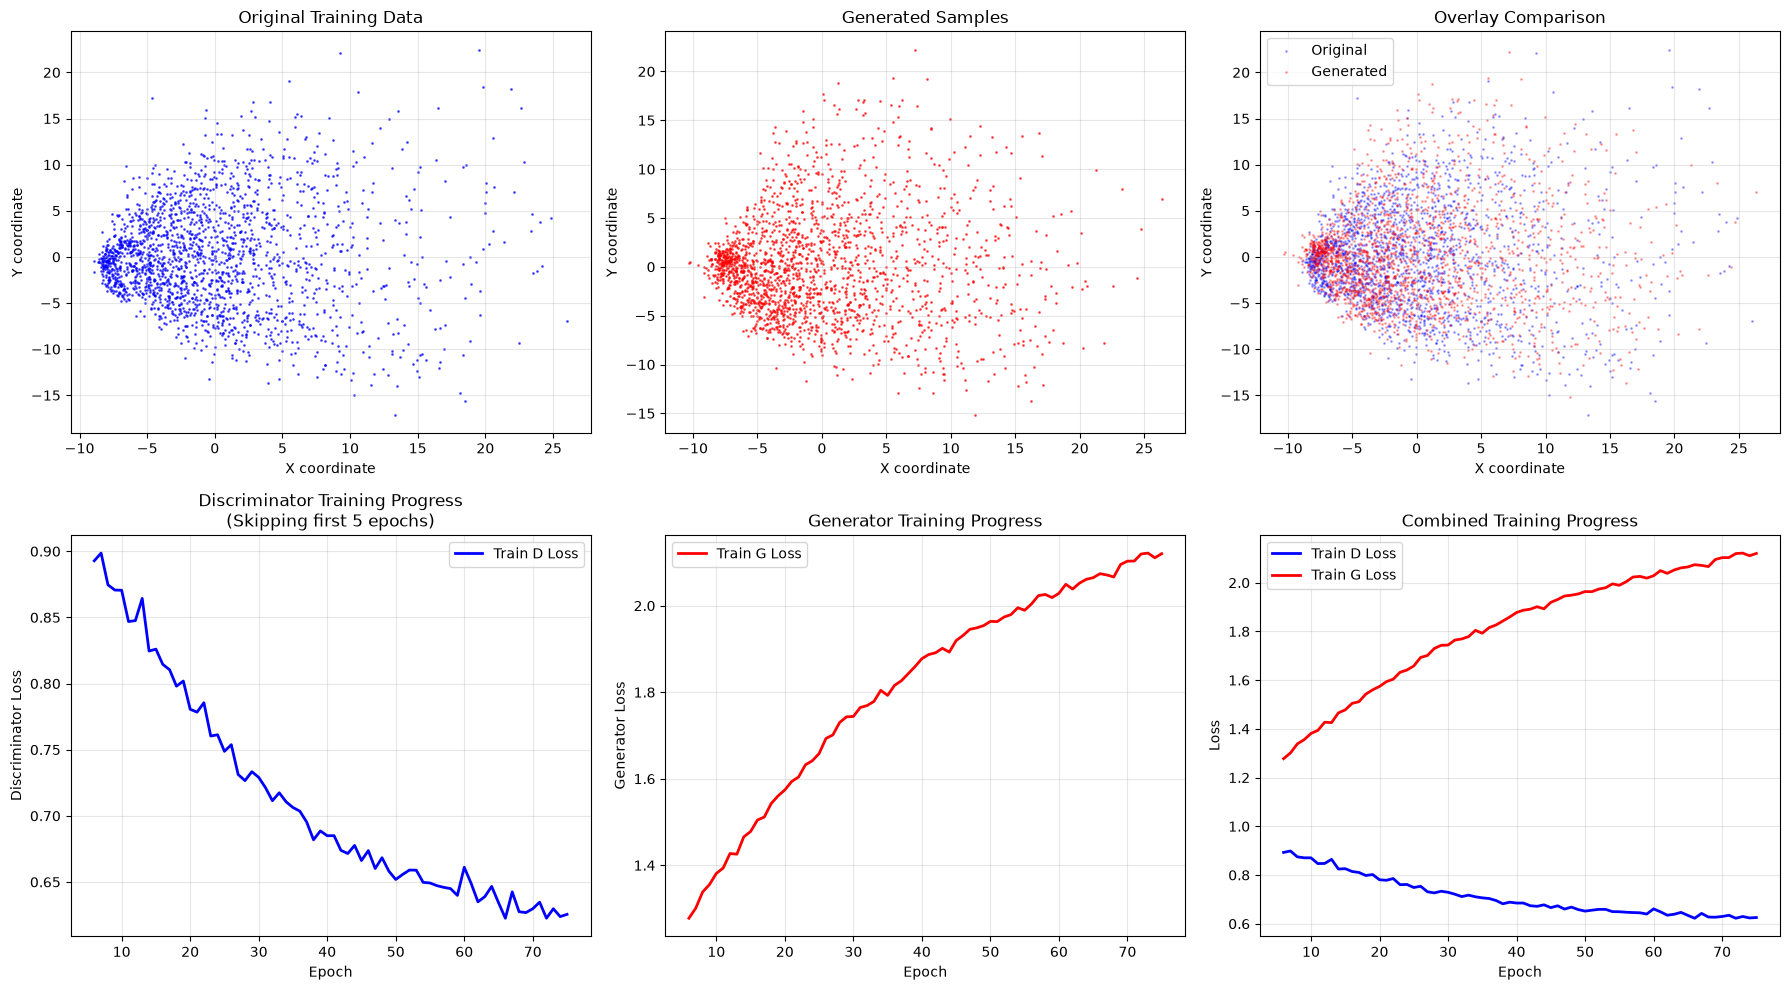

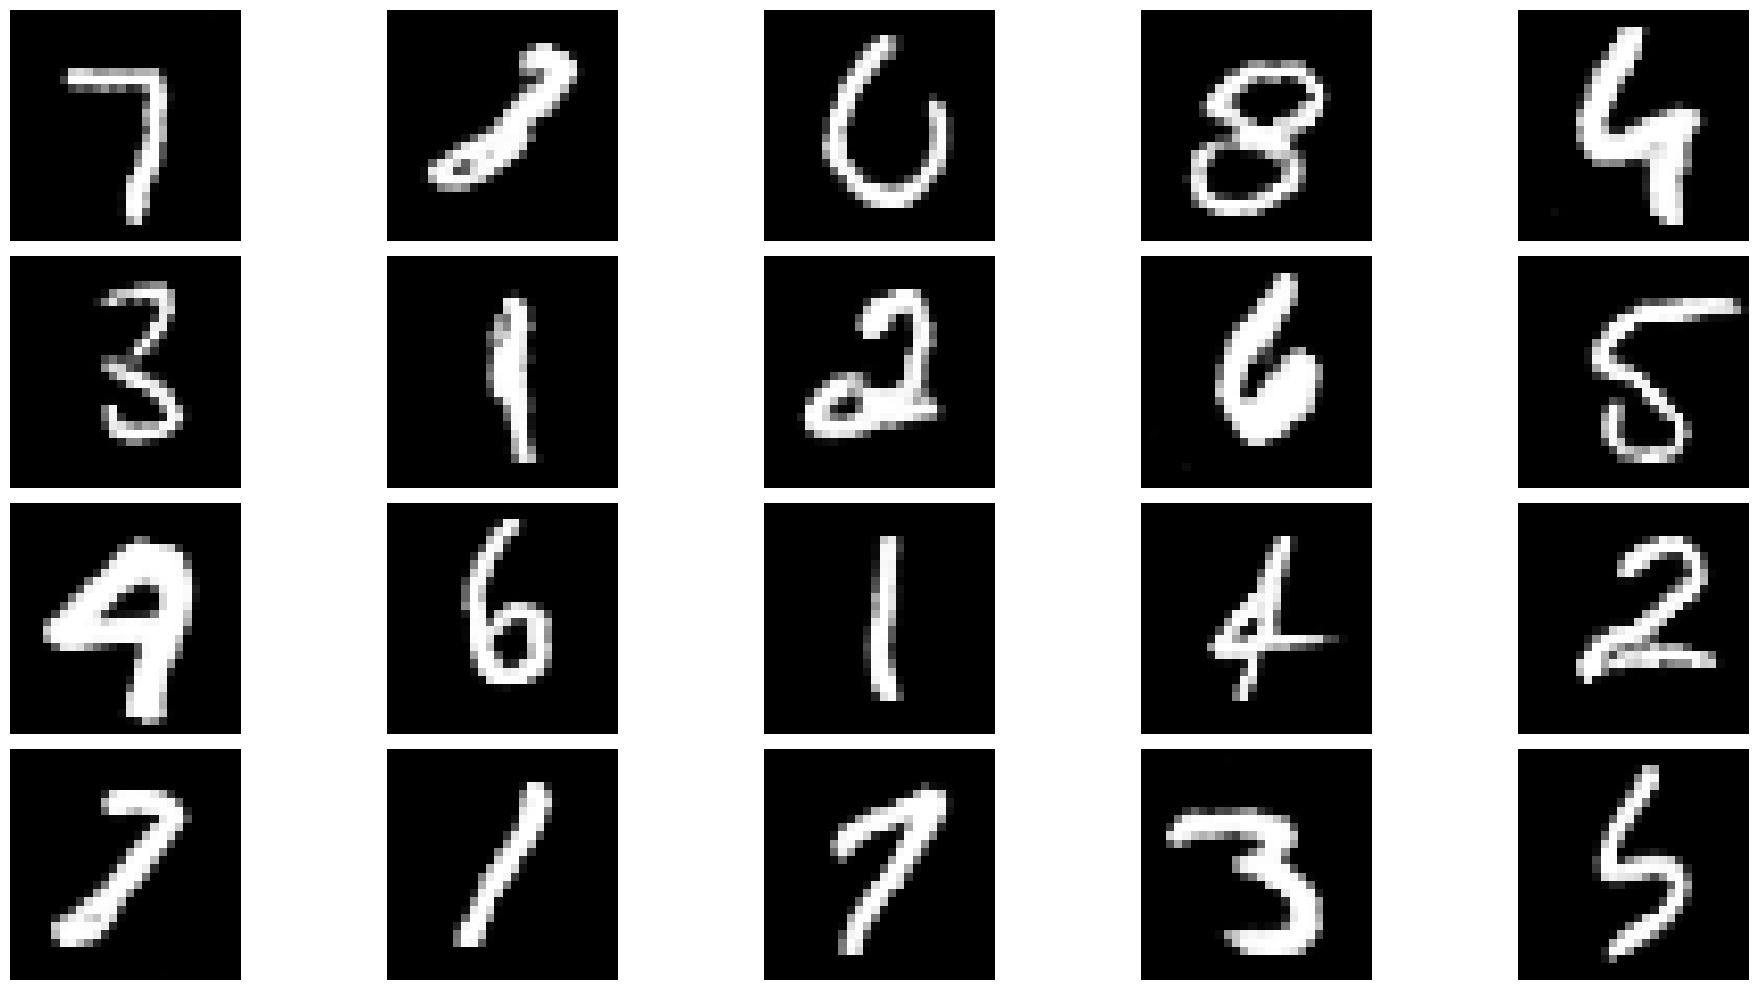

📈 Epoch 75 Summary:
   Train D Loss: 0.6255, Val D Loss: 1.0957
   Train G Loss: 2.1202, Val G Loss: 1.0073

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.645601	G_loss: 1.836033
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.868610	G_loss: 3.711300
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.496131	G_loss: 2.431992
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.644408	G_loss: 2.021547
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.742008	G_loss: 1.327633
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.604011	G_loss: 2.723637
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.520055	G_loss: 1.695860
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.625358	G_loss: 2.250180
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.894499	G_loss: 3.590340
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.913262	G_loss: 3.586500
====> Epoch: 76 Train D_loss: 0.6280, Train G_loss: 2.1243
====> Epoch: 76 Val D_loss: 0.9917, Val G_loss: 1.9114
📈 Epoch 76 Summary:
   Train D Loss: 0.6280, Val D Loss: 0.9917
   Train G Loss: 2.1243

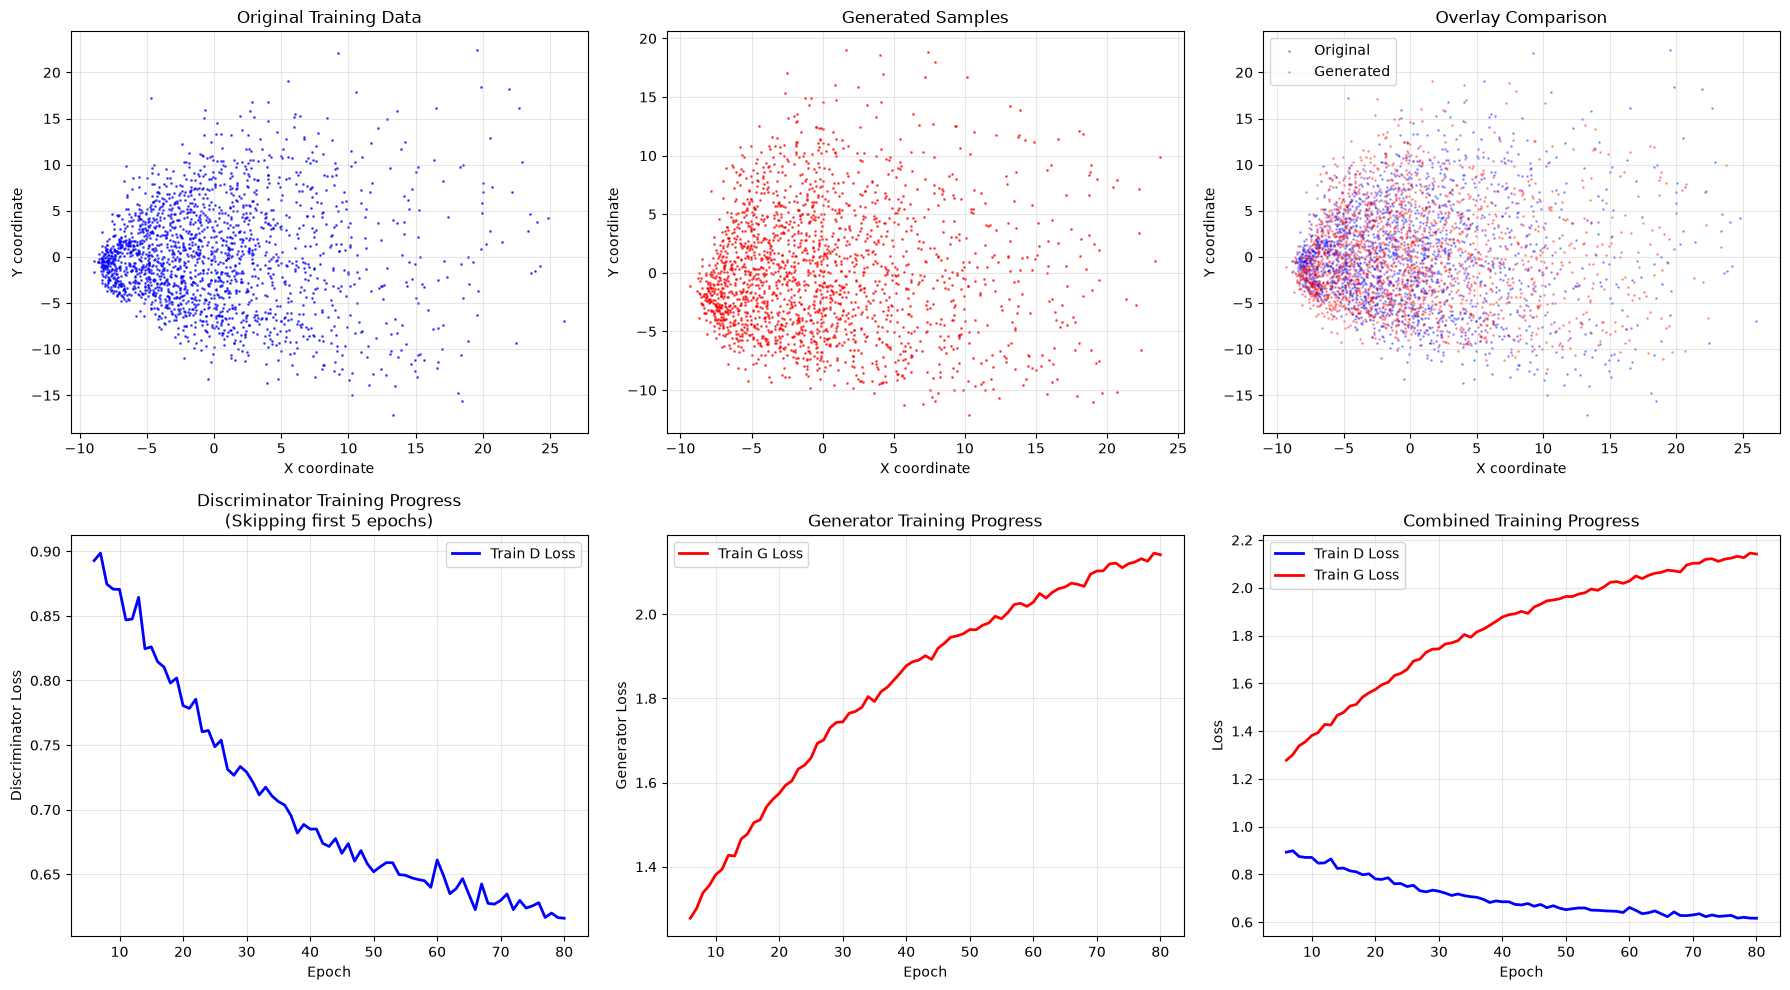

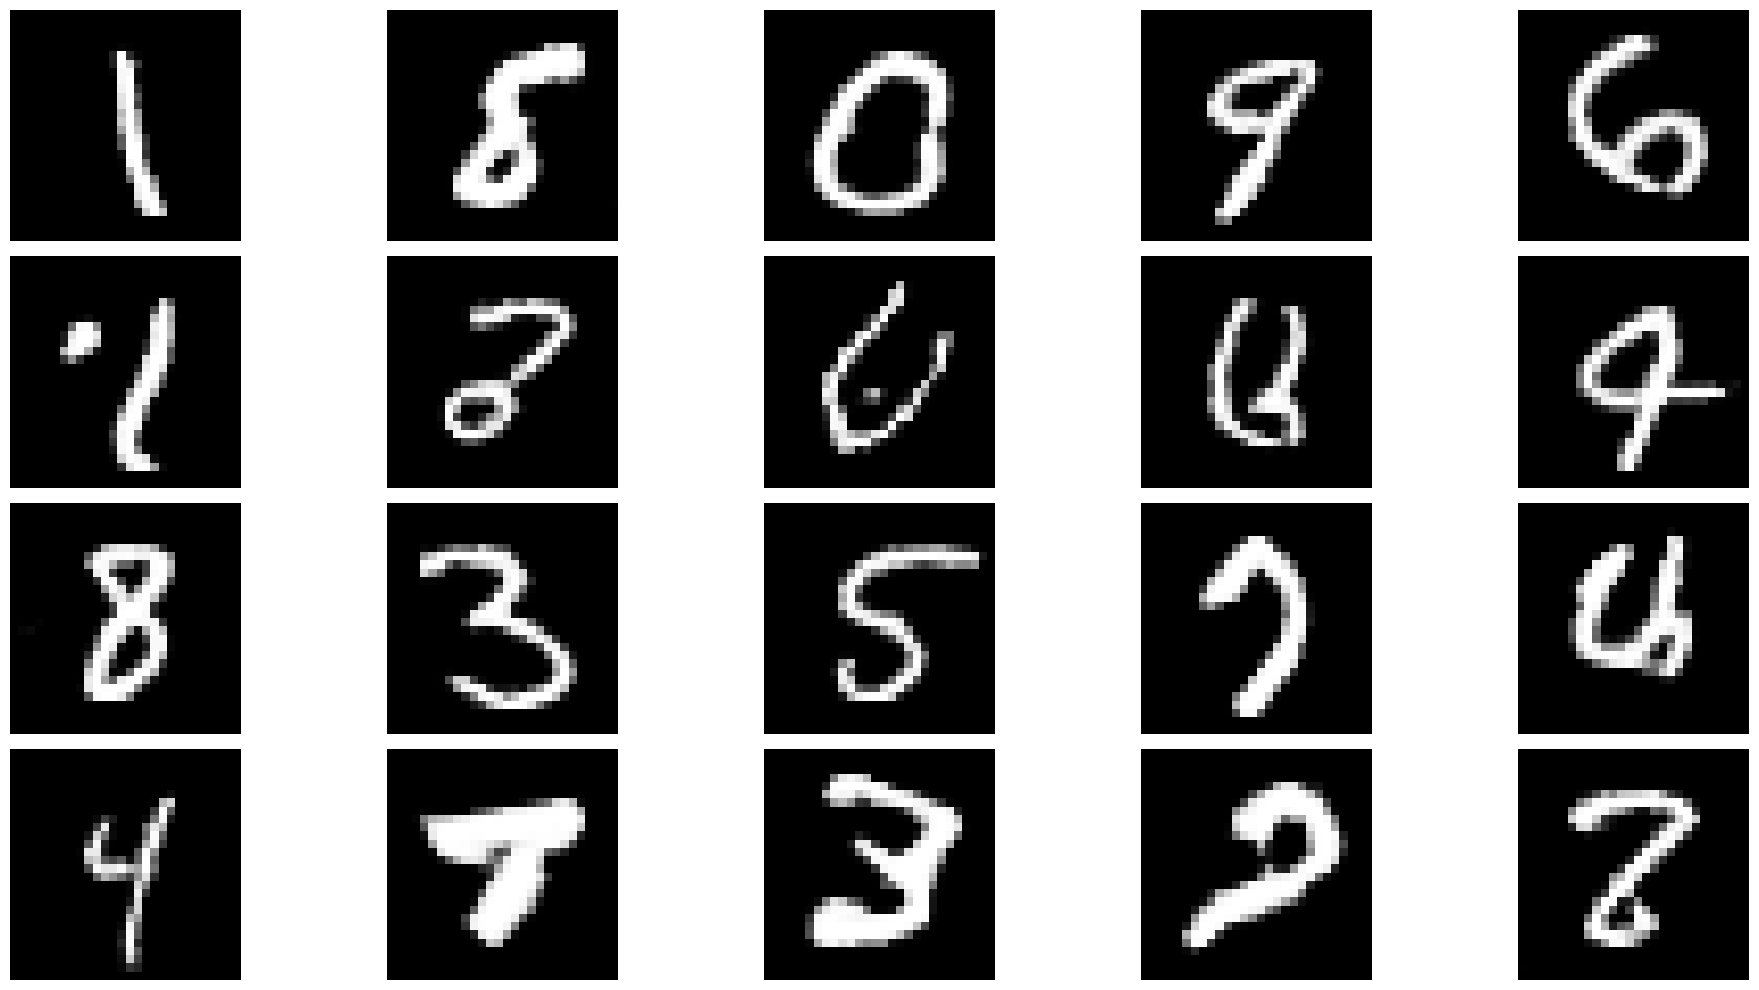

📈 Epoch 80 Summary:
   Train D Loss: 0.6160, Val D Loss: 1.0054
   Train G Loss: 2.1414, Val G Loss: 1.8606

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.453812	G_loss: 2.487764
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.835787	G_loss: 3.549229
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.465669	G_loss: 2.298010
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.528188	G_loss: 2.649537
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.618309	G_loss: 1.690266
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.548502	G_loss: 2.005924
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.540145	G_loss: 1.643699
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.498451	G_loss: 2.129335
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.573419	G_loss: 1.064759
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.705138	G_loss: 1.382987
====> Epoch: 81 Train D_loss: 0.6246, Train G_loss: 2.1478
====> Epoch: 81 Val D_loss: 0.9916, Val G_loss: 1.2589
📈 Epoch 81 Summary:
   Train D Loss: 0.6246, Val D Loss: 0.9916
   Train G Loss: 2.1478

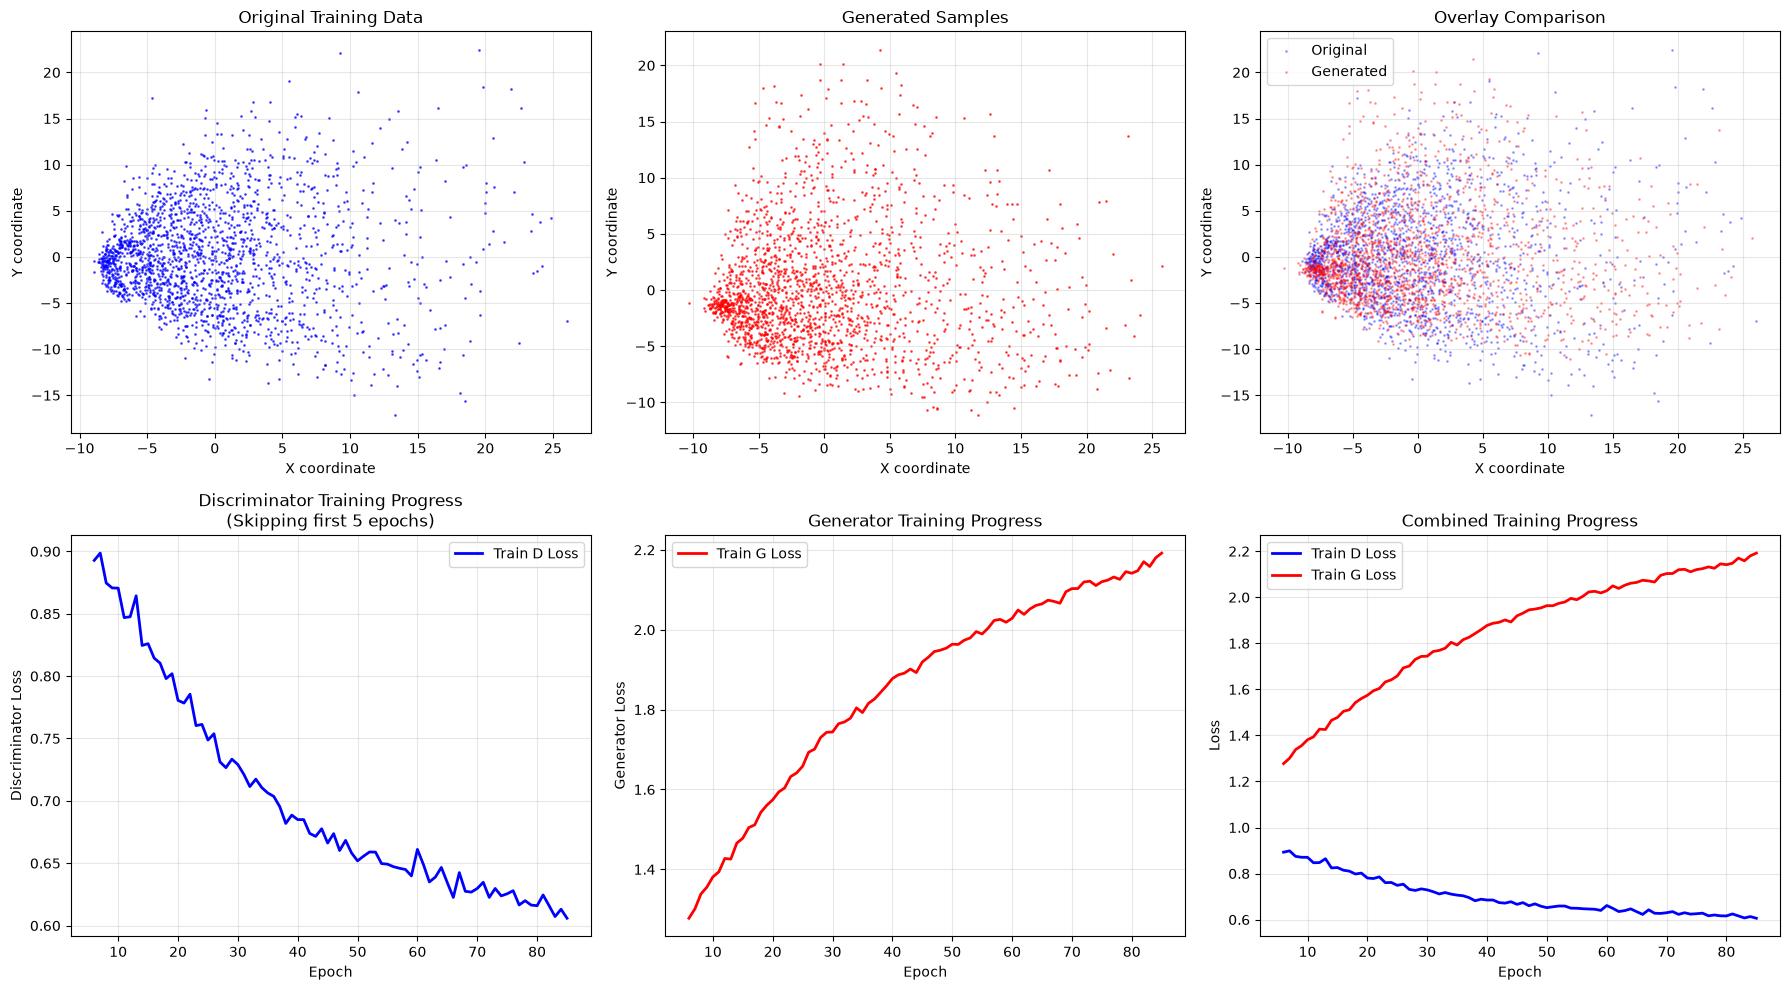

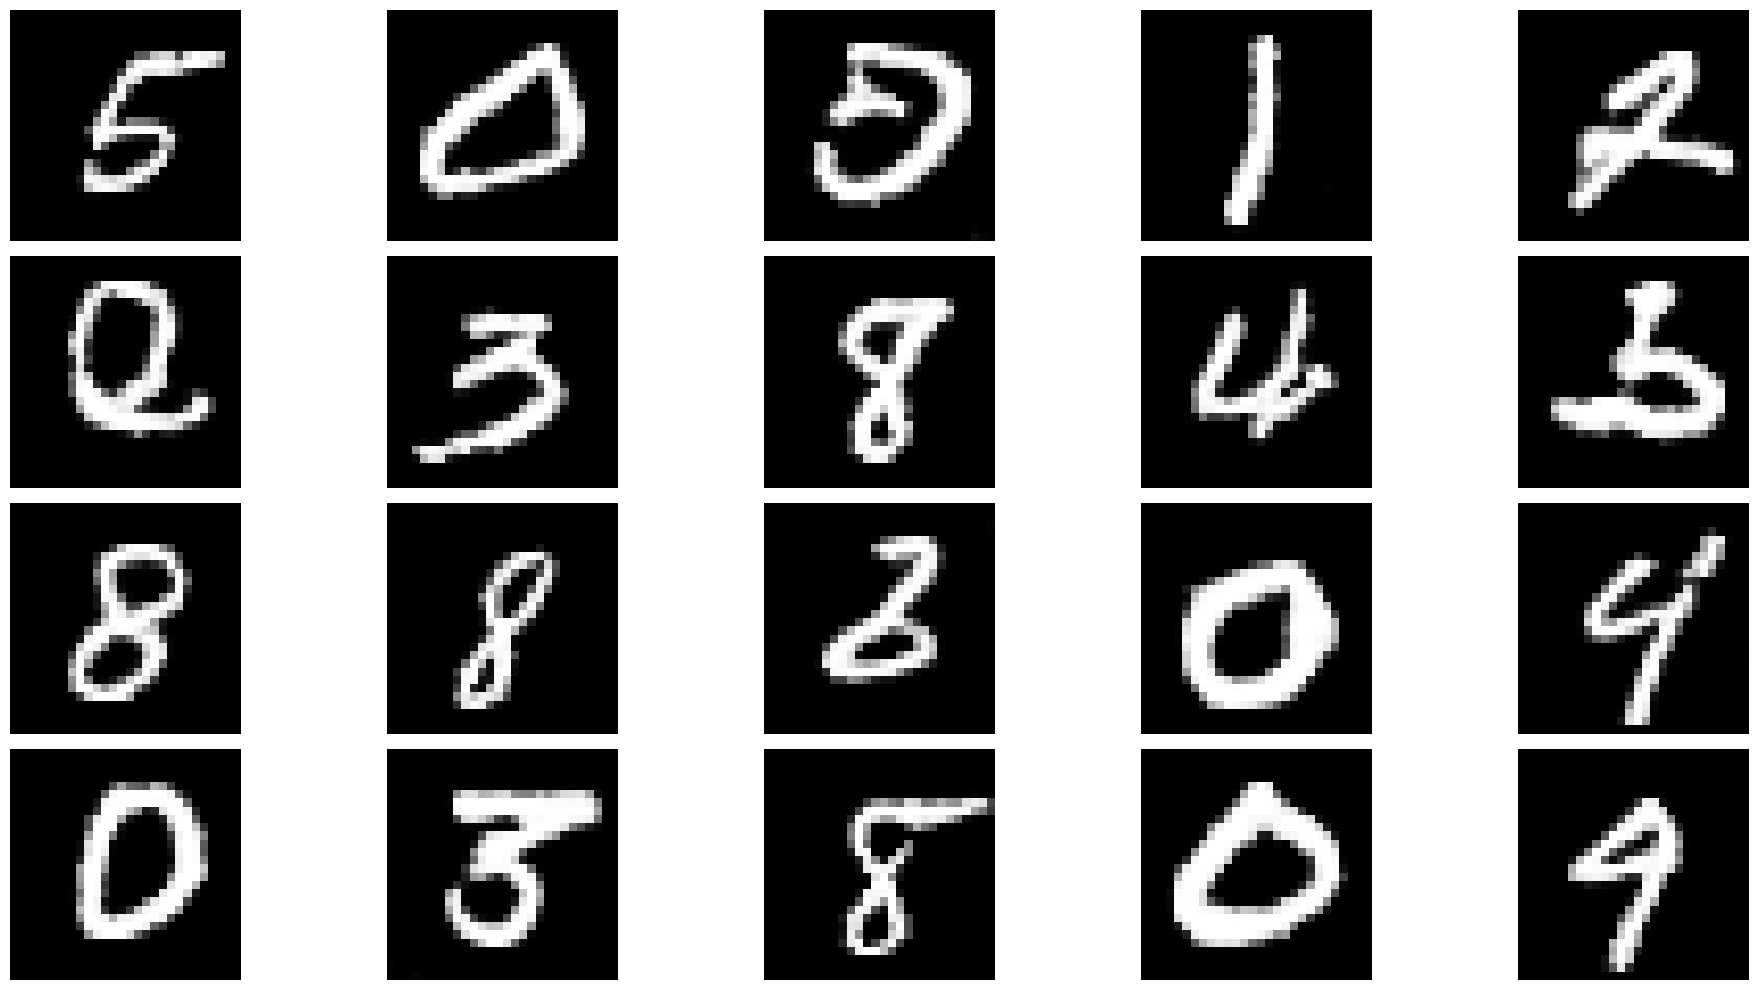

📈 Epoch 85 Summary:
   Train D Loss: 0.6059, Val D Loss: 0.9507
   Train G Loss: 2.1919, Val G Loss: 1.5861

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.486413	G_loss: 3.098417
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.749897	G_loss: 3.083724
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.494831	G_loss: 2.241118
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.683671	G_loss: 3.206762
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.670031	G_loss: 2.375387
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.716383	G_loss: 3.409626
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.703627	G_loss: 1.131781
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.569499	G_loss: 2.172577
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.741054	G_loss: 1.295977
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.576786	G_loss: 2.094445
====> Epoch: 86 Train D_loss: 0.6110, Train G_loss: 2.1758
====> Epoch: 86 Val D_loss: 1.0372, Val G_loss: 1.1281
📈 Epoch 86 Summary:
   Train D Loss: 0.6110, Val D Loss: 1.0372
   Train G Loss: 2.1758

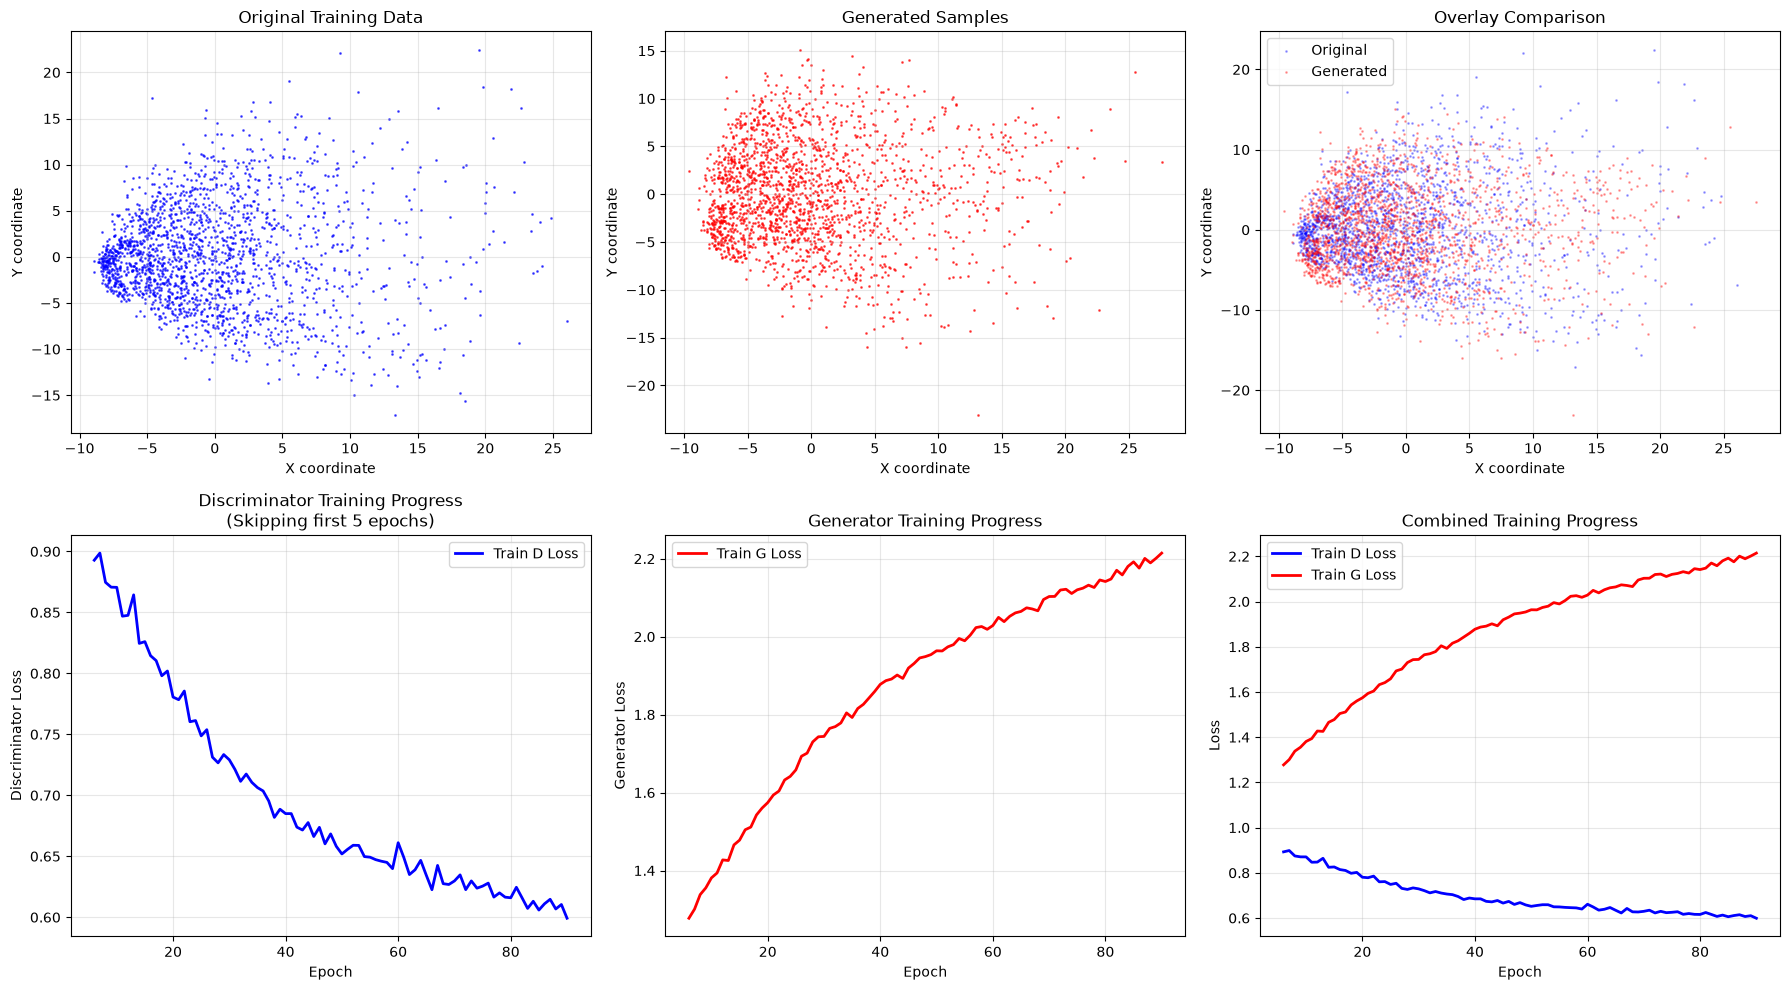

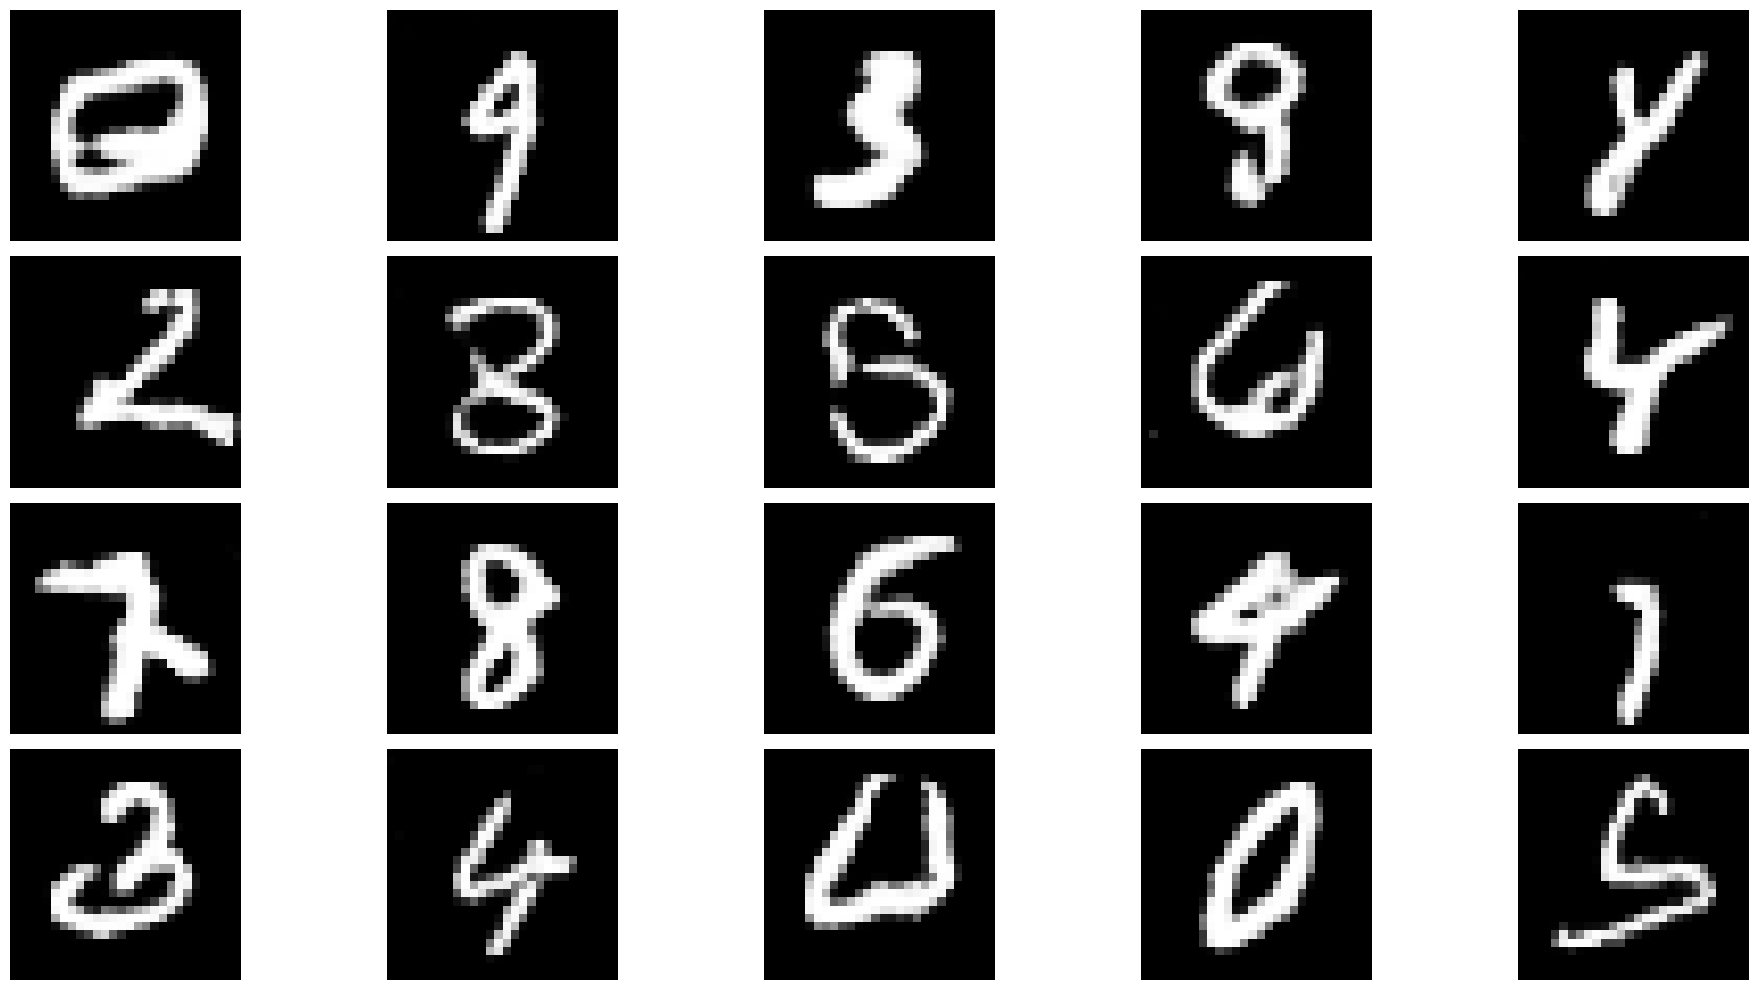

📈 Epoch 90 Summary:
   Train D Loss: 0.5992, Val D Loss: 1.0302
   Train G Loss: 2.2143, Val G Loss: 2.0121

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.458907	G_loss: 2.566024
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.441761	G_loss: 2.376538
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.402399	G_loss: 1.954846
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.501588	G_loss: 1.956637
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.601820	G_loss: 1.916726
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.423650	G_loss: 3.063219
Epoch: 91 [38400/60000 (64%)]	D_loss: 1.022382	G_loss: 2.988956
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.634734	G_loss: 2.346519
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.652128	G_loss: 2.592072
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.445515	G_loss: 2.726627
====> Epoch: 91 Train D_loss: 0.6027, Train G_loss: 2.2158
====> Epoch: 91 Val D_loss: 0.9952, Val G_loss: 1.5883
📈 Epoch 91 Summary:
   Train D Loss: 0.6027, Val D Loss: 0.9952
   Train G Loss: 2.2158

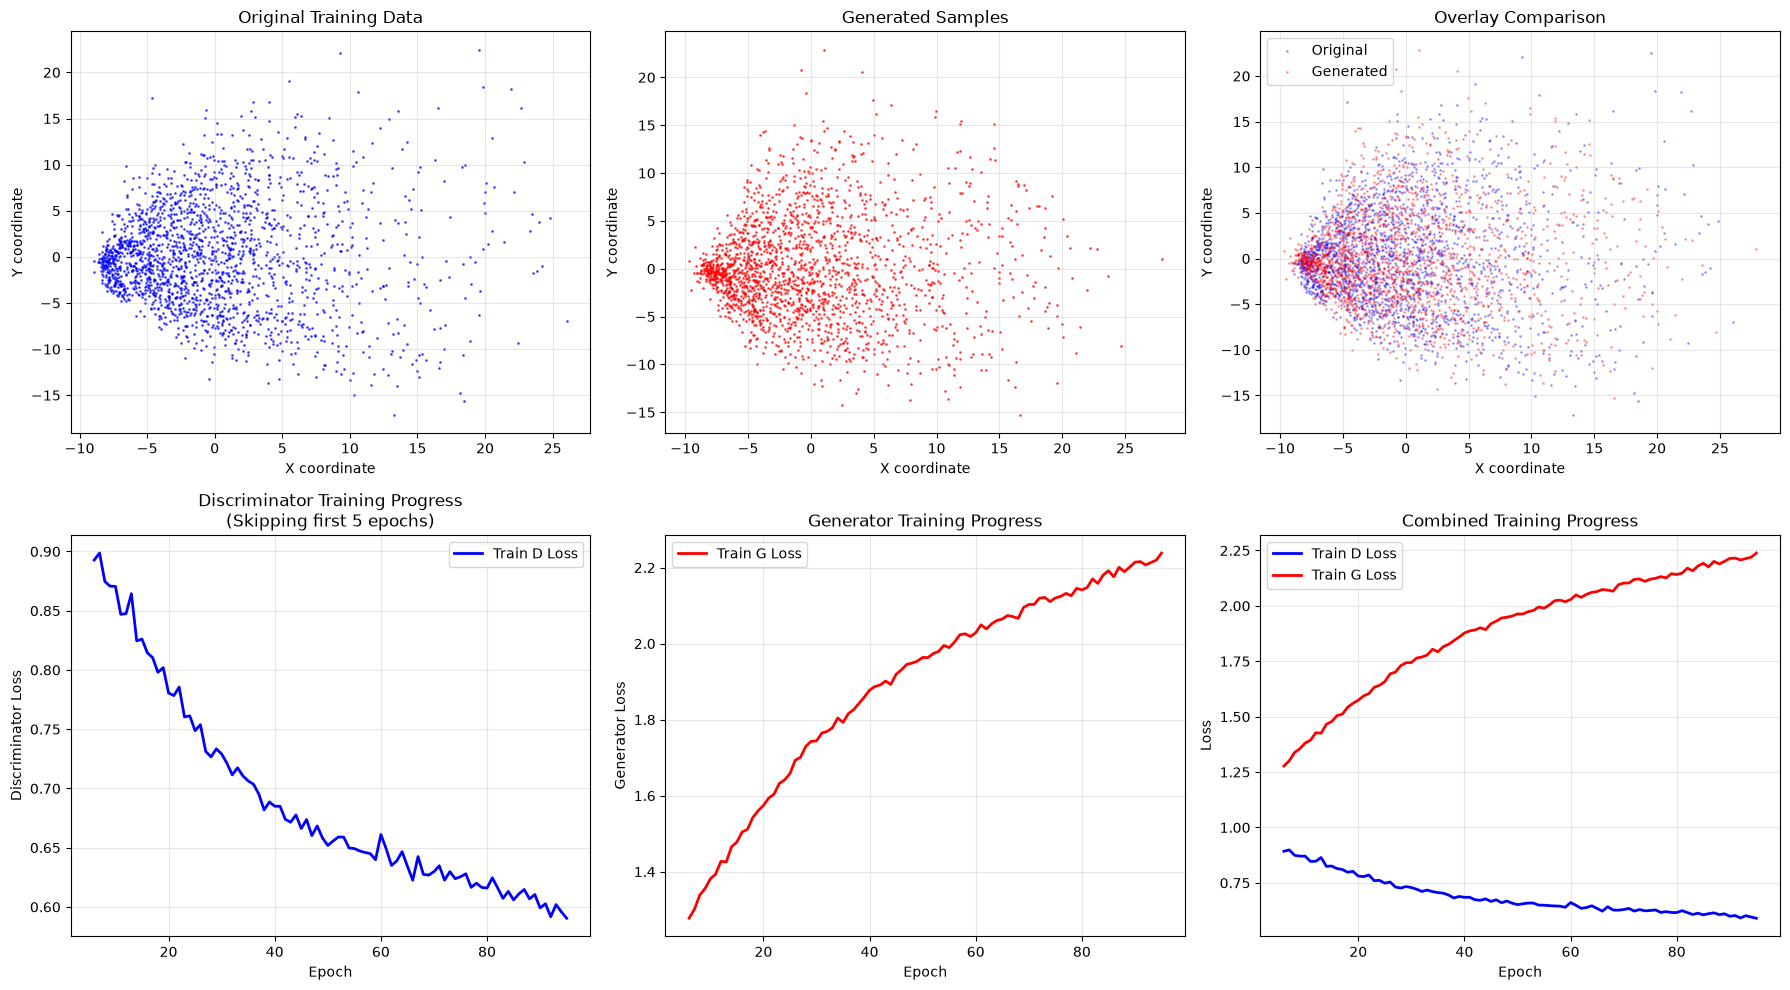

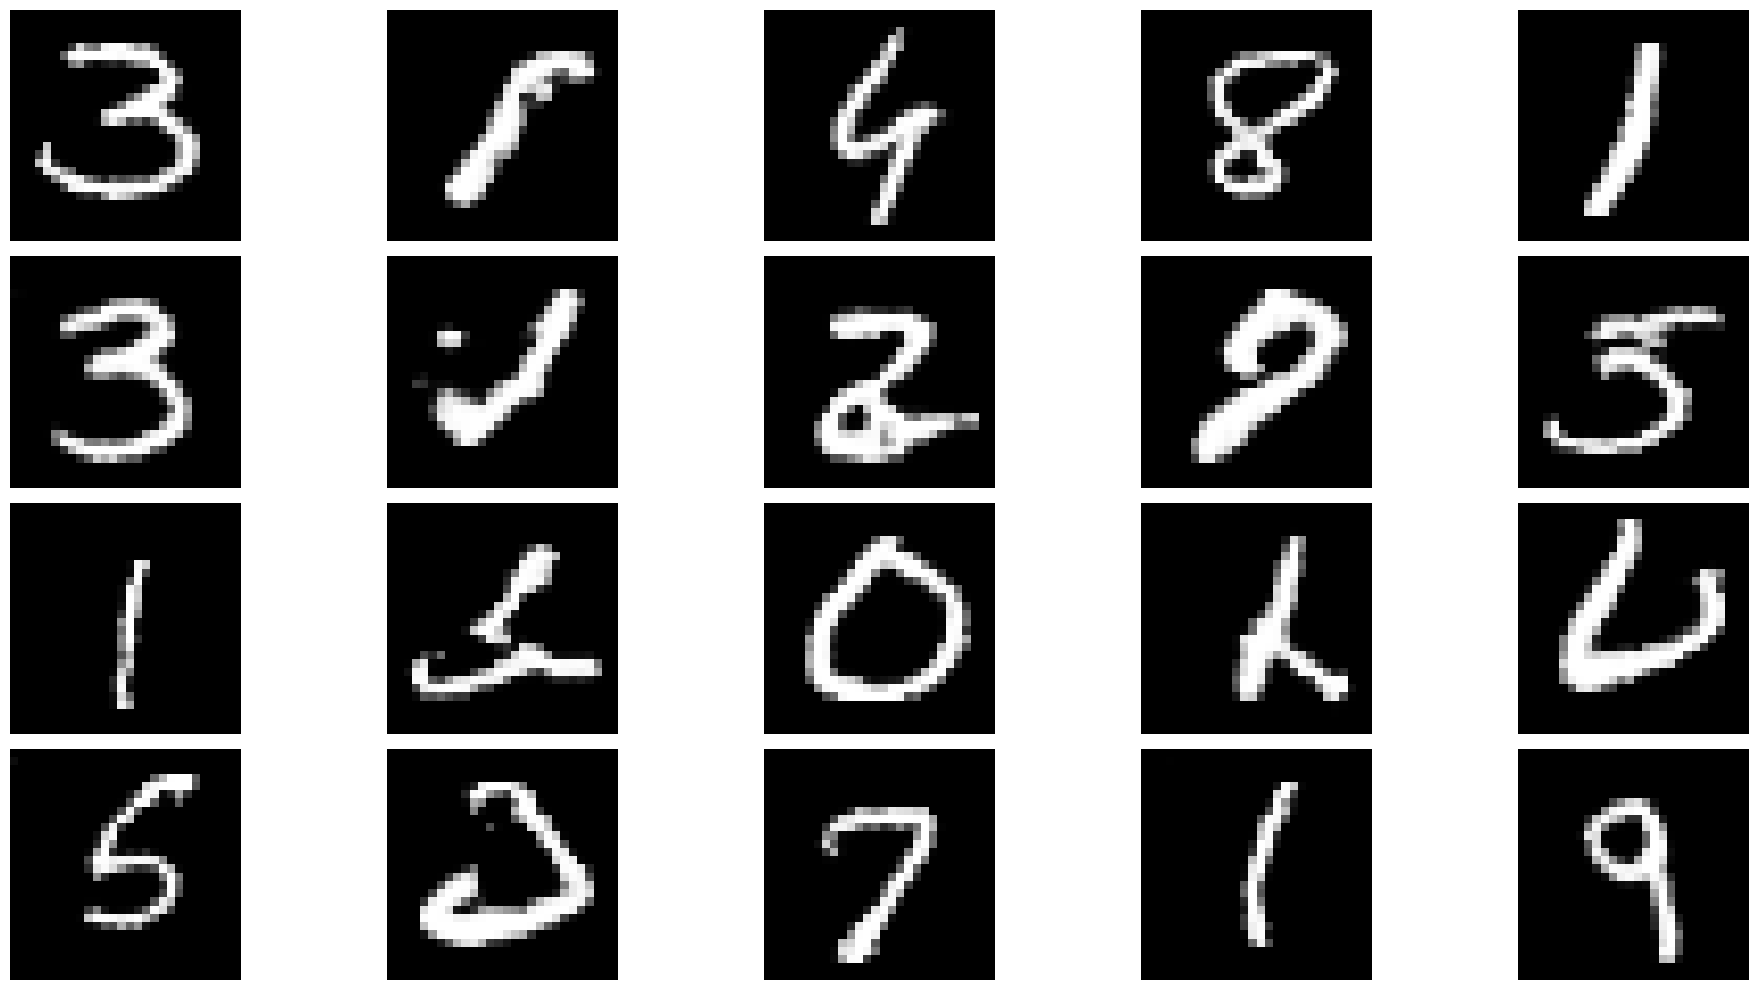

📈 Epoch 95 Summary:
   Train D Loss: 0.5904, Val D Loss: 1.3164
   Train G Loss: 2.2381, Val G Loss: 0.8476

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.860379	G_loss: 3.018011
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.559369	G_loss: 2.380526
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.572783	G_loss: 1.831167
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.624730	G_loss: 3.206442
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.577438	G_loss: 2.112550
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.765354	G_loss: 1.383224
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.542676	G_loss: 1.343794
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.581400	G_loss: 2.000657
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.512940	G_loss: 1.769428
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.668248	G_loss: 1.242900
====> Epoch: 96 Train D_loss: 0.6022, Train G_loss: 2.2288
====> Epoch: 96 Val D_loss: 1.0372, Val G_loss: 1.1598
📈 Epoch 96 Summary:
   Train D Loss: 0.6022, Val D Loss: 1.0372
   Train G Loss: 2.2288

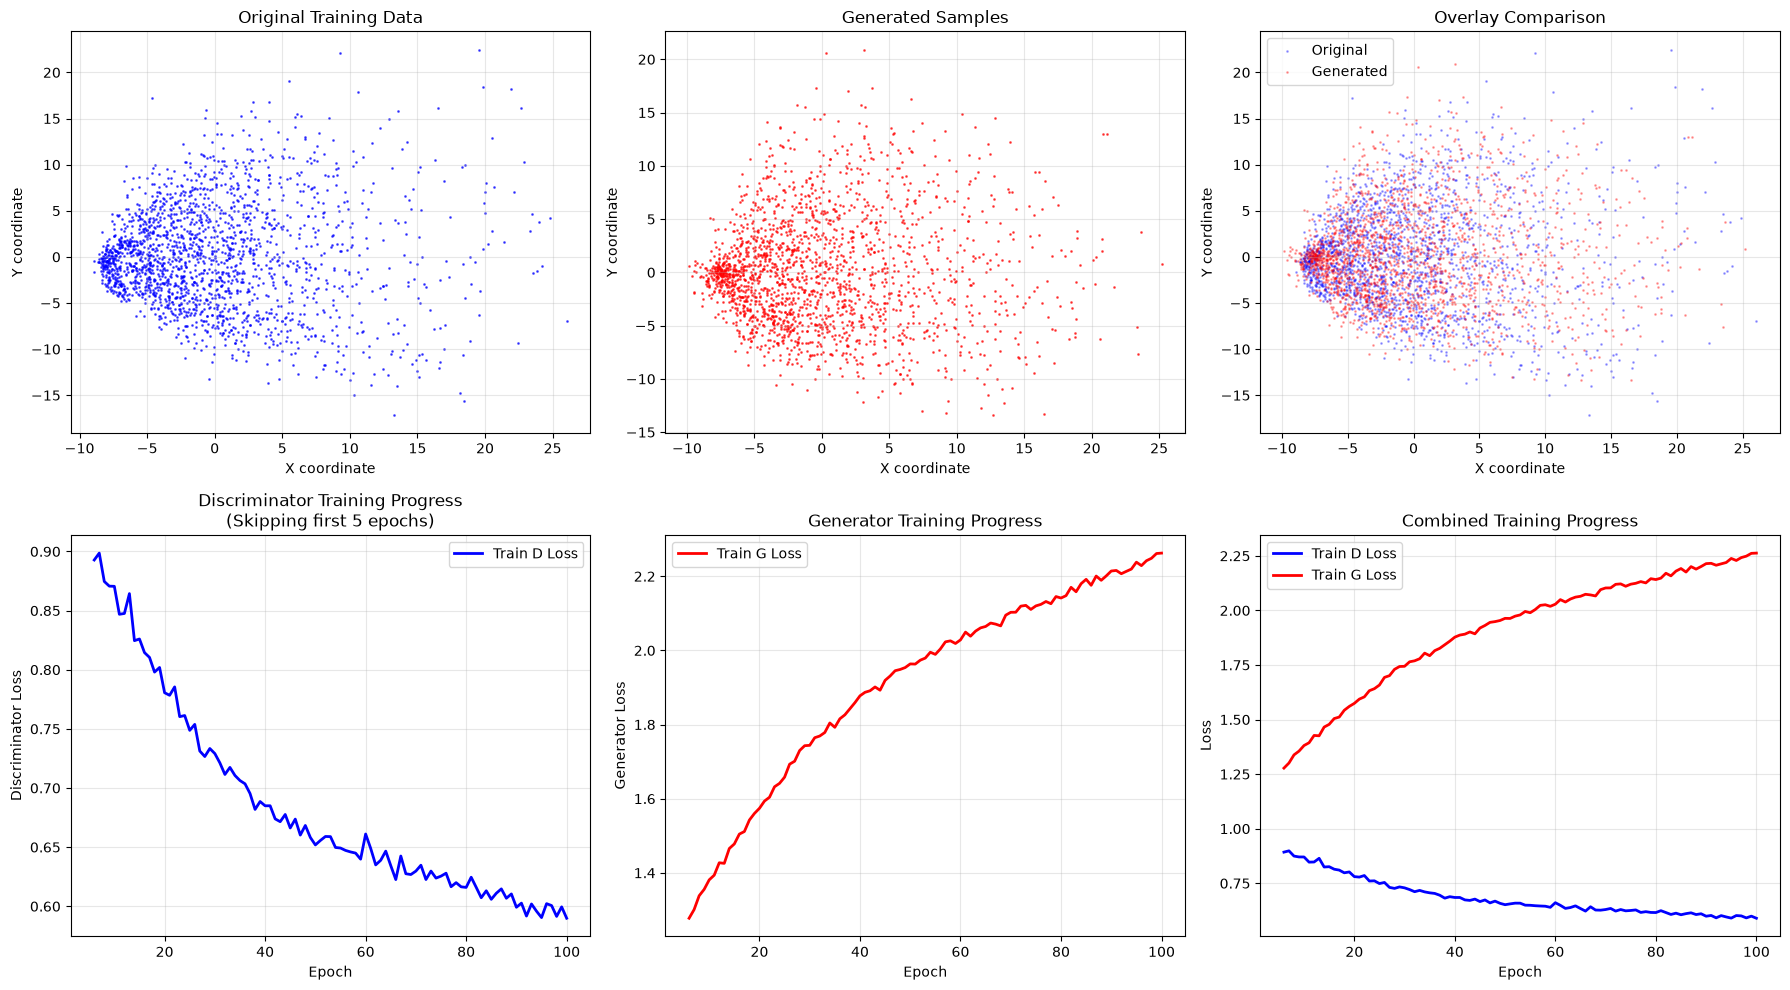

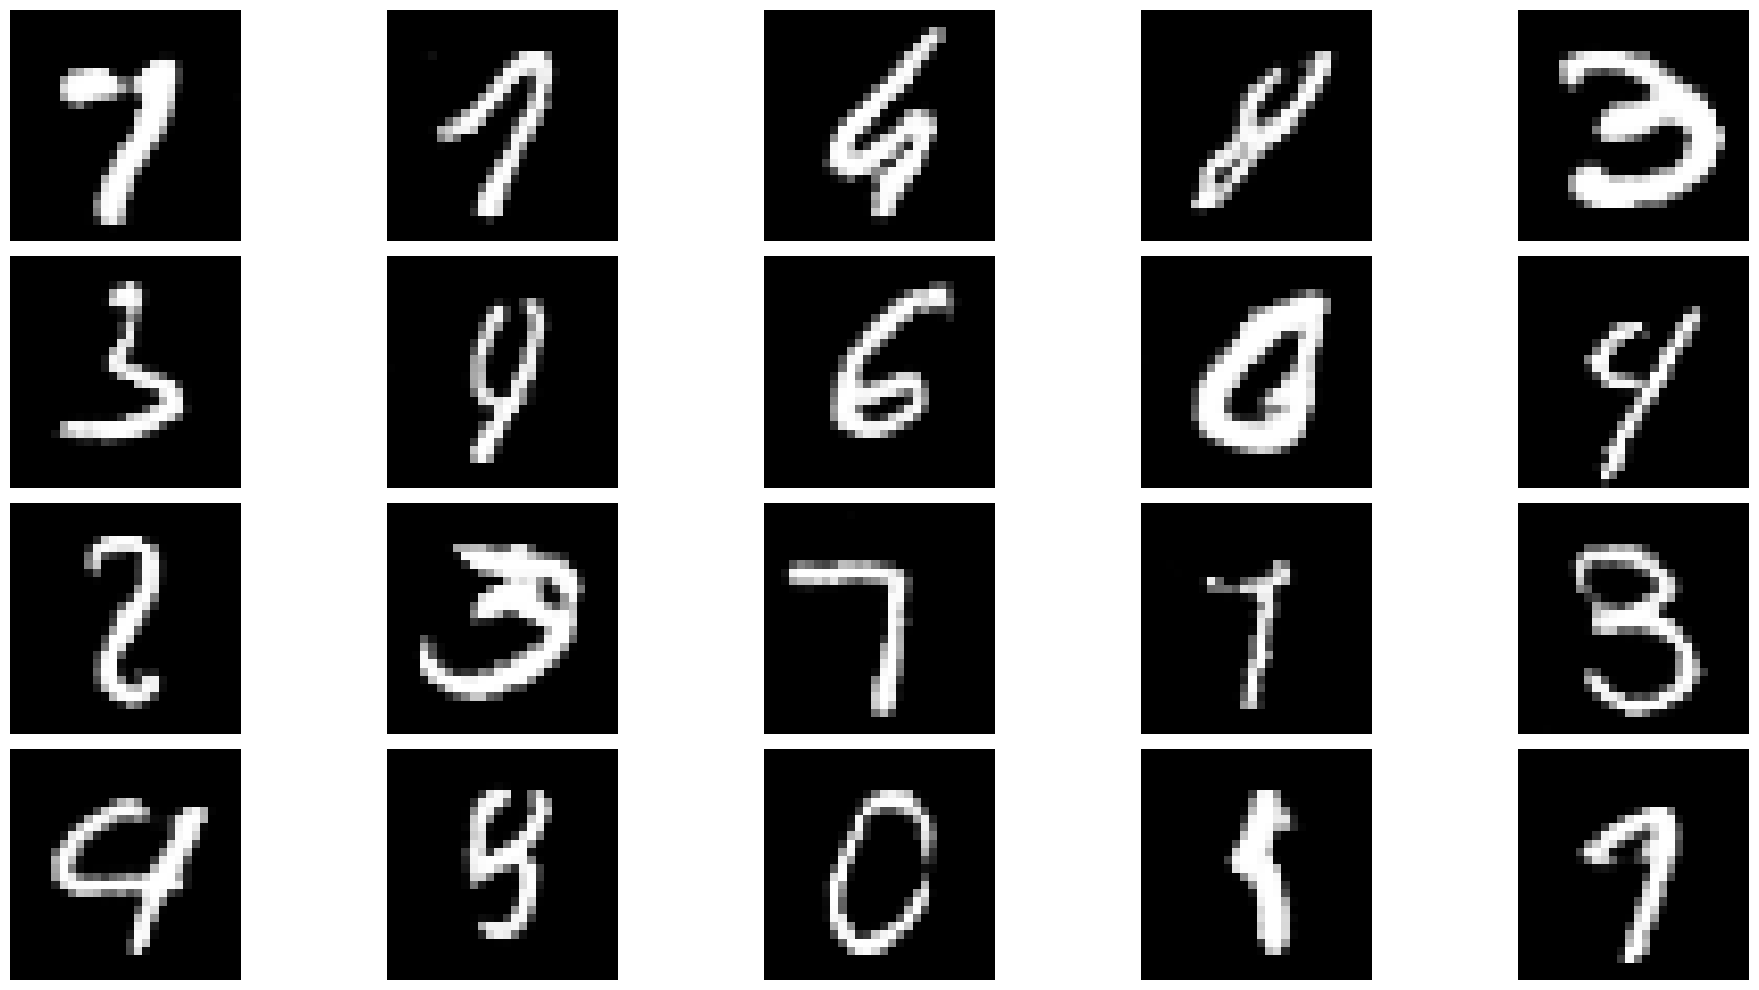

📈 Epoch 100 Summary:
   Train D Loss: 0.5899, Val D Loss: 1.5130
   Train G Loss: 2.2626, Val G Loss: 2.9847

🎉 Training completed!

🎨 Final comprehensive visualization:


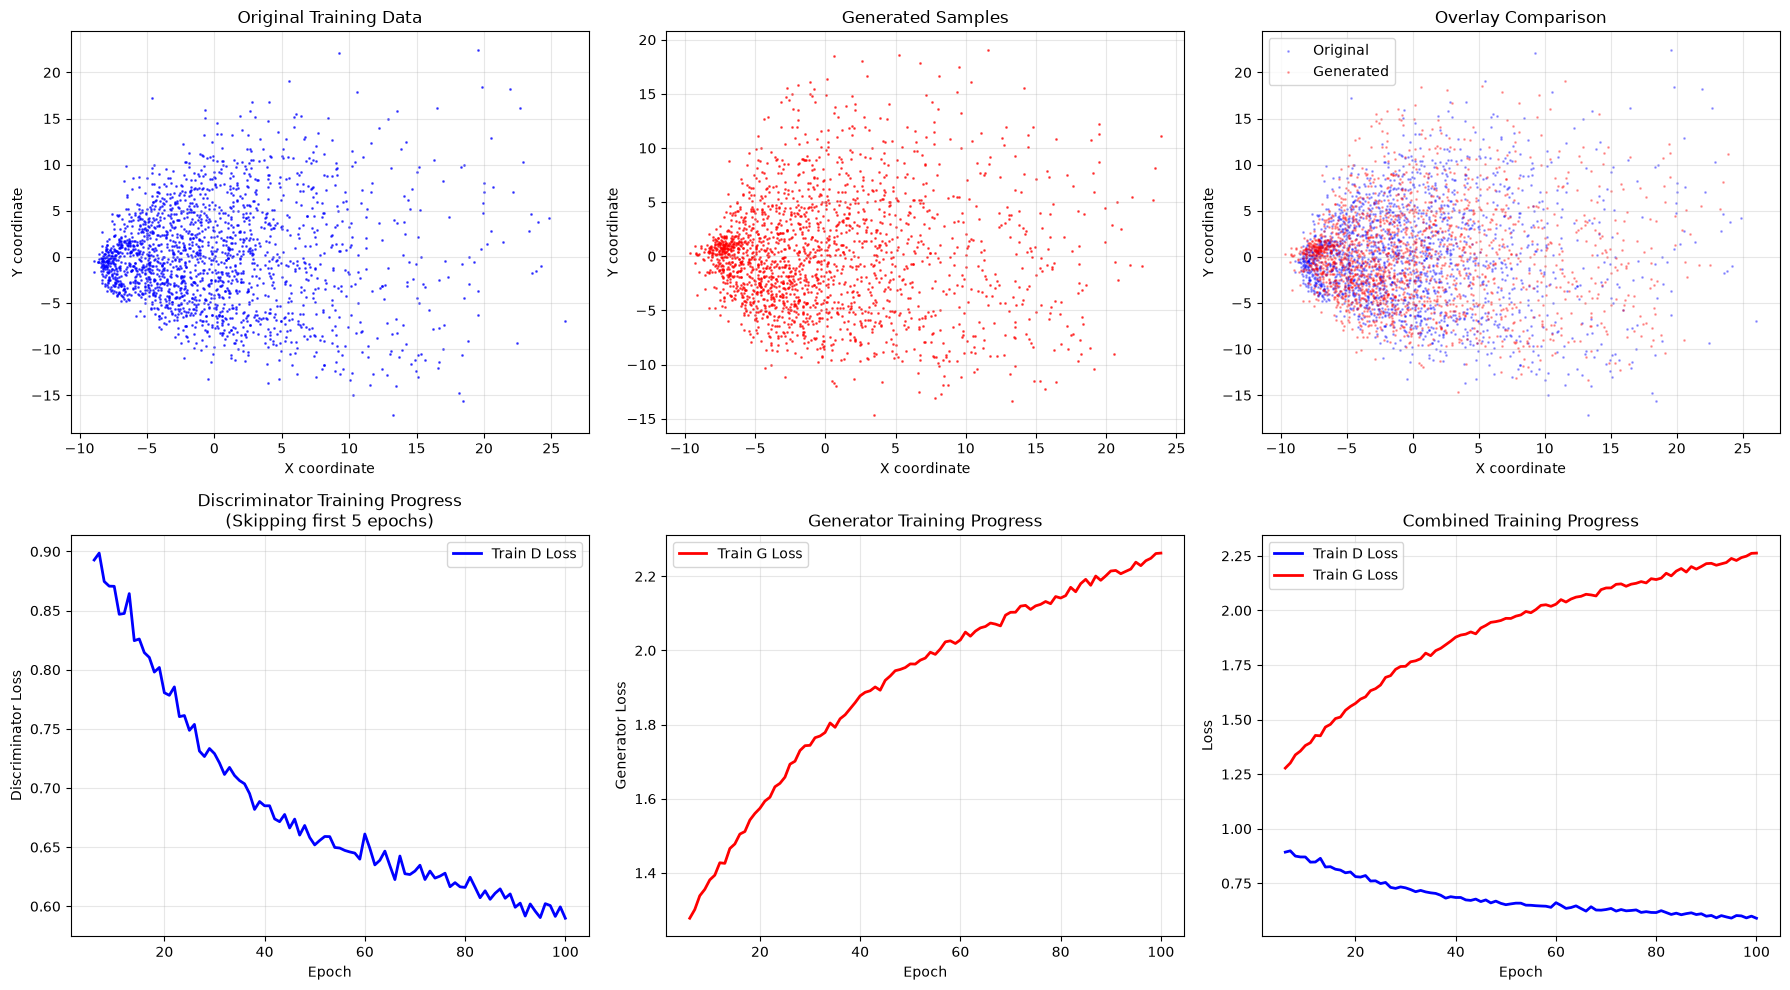

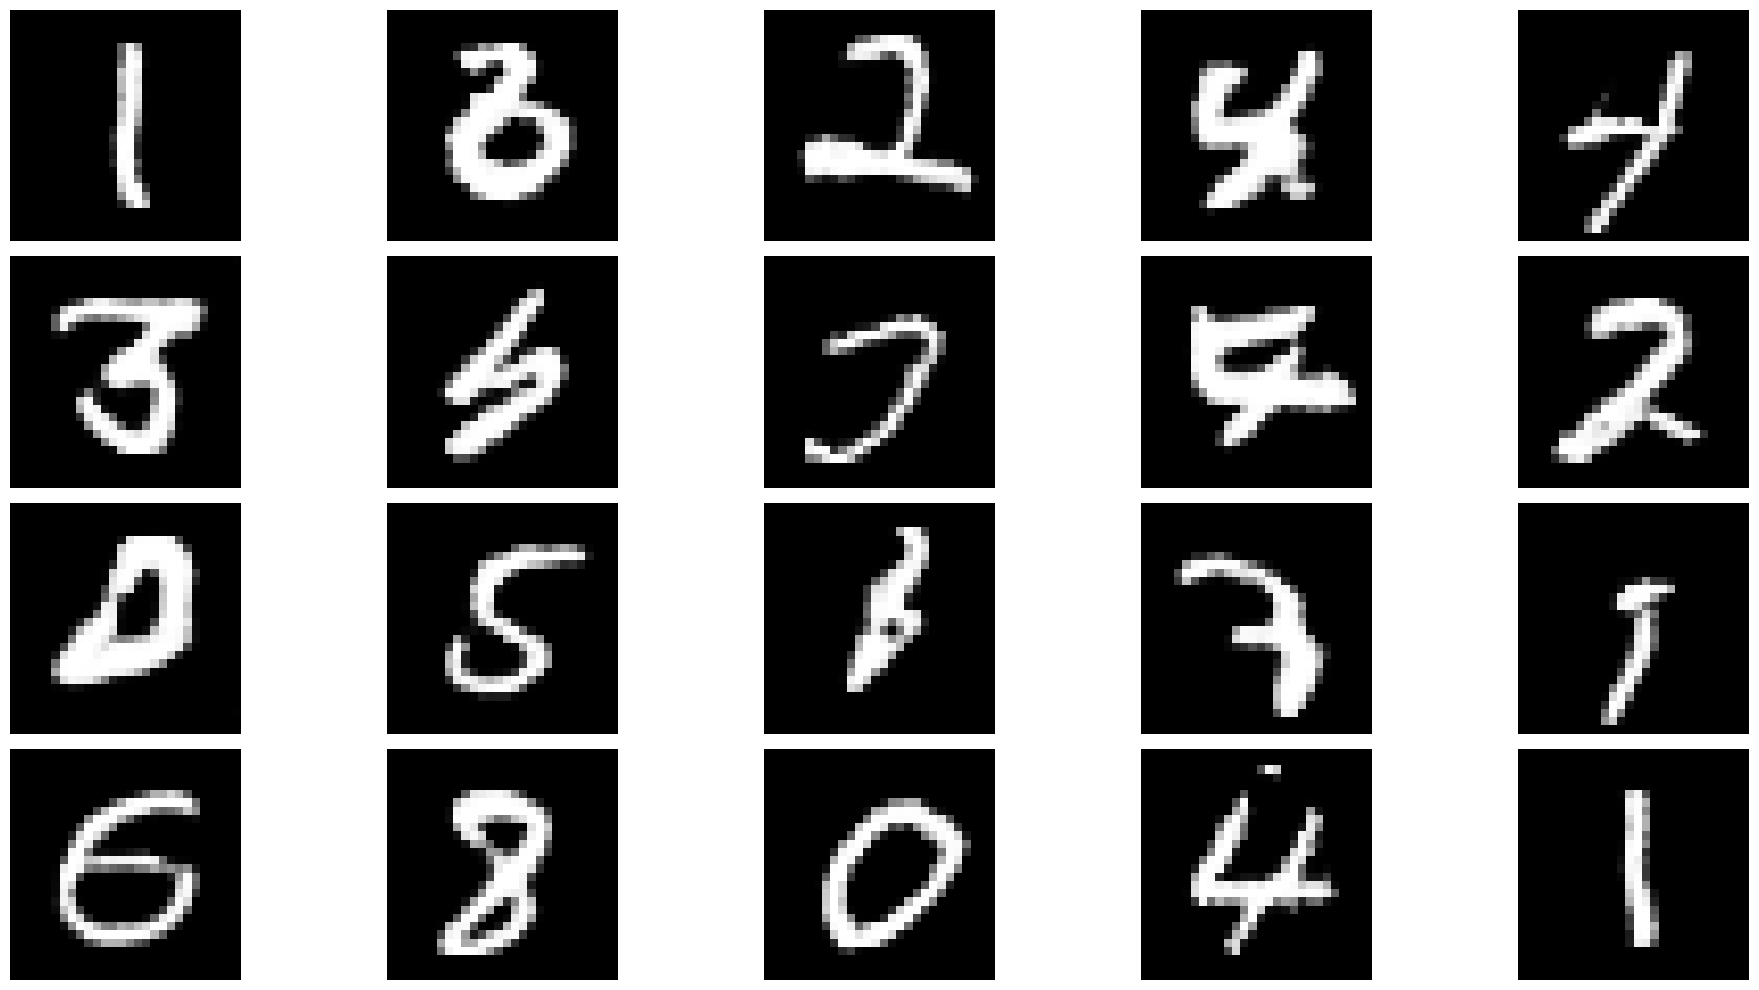

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


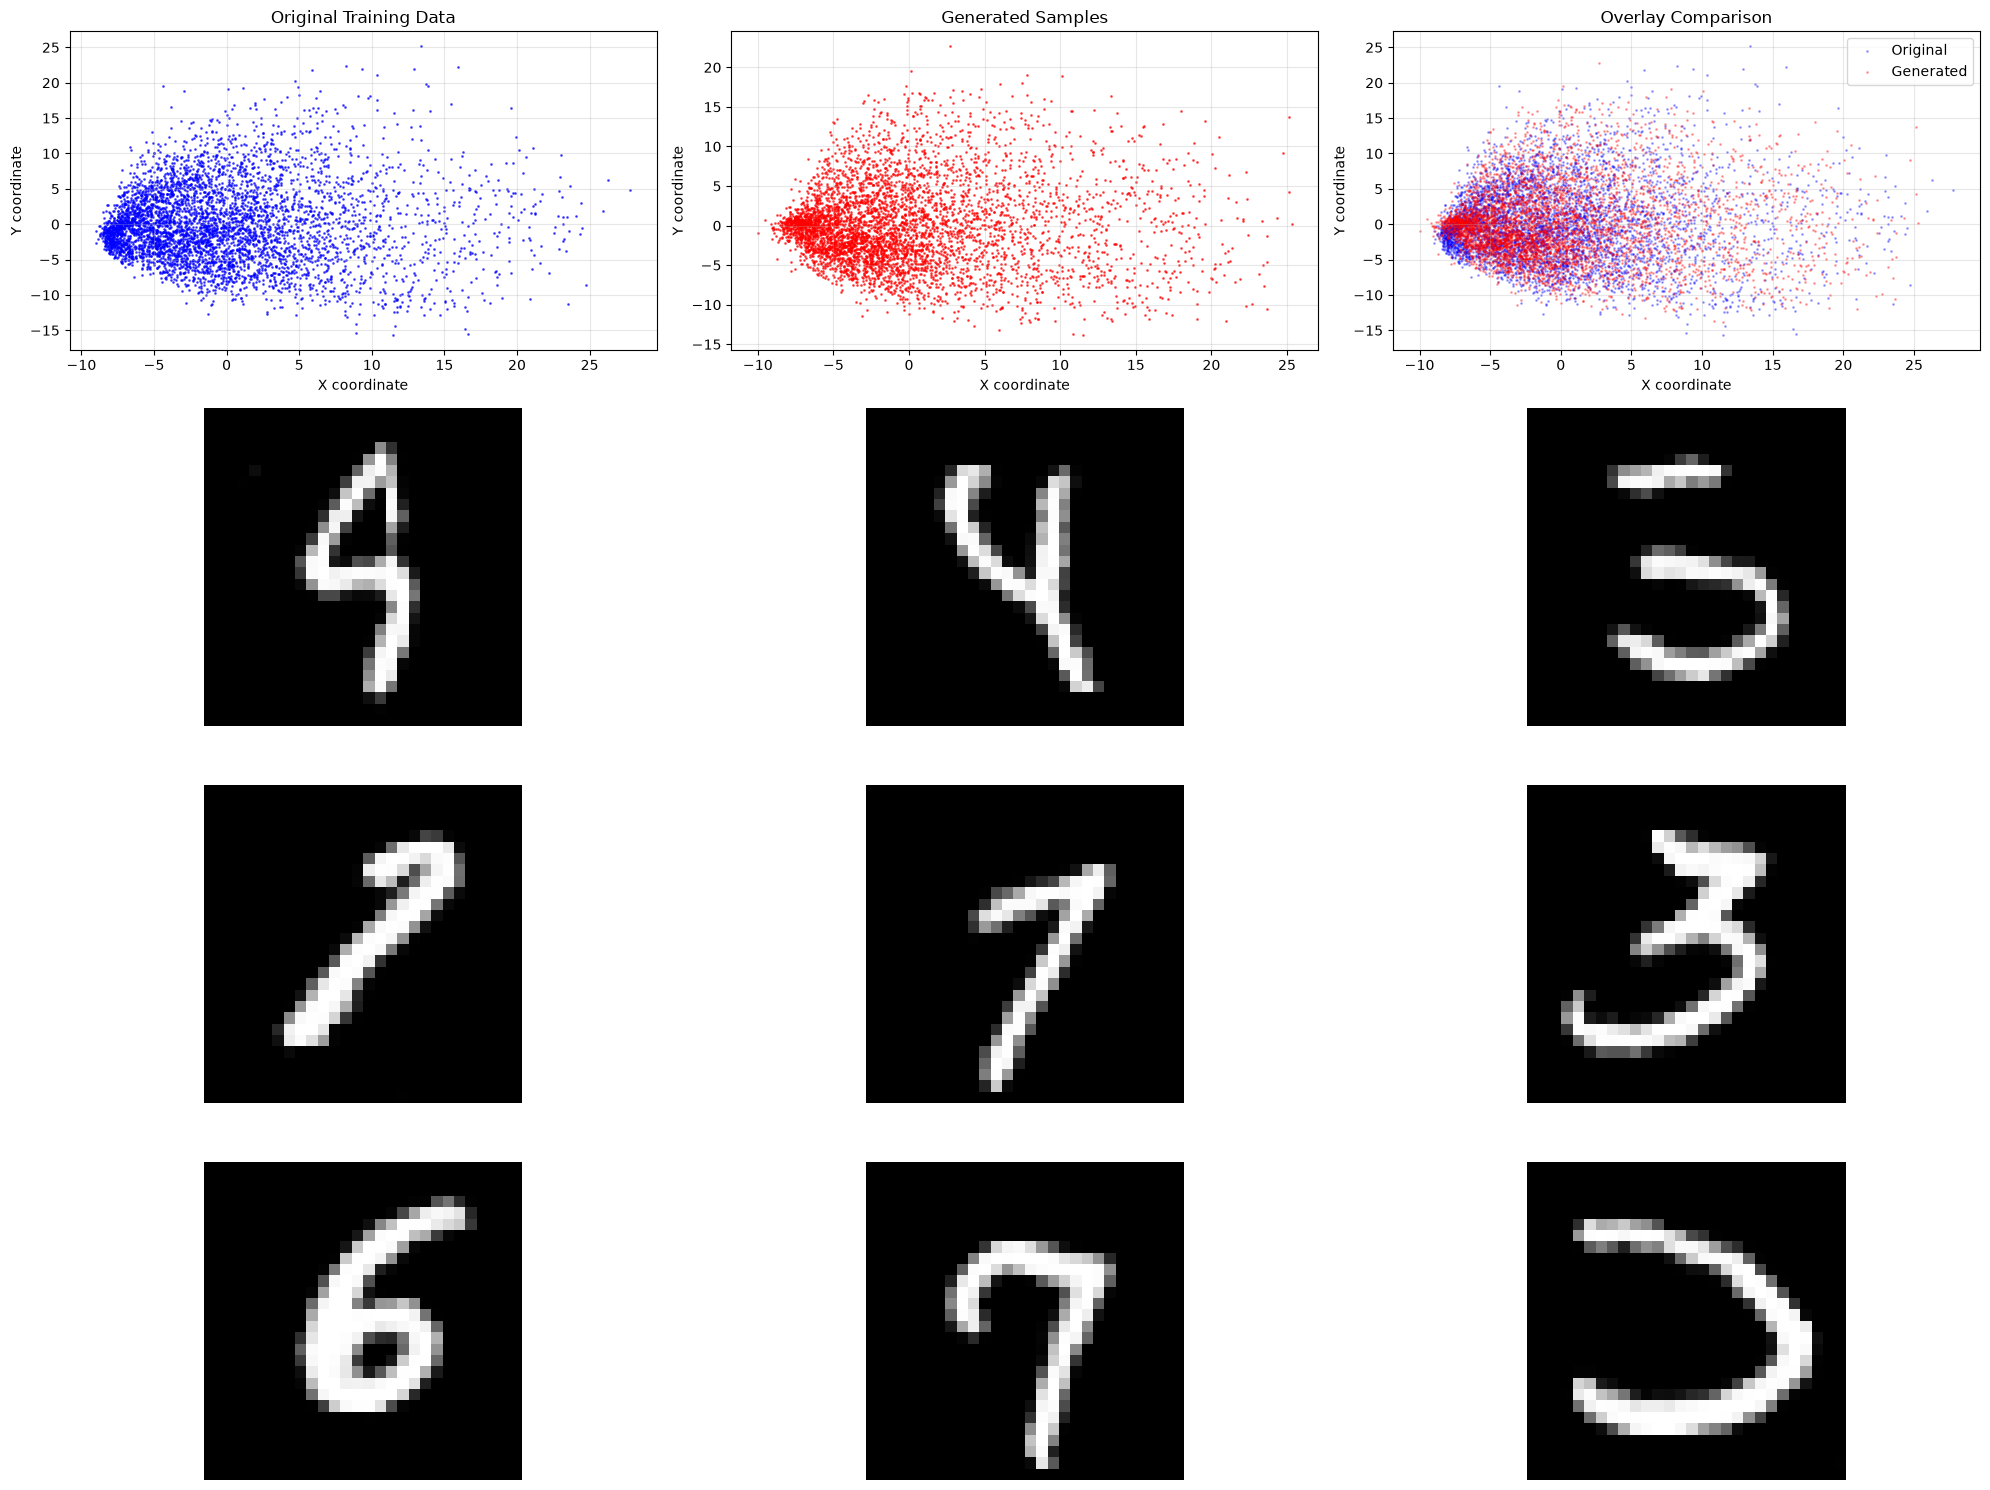

Real data confidence: 0.417
Fake data confidence: 0.117


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
